# Learning a DES-footprint map generator from the supplied simulations

This notebook accompanies [the teaching note](gptg_simulations.pdf). We implement the point-transformed Gaussian method of [Kunhao Zhong and coauthors](https://arxiv.org/abs/2411.04759), fit an initial model to 32 supplied maps, save 64 new four-bin maps with Gaussian shape noise, and measure second- and third-order apertures. **This pilot is not a validated DES covariance model.**

**Thanks to Kunhao Zhong and coauthors for the method, Rafael Gomes for the simulation maps, and the ducc0/HEALPix developers for the transforms and geometry.** This is our implementation and fit, not a supplied author calibration.

The default cells use compact records committed under `tests/gptg_pilot/`. They do not process the full archive. Optional generation and measurement commands appear at the end. Raw generated maps stay under the ignored `chains/gptg_method/maps/` directory.

## How to use this notebook

The note and this notebook form one account. Read the small algebra examples
first, redraw the four frozen figures, and only then analyze saved simulation
measurements. **Running the ordinary teaching cells does not start map generation
or TreeCorr.** Those production programs are in `../../scripts/` and the HPC
submission instructions are in the project README.

The later sections expose the actual analysis calculations as named Python
functions. Their arguments replace command-line flags. Read the comments before
calling one: some need downloaded maps, some need completed HPC measurements,
and GPU checks need MLX on an Apple machine. Outputs go to `chains/`; the frozen
figure inputs in this note are retained so its illustrations remain reproducible.


The downloaded-measurement audit reads saved vectors and sky positions only.
It runs small matrix checks; it does not run TreeCorr or generate maps.

**Laptop and production settings.** The cell after the imports sets `LAPTOP`.
With `LAPTOP = True` the sky tests use NSIDE 1024 and 2048 instead of 2048 and
4096, the physical-power model stops at multipole 2048 instead of 4096, and the
resampling controls stop at 4,000 draws instead of 40,000. Their outputs go to
`chains/gptg_laptop/`, so no production result in `chains/` is overwritten.
`LAPTOP = False` restores the production settings and folders. The saved outputs
of this notebook come from the laptop run. Where the markdown quotes a value that
only the production settings print, it says so.


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import os
# Set these before importing numerical libraries. ducc0 separately gets
# nthreads=4 in the map script; BLAS never gets four workers.
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['VECLIB_MAXIMUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '4'
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import yaml
from IPython.display import Image, display

# Find this project whether Jupyter starts here or at the project root.
PROJECT = Path.cwd().resolve()
while not (PROJECT / 'EXAMPLE_COVARIANCE_PME.ipynb').exists():
    if PROJECT == PROJECT.parent:
        raise FileNotFoundError('Start this notebook within projects/des_3pcf.')
    PROJECT = PROJECT.parent
NOTE = PROJECT / 'notes' / 'gptg_simulations'
RECORDS = PROJECT / 'tests' / 'gptg_pilot'
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

# Production modules live in scripts; covariance algebra is shared with the Eifler note.
import sys
sys.path.insert(0, str(PROJECT / "scripts"))
sys.path.insert(0, str(PROJECT / "notes/covariance_from_simulations"))


## Laptop or production settings

One switch selects the configuration. The laptop values run every cell with two native threads and
well under 16 GB of memory. The production
values are those of the recorded HPC and workstation runs.


In [2]:
# LAPTOP = True: coarser pixels, a shorter multipole range and fewer
# resampled draws. LAPTOP = False: the production settings.
LAPTOP = True
if LAPTOP:
    NSIDE = 1024           # pixels of the high-resolution sky tests
    FINE_NSIDE = 2048      # finer grid of the two-grid comparisons
    LMAX = 2048            # signal cutoff of the physical-power model
    ROUNDTRIP_LMAX = 1024  # cutoff of the band-limited round trip
    DRAW_COUNTS = (500, 1878, 4000)  # resampled draws per control trial
    THREADS = 2            # native threads of transforms, CAMB and cosmolike
    CHAINS = PROJECT / 'chains/gptg_laptop'
else:
    NSIDE = 2048
    FINE_NSIDE = 4096
    LMAX = 4096
    ROUNDTRIP_LMAX = 2048
    DRAW_COUNTS = (500, 1878, 4000, 10000, 40000)
    THREADS = 4
    CHAINS = PROJECT / 'chains'
# No OpenMP library is loaded yet, so CAMB and ducc0 still read this value.
os.environ['OMP_NUM_THREADS'] = str(THREADS)

# Saved inputs are always read from the production folder, never written.
ENSEMBLE = PROJECT / 'chains/gptg_ensemble_15000'

# The laptop folder holds results of one configuration only. Different
# settings raise an error instead of mixing or overwriting results.
SETTINGS = dict(
    nside=NSIDE,
    fine_nside=FINE_NSIDE,
    lmax=LMAX,
    roundtrip_lmax=ROUNDTRIP_LMAX,
    draw_counts=list(DRAW_COUNTS),
)
if LAPTOP:
    CHAINS.mkdir(parents=True, exist_ok=True)
    settings_file = CHAINS / 'settings.yaml'
    if not settings_file.exists():
        settings_file.write_text(yaml.safe_dump(SETTINGS))
    elif yaml.safe_load(settings_file.read_text()) != SETTINGS:
        raise ValueError(f'{settings_file} records other settings; choose another folder.')
print('LAPTOP =', LAPTOP)
print(SETTINGS)
print('Outputs under', CHAINS)


LAPTOP = True
{'nside': 1024, 'fine_nside': 2048, 'lmax': 2048, 'roundtrip_lmax': 1024, 'draw_counts': [500, 1878, 4000]}
Outputs under /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/chains/gptg_laptop


## 1. Inspect the calibration before using it

The transform acts on **convergence**, not separately on the two shear components. Our available input maps contain shear. We therefore fit a *masked, smoothed, noisy reconstruction proxy* as an initial approximation. This distinction is one reason a small quantile-fit residual does not validate the resulting sky model.

Read the recorded input selection, noise amplitudes and transformation family. The bin-two fit uses the paper's four-parameter restriction because an unrestricted initial fit turned over in a tail. Parameters near their fitting bounds also deserve attention.

In [3]:
calibration = yaml.safe_load((RECORDS / 'calibration.yaml').read_text())
generation = yaml.safe_load((RECORDS / 'generation.yaml').read_text())
print('Calibration maps:', len(calibration['source_files']))
print('Generated maps:', generation['count'])
print('NSIDE and maximum multipole:', calibration['nside'], calibration['lmax'])
print('Per-component pixel noise:', calibration['noise_sigma_per_component'])
for source, family in enumerate(calibration['fitted_family'], start=1):
    print('Source', source, ':', family)
print('Parameters are a1, a2, b, x0, t:')
print(np.asarray(calibration['point_parameters_a1_a2_b_x0_t']))

Calibration maps: 32
Generated maps: 64
NSIDE and maximum multipole: 512 1024
Per-component pixel noise: [0.03544957212835064, 0.03845571849948187, 0.038129787831707534, 0.04684877382544602]
Source 1 : five-parameter
Source 2 : four-parameter; b fixed to zero for global monotonicity
Source 3 : five-parameter
Source 4 : five-parameter
Parameters are a1, a2, b, x0, t:
[[ 2.37551585e-01  2.13293612e-01  9.99996434e-01  1.25883628e+00
   4.00000000e+00]
 [ 2.68977167e-02  5.00000002e-03  0.00000000e+00  2.76947383e+00
   4.81012632e-01]
 [ 1.31889354e-02  1.26374845e-02  2.60573386e-06  1.26083202e+00
   4.00000000e+00]
 [ 2.19034250e-01  1.95423544e-01  1.00000000e+00 -3.00000000e+00
   2.00000000e-01]]


## 2. Why a nonlinear point transform also changes correlations

Take two unit Gaussian variables with correlation $\rho$. For a simple centered lognormal transform, define

$$f_i(g)=e^{a_i g-a_i^2/2}-1.$$

The Gaussian exponential identity gives

$$\mathbb E[e^{a_i g_1+a_j g_2}]
=\exp\left[\frac12(a_i^2+a_j^2+2a_ia_j\rho)\right].$$

Multiplying by the two normalization factors cancels $a_i^2/2$ and $a_j^2/2$, leaving $e^{a_ia_j\rho}$. Expanding the product of the two centered transforms then gives

$$\mathbb E[f_i(g_1)f_j(g_2)]
=e^{a_ia_j\rho}-1-1+1=e^{a_ia_j\rho}-1.$$

Thus a desired output correlation is generally **not** the Gaussian input correlation. For the more flexible fitted function, the code evaluates and inverts this relation numerically through Hermite coefficients. The note derives each step. The small example below shows the change even in the simpler analytic case.

In [4]:
a = 0.5
rho = 0.6
# Divide by the lognormal variance to obtain its correlation coefficient.
output_correlation = np.expm1(a*a*rho) / np.expm1(a*a)
# Invert the same relation, recovering the required Gaussian correlation.
recovered = np.log1p(output_correlation*np.expm1(a*a)) / (a*a)
print('Gaussian correlation:', rho)
print('Transformed correlation:', output_correlation)
np.testing.assert_allclose(recovered, rho, atol=1.e-14)
print('Inversion recovers:', recovered)

Gaussian correlation: 0.6
Transformed correlation: 0.5697878894627386
Inversion recovers: 0.6000000000000001


## 3. A footprint index is a sky address

A saved map has shape `(4, 2, 369190)`: four source bins, two shear components and retained pixels. Entry `map[i,c,j]` belongs to full-sky pixel `indices_512[j]`. The last axis is not a rectangular image.

The pilot uses the RING ordering supported by the earlier geometric footprint check. A second-component sign diagnostic favors the current convention, but producer confirmation is still needed for sign-sensitive third moments. Generating convergence on the sphere, converting it to shear, and only then selecting footprint pixels retains the intended large-scale spatial correlations.

In [5]:
number_of_pixels = generation['shape'][-1]
bytes_per_map = 4 * 2 * number_of_pixels * 8  # float64 payload
print('Payload per map [MB]:', bytes_per_map/1.e6)
print('64-map payload [GB]:', 64*bytes_per_map/1.e9)
print('10000-map payload [GB]:', 10000*bytes_per_map/1.e9)
timing = np.loadtxt(fname=RECORDS / 'generation_timing.txt')
print('Median generation/save/aperture seconds:', np.median(timing, axis=0))
print('Median total seconds:', np.median(timing.sum(axis=1)))

Payload per map [MB]: 23.62816
64-map payload [GB]: 1.51220224
10000-map payload [GB]: 236.2816
Median generation/save/aperture seconds: [4.25585071e+00 4.22324997e-03 6.79079152e-03]
Median total seconds: 4.267709020990878


## 4. Correct a noisy aperture square and cube

A filtered aperture is $A=s+n$, where $s$ is fixed while we average over noise. Assume $\mathbb E[n]=0$, $\mathbb E[n^2]=v$ and zero third noise moment. Expanding the square gives

$$A^2=s^2+2sn+n^2.$$

Averaging each term gives

$$\mathbb E[A^2\mid s]=s^2+2s(0)+v=s^2+v.$$

Subtract the known variance:

$$\mathbb E[A^2-v\mid s]=s^2.$$

For the cube, multiply the three factors before averaging:

$$A^3=s^3+3s^2n+3sn^2+n^3.$$

Therefore

$$\mathbb E[A^3\mid s]=s^3+3s^2(0)+3sv+0=s^3+3sv.$$

The signal is unknown, but $\mathbb E[A\mid s]=s$. Multiplying that identity by $3v$ and subtracting yields

$$\mathbb E[A^3-3vA\mid s]=s^3+3sv-3vs=s^3.$$

**This aperture correction is different from correcting the square of a noisy covariance matrix in Eifler's expansion.** Neither operation removes the random scatter of a noisy observation.

In [6]:
from scipy.special import roots_hermitenorm

# Gaussian quadrature integrates the low-degree polynomial exactly,
# making a coefficient/sign mistake visible without Monte Carlo noise.
nodes, weights = roots_hermitenorm(n=12)
weights = weights / np.sqrt(2*np.pi)
signal = 0.2
noise_variance = 0.07
aperture = signal + np.sqrt(noise_variance)*nodes
raw_second = weights @ aperture**2
corrected_second = weights @ (aperture**2-noise_variance)
raw_third = weights @ aperture**3
corrected_third = weights @ (aperture**3-3*noise_variance*aperture)
print('Square: raw, corrected, target:', raw_second, corrected_second, signal**2)
print('Cube: raw, corrected, target:', raw_third, corrected_third, signal**3)
np.testing.assert_allclose(corrected_second, signal**2, atol=1.e-14)
np.testing.assert_allclose(corrected_third, signal**3, atol=1.e-14)

Square: raw, corrected, target: 0.11000000000000001 0.04000000000000002 0.04000000000000001
Cube: raw, corrected, target: 0.05000000000000002 0.008000000000000007 0.008000000000000002


## 5. Carry the correction to mixed source bins

There are three ways to pair two noise factors in a cubic product. If $V_{ij}$ is their covariance, the corrected product is

$$T_{ijk}=A_iA_jA_k-V_{ij}A_k-V_{ik}A_j-V_{jk}A_i.$$

The note expands all eight terms of the original product and cancels the three extra expectations. In our initial model, different source bins have independent noise. For `(1,1,2)`, only $V_{11}A_2$ remains; for `(1,2,3)`, no pair subtraction remains. The same-bin case has all three pairings and reduces to the factor of three above.

The filter noise is calculated from **squared pixel weights**, not fitted from the measured cube. We retain one variance per source, radius and center. The next cells inspect the resulting raw/corrected measurements for all 60 tomographic rows. For the supplied maps, the assumed pixel-noise prescription is approximate; these corrections do not establish the published estimator.

In [7]:
rows = np.loadtxt(fname=RECORDS / 'tomographic_rows.txt', dtype=int)
raw = np.loadtxt(fname=RECORDS / 'generated_tomographic_raw.txt')
corrected = np.loadtxt(fname=RECORDS / 'generated_tomographic_corrected.txt')
filter_variance = np.loadtxt(fname=RECORDS / 'aperture_noise_variance.txt')
print('Rows: order, radius, source i, source j, source k:')
print(rows[:3])
print('Maps by measurements:', raw.shape)
print('Filter-noise rows by centers:', filter_variance.shape)
# Row 10 is the first cubic row: source 1 three times, at 30 arcminutes.
row = 10
print('Selected cubic row:', rows[row])
print('Mean raw cube:', raw[:, row].mean())
print('Mean corrected cube:', corrected[:, row].mean())
# Distinct bins have no correction under the stipulated noise model.
distinct = (rows[:,0] == 3) & (rows[:,2] < rows[:,3]) & (rows[:,3] < rows[:,4])
np.testing.assert_array_equal(raw[:, distinct], corrected[:, distinct])

Rows: order, radius, source i, source j, source k:
[[ 2 30  1  1  0]
 [ 2 30  1  2  0]
 [ 2 30  1  3  0]]
Maps by measurements: (64, 60)
Filter-noise rows by centers: (8, 64)
Selected cubic row: [ 3 30  1  1  1]
Mean raw cube: 4.1467049172298355e-10
Mean corrected cube: 3.630943045092821e-10


## 6. Test the maps after all transformations

Fitting the central proxy quantiles is only a starting step. We must remeasure spectra, distributions, means and covariance after applying the same footprint, noise and measurement. The figures below come from the saved measurements, and their adjacent plot scripts redraw from text alone.

The spectra compare 64 generated maps with the 32 calibration maps. The covariance comparison uses the same **16 raw same-source moments** as the complete 15,997-vector supplied-map diagnostic. It does not silently switch to the 60 corrected rows. The starting fit reused part of the reference ensemble, so these are consistency diagnostics, not independent validation p-values.

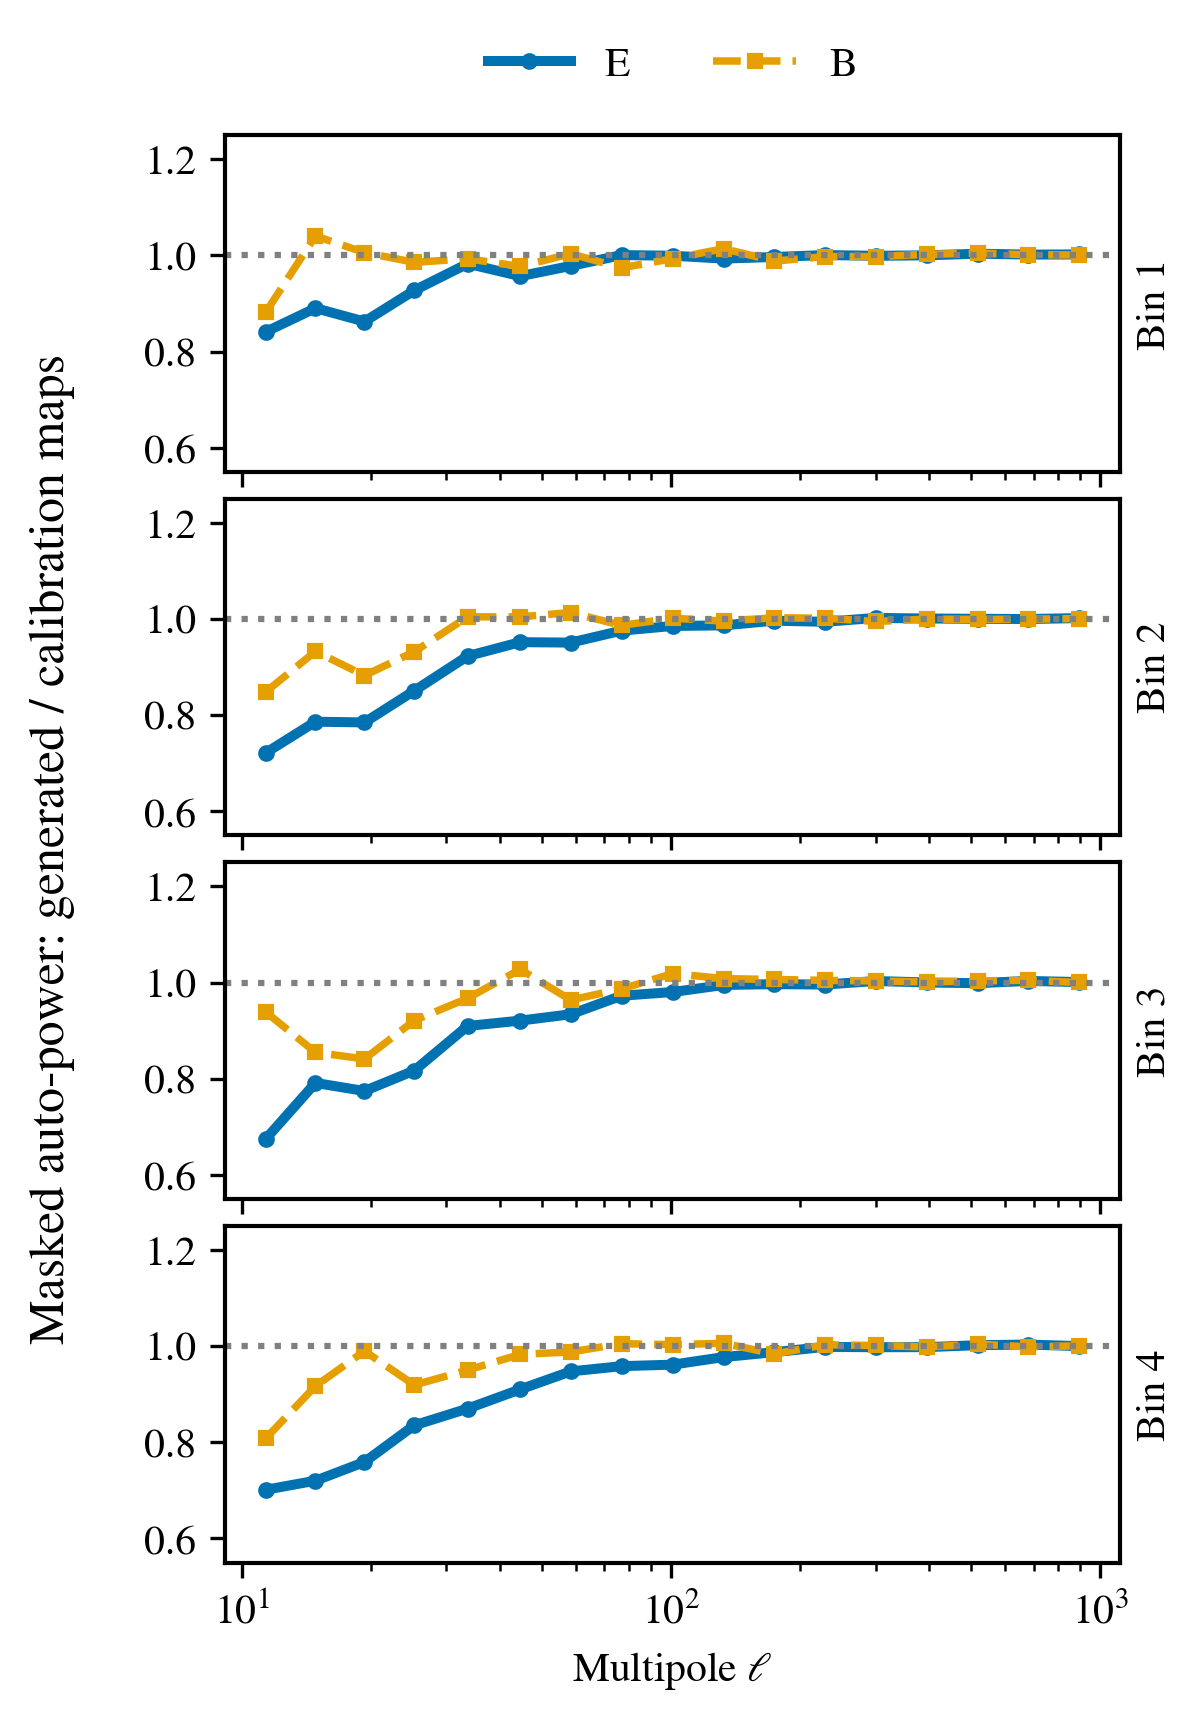

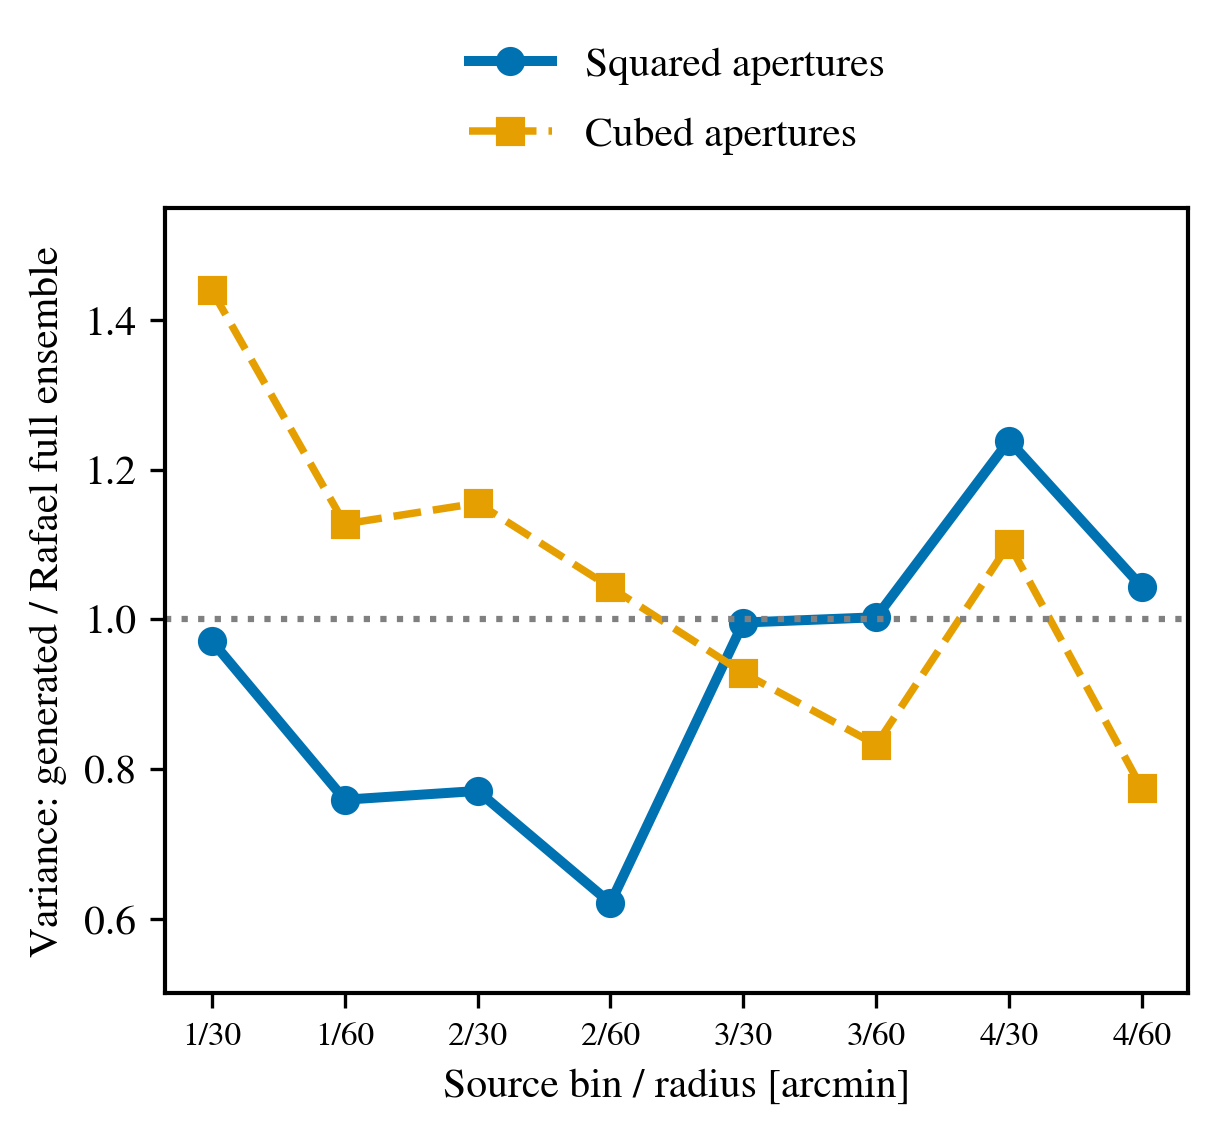

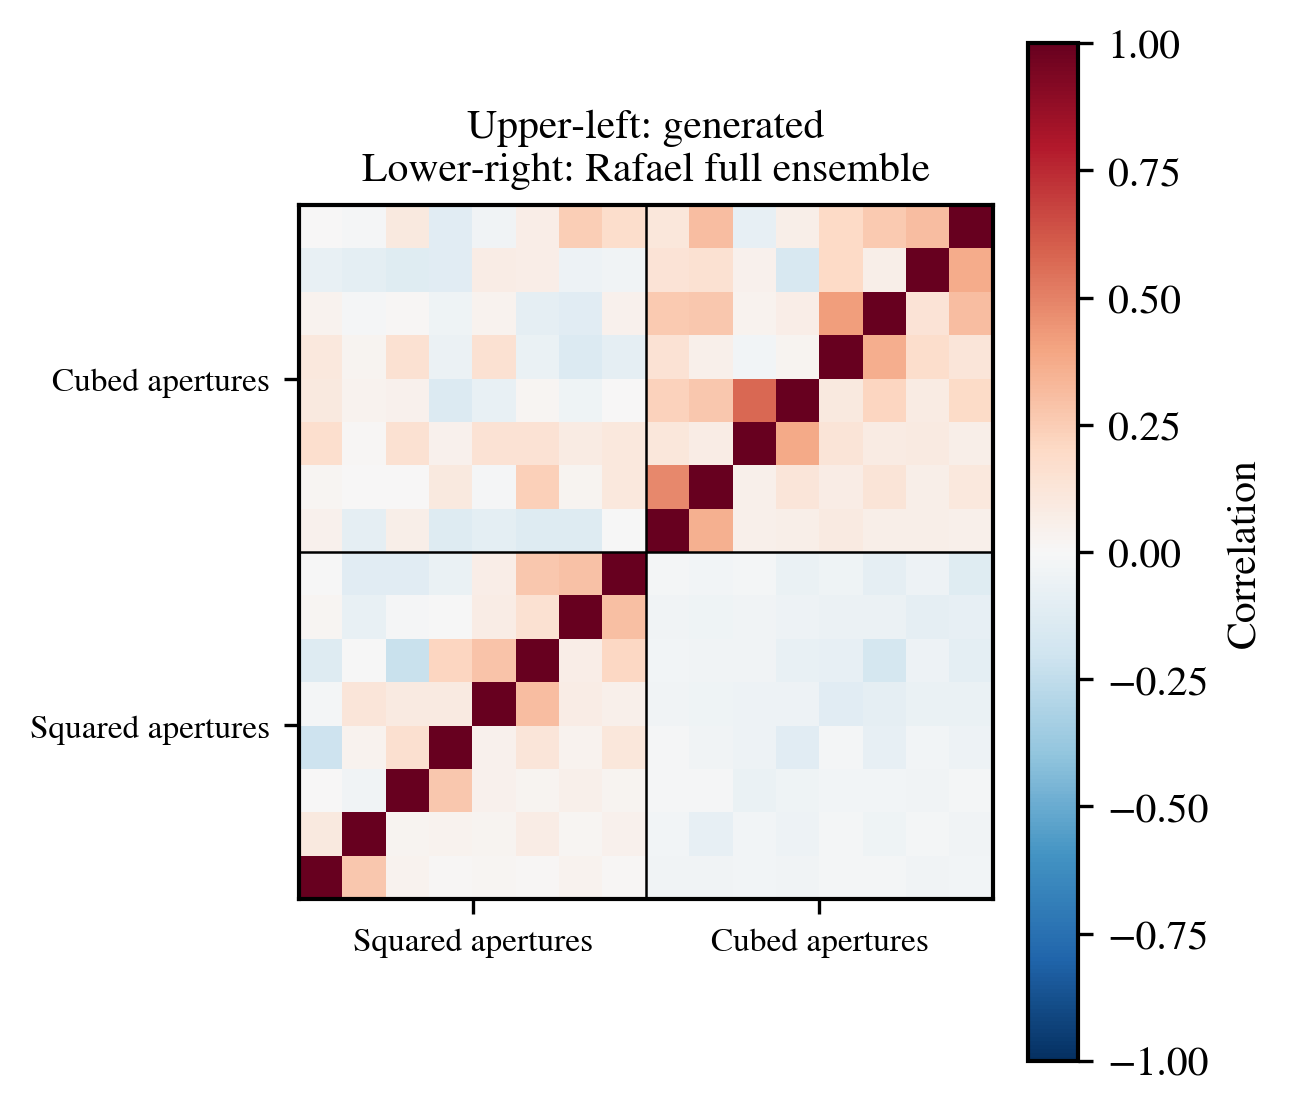

Variance-ratio range: 0.6207341560973392 1.4397128153454377
Largest absolute correlation difference: 0.332108476048442
Gaussian benchmark for 64-map variance scatter: 0.1781741612749496


In [8]:
for figure in ('spectra', 'variance', 'correlation'):
    display(Image(filename=str(NOTE / 'plots' / figure / f'{figure}.png'), width=650))

reference = np.loadtxt(
    fname=PROJECT / 'tests/covariance_map_comparison/all_maps_covariance.txt',
)
generated = np.loadtxt(fname=RECORDS / 'generated_covariance.txt')
ratio = np.diag(generated)/np.diag(reference)
reference_scale = np.sqrt(np.diag(reference))
generated_scale = np.sqrt(np.diag(generated))
reference_correlation = reference/reference_scale[:,None]/reference_scale[None,:]
generated_correlation = generated/generated_scale[:,None]/generated_scale[None,:]
print('Variance-ratio range:', ratio.min(), ratio.max())
print('Largest absolute correlation difference:',
      np.max(np.abs(generated_correlation-reference_correlation)))
print('Gaussian benchmark for 64-map variance scatter:', np.sqrt(2/63))

## 7. What sixth order does on a measured-vector population

We need known truth to test algebra. The continuous map model does not provide an exact covariance for these measured statistics. Instead, define a discrete population consisting of all 64 saved vectors, each with probability $1/64$. Select four joint second-/third-order rows. Its covariance uses denominator **64**, because the list defines the whole population. Covariances estimated from independent samples drawn from it use **$N-1$**.

Each experiment chooses 128 or 512 list members independently *with replacement*. We repeated this 8,192 times. These are independent experiments conditional on the list, **not new independent physical skies**. A fixed positive reference is chosen before resampling. The error compares estimated precision with the exact inverse of this specified population covariance.

The distinct-pair method needs independence and suitable finite moments, but not a Gaussian distribution. The Wishart formulas are tested deliberately even though these measurements are not Gaussian. Unbiasedness for a truncated polynomial does not imply unbiasedness for the full inverse or its inverse covariance.

Exactly defined discrete-population covariance:
[[ 1.          0.0201648   0.0467967  -0.07676721]
 [ 0.0201648   1.         -0.12952458 -0.04906478]
 [ 0.0467967  -0.12952458  1.          0.13601114]
 [-0.07676721 -0.04906478  0.13601114  1.        ]]
128 draws, distinct-pair RMS at orders 2,4,6: [0.19427558 0.22626533 0.26736764]
512 draws, distinct-pair RMS at orders 2,4,6: [0.15818393 0.11648588 0.13001479]


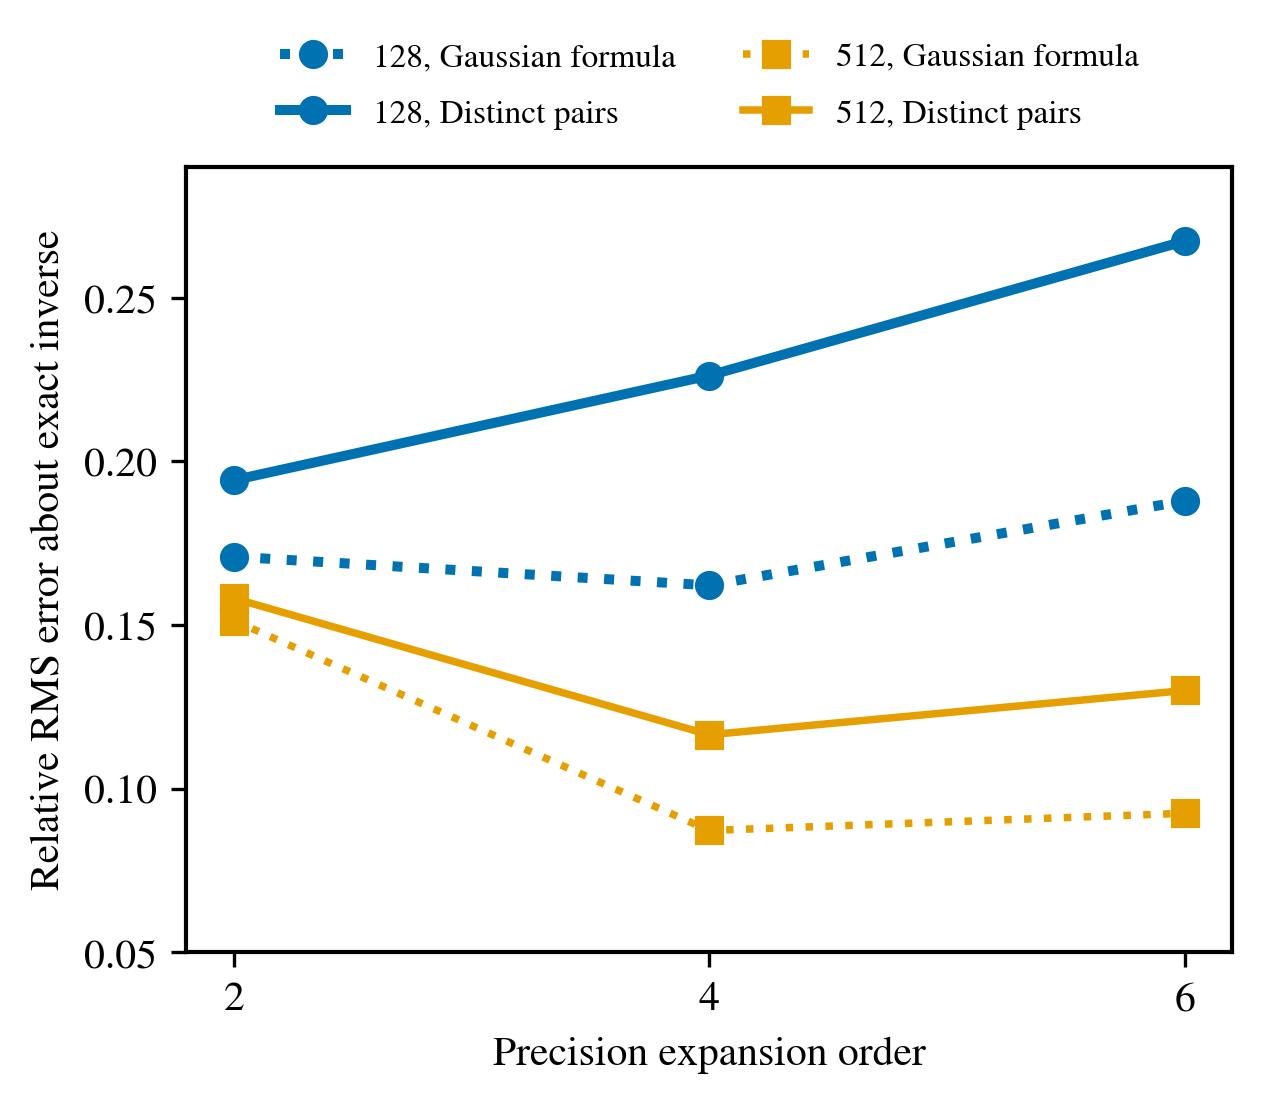

In [9]:
population = np.loadtxt(fname=RECORDS / 'measurement_population.txt')[:, [0,6,8,14]]
# Fix the unit conversion using the stipulated full population.
standardized = (population-population.mean(axis=0))/population.std(axis=0)
true_covariance = standardized.T @ standardized / len(standardized)
print('Exactly defined discrete-population covariance:')
print(true_covariance)
summary = np.loadtxt(fname=RECORDS / 'gptg_empirical_summary.txt')
# Column 4 is relative RMS error about the exact inverse. Column 3
# instead measures error about the finite polynomial target.
for count in (128,512):
    selected = summary[(summary[:,0] == count) & (summary[:,1] >= 3)]
    print(count, 'draws, distinct-pair RMS at orders 2,4,6:', selected[:,4])
display(Image(filename=str(NOTE / 'plots/precision/precision.png'), width=650))

More draws reduce scatter. In this experiment, 512 draws make fourth order useful, but sixth order still has higher RMS error. This is evidence against choosing the largest available order by default. Neither resampling nor an arbitrarily large generator ensemble removes uncertainty or missing physics in the calibration.

## 9. What to improve before using thousands of additional mocks

The immediate physical work is a forward calibration of the masked power and reconstructed distributions, a checked noise/weight model, confirmation of shear conventions, convergence with harmonic range, and measurement of the intended published estimator. The existing coarse aperture comparisons are useful diagnostics, not that final matching. Parameter uncertainty in the fitted generator also matters: infinitely many draws from an uncertain model do not yield infinitely precise knowledge of the N-body covariance.

The separate [precision-expansion note](../covariance_from_simulations/covariance_from_simulations.pdf) contains the full second-to-sixth-order algebra and Gaussian/lognormal tests. The [covariance comparison note](../covariance_comparison/covariance_comparison.pdf) compares the same complete supplied ensemble with the same complete ensemble, and separately examines matched released DES bins.

## 10. Float32 files and independent validation

The 64-map rounding test compares float32 storage with float64 storage while keeping arithmetic in float64. New ensemble files use float32 (about 177 GB for 15,000 maps). The small original pilot remains float64 as a precision reference.

The larger run has **10,000 comparison maps plus 5,000 new validation maps**. It is still running; the cells below do not claim its results. All comparison maps enter both the direct and Eifler estimates. Validation does not choose the reference or expansion order.

For a fixed positive precision, use the score

$$J(\Psi)=\operatorname{tr}(\Psi C_*)-\log\det\Psi.$$

Its expectation is minimized at the true inverse covariance even for non-Gaussian vectors with finite covariance. The note proves this by diagonalizing $C_*^{1/2}\Psi C_*^{1/2}$. On independent validation data, replace $C_*$ by its unbiased sample covariance **without inverting it**. Score differences therefore do not require the direct inverse to be truth. The next small known-covariance example checks the target numerically.

In [10]:
print((RECORDS / 'float32_storage_check.txt').read_text())
true_covariance = np.array([[2., .3], [.3, 1.]])
true_precision = np.linalg.solve(a=true_covariance, b=np.eye(2))
true_score = np.trace(true_precision @ true_covariance)
true_score -= np.linalg.slogdet(true_precision)[1]
for factor in (0.5, 1., 1.5):
    candidate = factor*true_precision
    score = np.trace(candidate @ true_covariance)
    score -= np.linalg.slogdet(candidate)[1]
    expected_difference = 2*(factor-1.-np.log(factor))
    np.testing.assert_allclose(score-true_score, expected_difference, atol=1.e-14)
    print('Precision multiplier, excess expected score:', factor, score-true_score)
print('The minimum occurs at the known true precision in this worked example.')

max_absolute_shear_rounding 8.57983639690473865e-09
max_moment_change_in_its_single_map_standard_deviation 1.19411115907004286e-07
max_joint_covariance_weighted_vector_change 2.56353941029503208e-07
max_fractional_variance_change 1.49890324596668734e-08
max_relative_covariance_eigendirection_change 5.25167417506345957e-08
max_relative_precision_eigendirection_change 5.25167390685865598e-08

Precision multiplier, excess expected score: 0.5 0.3862943611198908
Precision multiplier, excess expected score: 1.0 0.0
Precision multiplier, excess expected score: 1.5 0.18906978378367123
The minimum occurs at the known true precision in this worked example.


## Redraw the figures from their numerical records

These four cells read small text tables, not maps. The spectrum plot compares
the masked observables; the variance plot compares diagonal covariance entries;
the correlation plot removes units; the precision plot tests expansion order.
A match in one plot does not imply a match in the others. In particular, matching
variance alone does not establish a correct inverse covariance.

Each cell states its input directory and saves the same PDF/PNG used by the note.
The plotting arithmetic is here so the student can inspect each normalization.


### Spectra comparison

Read the text records first, form the plotted statistic, then label its units.

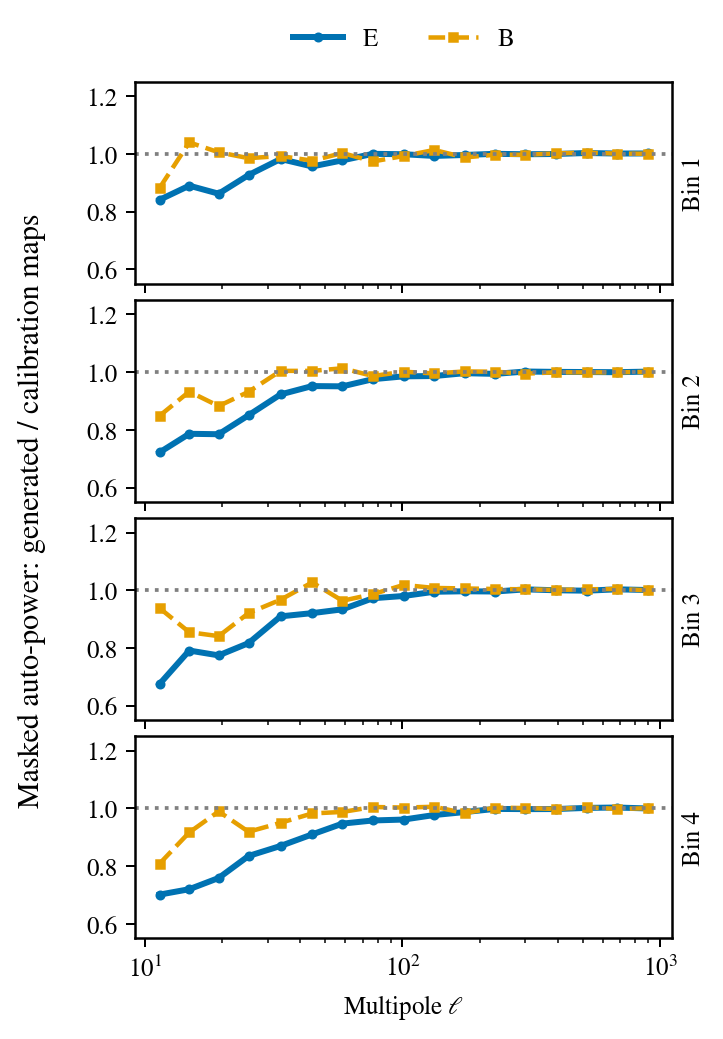

In [11]:
"""Redraw the pilot comparison using only the adjacent text records.

The tables are frozen outputs of the map/precision scripts in the note.
No map loading or fit is performed here. See the note for their assumptions.
"""
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
folder = NOTE / "plots/spectra"

data = np.loadtxt(fname=folder / 'data.txt')
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(4.2, 6.1), sharex=True)
fig.subplots_adjust(hspace=.08, top=.89, left=.18, right=.89)
for source, ax in enumerate(axes):
    for parity in (0, 1):
        rows = data[(data[:, 2] == source) & (data[:, 3] == source)
                    & (data[:, 4] == parity)]
        ell = np.sqrt(rows[:, 0]*rows[:, 1])
        ax.plot(ell, rows[:, 6]/rows[:, 5], color=['#0072B2','#E69F00'][parity],
                linewidth=[2.4,1.8][parity], marker=['o','s'][parity],
                markersize=3, linestyle=['-','--'][parity], label=['E','B'][parity])
    ax.axhline(y=1., color='gray', linestyle=':')
    ax.set_ylim(bottom=.55, top=1.25)
    ax.set_xscale('log')
    ax.set_ylabel(f'Bin {source+1}')
    ax.yaxis.set_label_position('right')
legend = axes[0].legend(loc='lower center', bbox_to_anchor=(.5, 1.04),
                       ncol=2, frameon=False)
fig.supylabel('Masked auto-power: generated / calibration maps', x=.025)
axes[-1].set_xlabel(r'Multipole $\ell$')
fig.canvas.draw()
assert not legend.get_window_extent().overlaps(axes[0].get_window_extent())
NAME = 'spectra.pdf'

fig.savefig(fname=folder / NAME, dpi=300)
fig.savefig(fname=folder / NAME.replace('.pdf', '.png'), dpi=300)
plt.show()
plt.close(fig)


### Variance comparison

Read the text records first, form the plotted statistic, then label its units.

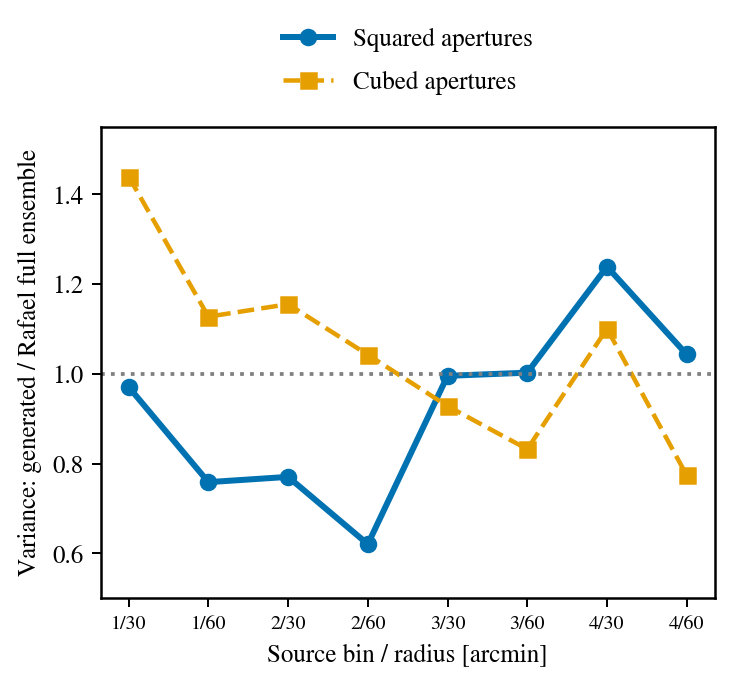

In [12]:
"""Redraw the pilot comparison using only the adjacent text records.

The tables are frozen outputs of the map/precision scripts in the note.
No map loading or fit is performed here. See the note for their assumptions.
"""
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
folder = NOTE / "plots/variance"

reference = np.loadtxt(fname=folder / 'reference.txt')
generated = np.loadtxt(fname=folder / 'generated.txt')
ratio = np.diag(generated) / np.diag(reference)
fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.plot(np.arange(8), ratio[:8], color='#0072B2', marker='o',
        linewidth=2.4, label='Squared apertures')
ax.plot(np.arange(8), ratio[8:], color='#E69F00', marker='s',
        linewidth=1.8, linestyle='--', label='Cubed apertures')
ax.axhline(y=1., color='gray', linestyle=':')
ax.set_xticks(ticks=np.arange(8), labels=['1/30','1/60','2/30','2/60',
                                       '3/30','3/60','4/30','4/60'])
ax.tick_params(axis='x', labelsize=8)
ax.set_xlabel('Source bin / radius [arcmin]')
ax.set_ylabel('Variance: generated / Rafael full ensemble')
ax.set_ylim(bottom=.5, top=1.55)
legend = ax.legend(loc='lower center', bbox_to_anchor=(.5, 1.02), frameon=False)
fig.canvas.draw()
assert not legend.get_window_extent().overlaps(ax.get_window_extent())
NAME = 'variance.pdf'

fig.savefig(fname=folder / NAME, dpi=300)
fig.savefig(fname=folder / NAME.replace('.pdf', '.png'), dpi=300)
plt.show()
plt.close(fig)


### Correlation comparison

Read the text records first, form the plotted statistic, then label its units.

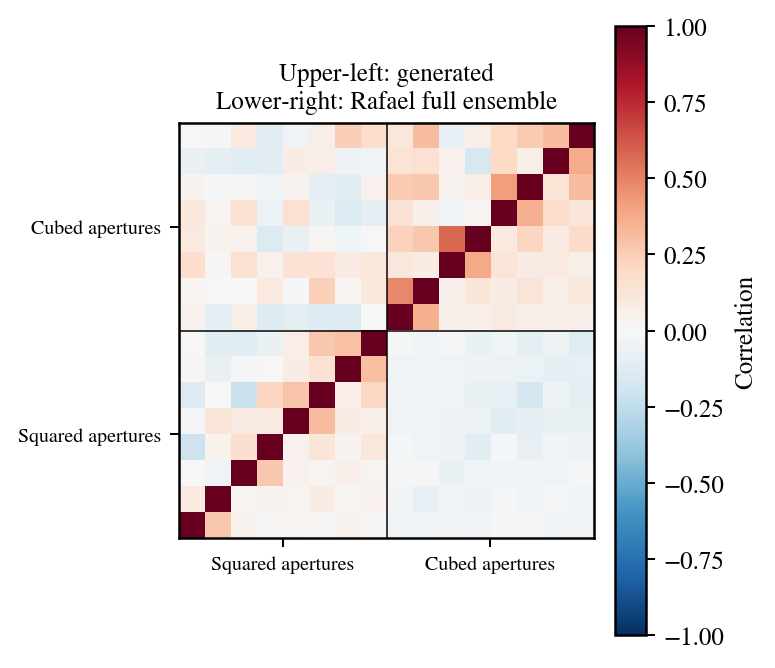

In [13]:
"""Redraw the pilot comparison using only the adjacent text records.

The tables are frozen outputs of the map/precision scripts in the note.
No map loading or fit is performed here. See the note for their assumptions.
"""
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
folder = NOTE / "plots/correlation"

reference = np.loadtxt(fname=folder / 'reference.txt')
generated = np.loadtxt(fname=folder / 'generated.txt')
old_scale = np.sqrt(np.diag(reference))
new_scale = np.sqrt(np.diag(generated))
old = reference / old_scale[:, None] / old_scale[None, :]
new = generated / new_scale[:, None] / new_scale[None, :]
# With origin=lower, row>=column is the displayed upper-left triangle.
# Generated maps occupy that half; the full supplied ensemble is lower-right.
combined = np.where(np.tril(np.ones((16, 16), dtype=bool)), new, old)
fig, ax = plt.subplots(figsize=(4.2, 3.6), constrained_layout=True)
artist = ax.imshow(X=combined, origin='lower', cmap='RdBu_r', vmin=-1., vmax=1.)
fig.colorbar(mappable=artist, ax=ax, label='Correlation')
ax.axhline(y=7.5, color='black', linewidth=.6)
ax.axvline(x=7.5, color='black', linewidth=.6)
ax.set_xticks(ticks=[3.5, 11.5], labels=['Squared apertures', 'Cubed apertures'])
ax.set_yticks(ticks=[3.5, 11.5], labels=['Squared apertures', 'Cubed apertures'])
ax.tick_params(axis='both', labelsize=8)
ax.set_title('Upper-left: generated\nLower-right: Rafael full ensemble', fontsize=10)
NAME = 'correlation.pdf'

fig.savefig(fname=folder / NAME, dpi=300)
fig.savefig(fname=folder / NAME.replace('.pdf', '.png'), dpi=300)
plt.show()
plt.close(fig)


### Precision comparison

Read the text records first, form the plotted statistic, then label its units.

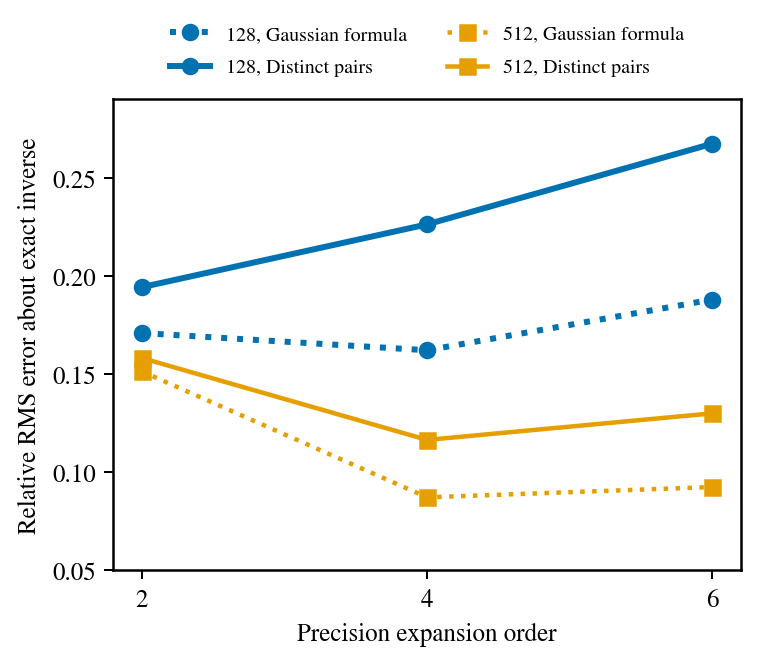

In [14]:
"""Redraw the pilot comparison using only the adjacent text records.

The tables are frozen outputs of the map/precision scripts in the note.
No map loading or fit is performed here. See the note for their assumptions.
"""
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90
folder = NOTE / "plots/precision"

data = np.loadtxt(fname=folder / 'data.txt')
fig, ax = plt.subplots(figsize=(4.5, 3.4))
# The distinct-pair construction has no Gaussian-distribution assumption.
# Dotted companion curves deliberately apply Wishart formulas to these data.
colors = ['#0072B2', '#E69F00']
for group, count in enumerate((128,512)):
    for offset in (0,3):
        rows = data[(data[:,0] == count) & (data[:,1] >= offset)
                    & (data[:,1] < offset+3)]
        name = 'Gaussian formula' if offset == 0 else 'Distinct pairs'
        style = ':' if offset == 0 else '-'
        ax.plot([2,4,6], rows[:,4], color=colors[group],
                marker=['o','s'][group], linewidth=[2.4,1.8][group],
                linestyle=style, label=f'{count}, {name}')
ax.set_xticks(ticks=[2,4,6])
ax.set_xlabel('Precision expansion order')
ax.set_ylabel('Relative RMS error about exact inverse')
ax.set_ylim(bottom=.05, top=.29)
legend = ax.legend(loc='lower center', bbox_to_anchor=(.5,1.01),
                   ncol=2, fontsize=8, frameon=False)
fig.canvas.draw()
assert not legend.get_window_extent().overlaps(ax.get_window_extent())
NAME = 'precision.pdf'

fig.savefig(fname=folder / NAME, dpi=300)
fig.savefig(fname=folder / NAME.replace('.pdf', '.png'), dpi=300)
plt.show()
plt.close(fig)


## Hold the analytical two-point block fixed

Write the joint covariance as

$$C=\begin{pmatrix}A&B\\ B^T&D\end{pmatrix}.$$

Here $A$ is the supplied two-point covariance, treated as exact. Simulations
inform $B$ and $D$. In the 480-row calculation the shapes are $400\times400$,
$400\times80$ and $80\times80$, respectively. Replacing the top-left block
after inverting an arbitrary matrix is not a consistent way to impose this.

Instead, describe the second observable conditionally on the first:

$$y=Hx+\epsilon,\qquad \operatorname{Cov}(\epsilon)=K^{-1}.$$

Multiplying out the covariance gives

$$B=AH^T,$$

$$D=K^{-1}+HAH^T.$$

The code below estimates the precision polynomial first, extracts $H$ and $K$,
and reconstructs these blocks. This keeps $A$ exactly. The polynomial estimator
and the final reconstructed covariance have different statistical properties:
the latter is nonlinear and is **not** asserted to be unbiased. A nonpositive
$K$ cannot describe a valid residual covariance and is reported rather than hidden.


In [15]:
"""Research precision expansion with a supplied, exact two-point block.

Distinct independent map pairs supply cross and three-point entries only.
The finite polynomial is unbiased for its deterministic polynomial target.
The final conditional reparameterization retains A exactly, but is nonlinear
and is NOT claimed to preserve finite-sample unbiasedness.
"""
import numpy as np


def estimates(vectors, reference, two_point_count):
    """Return second/fourth/sixth conditional precision and covariance pairs.

    reference must be fixed independently of vectors; its leading block is
    the exact supplied A. No Gaussian/Wishart sampling assumption is used.
    Odd final vectors are omitted from pairing, explicitly returned as used.
    """
    n = len(vectors)//2*2
    if n < 12:
        raise ValueError('Sixth order needs at least six independent pairs.')
    p = two_point_count
    dimension = vectors.shape[1]
    a = reference[:p, :p]
    factor = np.linalg.cholesky(reference)
    inverse = np.linalg.solve(factor, np.eye(dimension))
    # Pair differences remove the unknown mean. Dividing by sqrt(2)
    # restores the covariance of one draw, since two independent draws add.
    difference = (vectors[:n:2]-vectors[1:n:2])/np.sqrt(2.)
    # means[d] averages products of d DISTINCT pair factors. Descending
    # degree order prevents the current pair from appearing twice.
    means = [np.eye(dimension)] + [np.zeros_like(reference) for _ in range(6)]
    for count, row in enumerate(difference, 1):
        draw = np.outer(row, row)
        # This replacement is in physical coordinates, before whitening.
        # Every pair has the same exact A; no simulation estimates that block.
        draw[:p, :p] = a
        # Whitening expresses every entry in reference-covariance units.
        # The residual is I minus this dimensionless covariance draw.
        residual = np.eye(dimension)-inverse @ draw @ inverse.T
        for degree in range(min(count, 6), 0, -1):
            means[degree] = ((count-degree)/count*means[degree]
                            + degree/count*(means[degree-1] @ residual))
    results = []
    for order in (2, 4, 6):
        polynomial = sum(means[:order+1])
        raw = inverse.T @ ((polynomial+polynomial.T)/2) @ inverse
        k = raw[p:, p:]
        if np.linalg.eigvalsh(k)[0] <= 0:
            results.append((order, raw, None, None))
            continue
        # H predicts y from x, and K is the estimated residual precision.
        # Building the covariance from these two quantities keeps A exact.
        h = -np.linalg.solve(k, raw[p:, :p])
        conditional = np.linalg.solve(k, np.eye(dimension-p))
        covariance = np.block([[a, a @ h.T],
                               [h @ a, conditional+h @ a @ h.T]])
        precision = np.block([[np.linalg.solve(a, np.eye(p))+h.T @ k @ h,
                               -h.T @ k], [-k @ h, k]])
        np.testing.assert_array_equal(covariance[:p, :p], a)
        np.testing.assert_allclose((factor.T @ precision @ factor)
                                   @ (inverse @ covariance @ inverse.T), np.eye(dimension),
                                   atol=2.e-7, rtol=2.e-7)
        results.append((order, raw, precision, covariance))
    return results, n


### Check fixed block

Check fixed-A algebra on small matrices with exactly known covariance.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [16]:
def check_fixed_block():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    from pathlib import Path

    from itertools import combinations

    import numpy as np

    rng = np.random.default_rng(211126)

    truth = np.array([[1., .12, .08], [.12, .9, .10], [.08, .10, 1.1]])

    reference = np.diag([1., 1.2, 1.2])

    l = np.linalg.cholesky(reference)

    w = np.linalg.inv(l)

    a = truth[:1, :1]

    x = rng.multivariate_normal(np.zeros(3), truth, size=12)

    factors = []

    for delta in (x[::2]-x[1::2])/np.sqrt(2):
        z = np.outer(delta, delta)
        z[:1, :1] = a
        factors.append(np.eye(3)-w @ z @ w.T)

    expected = np.eye(3)

    results, used = estimates(x, reference, 1)

    for degree in range(1, 7):
        products = []
        for subset in combinations(range(6), degree):
            product = np.eye(3)
            for i in subset:
                product = product @ factors[i]
            products.append(product)
        term = np.mean(products, axis=0)
        expected += (term+term.T)/2
        if degree in (2, 4, 6):
            raw = results[(degree-2)//2][1]
            np.testing.assert_allclose(raw, w.T @ expected @ w, atol=2.e-12)

    print('Distinct-factor recurrence equals explicit products through sixth order.')

    b = [(row[:1, None] @ row[None, 1:]) for row in (x[::2]-x[1::2])/np.sqrt(2)]

    q = (sum(b).T @ sum(b)-sum(value.T @ value for value in b))/30

    brute = sum(b[i].T @ b[j] for i in range(6) for j in range(6) if i != j)/30

    np.testing.assert_allclose(q, brute, atol=1.e-14)

    print('Unbiased cross-square formula equals explicit distinct-pair sum.')

    t = np.eye(3)-w @ truth @ w.T

    targets = [w.T @ sum(np.linalg.matrix_power(t, k) for k in range(order+1)) @ w
               for order in (2, 4, 6)]

    values = []

    for repeat in range(512):
        draws = rng.multivariate_normal(np.zeros(3), truth, size=128)
        result, used = estimates(draws, reference, 1)
        values.append([item[1] for item in result])

    values = np.asarray(values)

    for index, order in enumerate((2, 4, 6)):
        error = values[:, index].std(axis=0, ddof=1)/np.sqrt(len(values))
        z = np.max(np.abs(values[:, index].mean(axis=0)-targets[index])/error)
        print('order', order, 'maximum mean discrepancy / Monte Carlo SE', z)
        assert z < 6

    print('Every returned constrained covariance retains A exactly and passes the inverse identity.')


# Run explicitly after checking the required inputs:
# check_fixed_block()


### Check full joint

Check the 480-dimensional ordering and a known finite-polynomial limit.

Zero input vectors are an algebraic test, not simulated observations. With
A held fixed, their masked factors have residual diag(0_400,I_80). Thus the
order-r constrained covariance must be diag(A,D_reference/(r+1)).

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [17]:
def check_full_joint():
    import os

    for name in ('OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
        os.environ[name] = '1'

    from pathlib import Path

    import numpy as np

    from astropy.io import fits

    p = PROJECT

    production = np.load(p / 'chains/gptg_ensemble_15000/des_y3_full_covariance.npz')

    rows = np.flatnonzero(production['rows'][:, 0] < 2)

    indices = (rows[:, None]*20+np.arange(20)).ravel()

    assert len(indices) == 400

    reference = np.zeros((480, 480))

    reference[:400, :400] = production['total'][np.ix_(indices, indices)]

    archived = fits.getdata(p / 'data/upstream_y3/data/covariance/xip_xim_map3_covariance_8ARCMINCUT_25Feb25.fits', extname='COVMAT')

    reference[400:, 400:] = archived[400:, 400:]

    result, used = estimates(np.zeros((12, 480)), reference, 400)

    for order, raw, precision, covariance in result:
        assert covariance is not None
        np.testing.assert_array_equal(covariance[:400, :400], reference[:400, :400])
        np.testing.assert_allclose(covariance[400:, 400:], reference[400:, 400:]/(order+1), rtol=1.e-10, atol=1.e-30)
        np.testing.assert_array_equal(covariance[:400, 400:], np.zeros((400, 80)))
        print('480 dimensions, order', order, ': exact A, zero cross block, D/(r+1) passed.')


# Run explicitly after checking the required inputs:
# check_full_joint()


### Audit the downloaded full-vector measurements

This section supersedes the earlier, unexecuted first-1,000-map workflow.
It uses **every complete saved checkpoint**, excludes partial vectors, and
counts overlapping map IDs once. The recorded run on 22 November used
1,878 maps. Re-running these cells with additional complete files changes
the sample; it does not overwrite any measurement or generate maps.

**The target is the covariance of the Kunhao-generated ensemble.**
Reproducing the published covariance is a different task. Independent
random seeds give independent realizations conditional on the fitted
parameters; the fact that those parameters were learned from the supplied
maps does not invalidate this conditional estimator benchmark.

For the fixed-$A$ comparison both methods must use the same supplied $A$:
the direct counterpart takes $B,D$ from the simulations and inserts that
$A$. The unconstrained sample covariance remains a separate diagnostic.
If supplied $A$ differs from the generator's actual two-point covariance,
this fixed-$A$ exercise targets a stipulated hybrid covariance rather than
the full covariance of the generated vector. Numerical tests of the
fixed-$A$ algebra remain possible; physical interpretation needs that
distinction. We do not refit or alter $A$ here.

Three questions come before an inverse: are all entries measurable, do the
reference and maps describe the same experiment, and is the expansion small?
The following cells answer them separately. A positive sample covariance is
an estimate, not exact truth.

The starting matrix has analytical Gaussian+SSC+cNG in its two-point block,
the **released simulation covariance** in its Map3 block, and zero cross
block. It must not be described as a fully analytical joint covariance.
The production maps **include shape noise**. Both CPU and GPU generators add
the amplitudes stored in `calibration.npz`; the noiseless numerical tests
in the GPU section are separate tests.

The full 480-entry covariance is singular: the first three angular bins of
each xi pair are empty. We retain its full output and explicitly project
onto 420 varying rows for the diagnostic. This projection does not recover
the missing measurements or validate the remaining rows as DES observables.

In [18]:
# These are saved TreeCorr vectors; this cell does not measure maps again.
# BLAS stays on one thread so the matrix calculation has a small CPU budget.
from pathlib import Path
import numpy as np
from scipy.linalg import solve_triangular
from astropy.io import fits
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt

folder = ENSEMBLE
output = CHAINS / 'gptg_ensemble_15000/full_joint_comparison_current'
output.mkdir(parents=True, exist_ok=True)

# Read both original and array-job checkpoints. A partial vector is excluded
# as a whole: pairwise deletion would give different ensembles to different
# covariance entries. Duplicate IDs must agree before they are counted once.
complete = {}
partial_count = 0
for directory in [folder / 'full_joint_480',
                  *sorted((folder / 'full_joint_480_shards').glob('*'))]:
    for path in sorted(directory.glob('map_*.txt')):
        row = np.loadtxt(path)
        if row.shape != (480,):
            raise ValueError(f'Unexpected vector shape: {path}')
        if not np.isfinite(row).all():
            partial_count += 1
            continue
        number = int(path.stem.split('_')[1])
        if number in complete:
            np.testing.assert_array_equal(complete[number], row)
        complete[number] = row
ids = np.array(sorted(complete))
vectors = np.array([complete[i] for i in ids])
if len(ids) < 481:
    raise ValueError('Need more complete independent maps than vector entries.')
np.savetxt(output / 'map_ids.txt', ids, fmt='%d')

# First inspect the entire measured vector. Constant entries cannot have an
# inverse sample covariance. Record their original IDs before any projection.
full_sample = np.cov(vectors, rowvar=False, ddof=1)
active = np.flatnonzero(np.diag(full_sample) > 0)
constant = np.flatnonzero(np.diag(full_sample) == 0)
# Pixel geometry predicts these missing rows. A different pattern needs a
# new investigation; do not silently remove arbitrary unexpected constants.
expected_empty = (20*np.arange(20)[:, None] + np.arange(3)).ravel()
np.testing.assert_array_equal(constant, expected_empty)
np.testing.assert_array_equal(vectors[:, constant], 0)
np.savetxt(output / 'constant_rows.txt', constant, fmt='%d')
np.savetxt(output / 'active_rows.txt', active, fmt='%d')
np.savetxt(output / 'covariance_sample_480.txt', full_sample)

# Preserve the earlier reference choice explicitly. Only A is analytical:
# its total includes Gaussian, SSC and cNG terms AND survey shape noise.
# The Map3 block comes from the released simulation covariance; B starts at
# zero. The generated maps have fitted pixel noise; this is not a matched reference.
production = np.load(folder / 'des_y3_full_covariance.npz')
pairs = np.flatnonzero(production['rows'][:, 0] < 2)
indices = (20 * pairs[:, None] + np.arange(20)).ravel()
assert len(indices) == 400
full_reference = np.zeros((480, 480))
full_reference[:400, :400] = production['total'][np.ix_(indices, indices)]
released = fits.getdata(
    PROJECT / 'data/upstream_y3/data/covariance/xip_xim_map3_covariance_8ARCMINCUT_25Feb25.fits',
    extname='COVMAT',
)
full_reference[400:, 400:] = released[400:, 400:]
np.savetxt(output / 'reference_480.txt', full_reference)

# This additional comparison is on the varying rows, with the SAME row
# selection applied to every matrix. It does not restore missing small-scale
# information. The full vector's singularity remains a separate finding.
values = vectors[:, active]
sample = full_sample[np.ix_(active, active)]
reference = full_reference[np.ix_(active, active)]
p = np.count_nonzero(active < 400)
a = reference[:p, :p]
fixed_sample = sample.copy()
fixed_sample[:p, :p] = a
with threadpool_limits(limits=1):
    factor = np.linalg.cholesky(reference)
    inverse = solve_triangular(factor, np.eye(len(active)), lower=True)
    residual = np.eye(len(active)) - inverse @ fixed_sample @ inverse.T
    residual_eigenvalues = np.linalg.eigvalsh(residual)
    # This calls the distinct-independent-pair estimator explained above.
    # It removes repeated-pair products through sixth order, then enforces A
    # through a conditional covariance. That last step is nonlinear.
    results, used = estimates(values, reference, p)
    rows = []
    eigen_curves = []
    for order, raw, precision, covariance in results:
        conditional_factor = factor[p:, p:]
        eigenvalues = np.linalg.eigvalsh(
            conditional_factor.T @ raw[p:, p:] @ conditional_factor)
        eigen_curves.append(eigenvalues)
        rows.append([order, eigenvalues[0], eigenvalues[-1], covariance is not None])
        np.savetxt(output / f'raw_precision_active_order{order}.txt', raw)
        if covariance is not None:
            np.savetxt(output / f'covariance_active_order{order}.txt', covariance)
    sample_minimum = np.linalg.eigvalsh(inverse @ sample @ inverse.T)[0]

np.savetxt(output / 'orders.txt', rows,
           header='order min_dimensionless_conditional_precision max_dimensionless_conditional_precision valid_covariance')
np.savetxt(output / 'covariance_active_sample.txt', sample)
np.savetxt(output / 'covariance_active_fixed_A_sample.txt', fixed_sample)
np.savetxt(output / 'reference_active.txt', reference)
a_ratio = np.diag(a) / np.diag(sample)[:p]
d_ratio = np.diag(reference)[p:] / np.diag(sample)[p:]
summary = (
    f'Complete maps: {len(ids)}; partial checkpoints excluded: {partial_count}\n'
    f'Full dimension: 480; constant rows: {len(constant)}; active dimension: {len(active)}\n'
    f'Independent pairs used: {used // 2}; fixed A dimension: {p}\n'
    f'Residual eigenvalue range: {residual_eigenvalues[0]:.8g}, {residual_eigenvalues[-1]:.8g}\n'
    f'Active sample minimum whitened eigenvalue: {sample_minimum:.8g}\n'
    f'A/sample diagonal ratio [min, median, max]: {np.percentile(a_ratio, [0, 50, 100])}\n'
    f'Dref/sample diagonal ratio [min, median, max]: {np.percentile(d_ratio, [0, 50, 100])}\n'
    f'Order, minimum conditional precision, maximum, valid:\n{np.array(rows)}\n'
    'Reference: analytical noisy A; released simulation D; zero B.\n'
    'Map measurements: NSIDE512 with fitted independent pixel shape noise. This is not a matched DES validation.\n'
)
(output / 'summary.txt').write_text(summary)
print(summary)



Complete maps: 1878; partial checkpoints excluded: 1878
Full dimension: 480; constant rows: 60; active dimension: 420
Independent pairs used: 939; fixed A dimension: 340
Residual eigenvalue range: -58.598489, 0.8759726
Active sample minimum whitened eigenvalue: 0.26743458
A/sample diagonal ratio [min, median, max]: [0.18837325 0.59147613 1.45751961]
Dref/sample diagonal ratio [min, median, max]: [0.02667394 0.08624479 0.26066291]
Order, minimum conditional precision, maximum, valid:
[[ 2.00000000e+00 -2.52540557e+00  3.54961243e+03  0.00000000e+00]
 [ 4.00000000e+00 -1.69011558e+05  1.19508303e+07  0.00000000e+00]
 [ 6.00000000e+00 -2.09181703e+09  3.89392464e+10  0.00000000e+00]]
Reference: analytical noisy A; released simulation D; zero B.
Map measurements: NSIDE512 with fitted independent pixel shape noise. This is not a matched DES validation.



### Explain the zero entries using geometry

A map pixel supplies one position, not a catalogue of galaxies within it.
Two distinct retained pixel centers are at least about 5.61 arcminutes apart.
The first three requested bins end below 4.99 arcminutes, so they contain
no pairs. A zero returned for such a bin is an empty measurement, not a
physical measurement of zero shear correlation.

The nearest-neighbor calculation below verifies this statement independently
of TreeCorr. The pair counts also expose the uneven sampling of the next
bins. Raising NSIDE by interpolating an existing map would not supply the
missing small-scale signal or independent galaxy noise.

In [19]:
# Only sky positions are read here. No shear file or TreeCorr measurement
# is needed to ask whether a separation bin can contain any pixel pairs.
import ducc0
from scipy.spatial import cKDTree

idx=np.load(folder/'indices_512.npy')
# pix2ang returns the colatitude theta and longitude phi in radians.
theta,phi=ducc0.healpix.Healpix_Base(512,'RING').pix2ang(idx.astype(np.int64)).T
longitude, latitude = phi, np.pi/2-theta
xyz=np.column_stack((np.cos(latitude)*np.cos(longitude),
                       np.cos(latitude)*np.sin(longitude), np.sin(latitude)))
tree=cKDTree(xyz)
d=tree.query(xyz,k=2,workers=1)[0][:,1]
minimum=2*np.arcsin(d.min()/2)*180*60/np.pi
edges=np.geomspace(2.5,250,21)[:9]
cumulative=(tree.count_neighbors(tree,2*np.sin(np.deg2rad(edges/60)/2))-len(idx))/2
pairs=np.diff(cumulative)
print('minimum separation arcmin',minimum)
print('edges',edges)
print('unordered pairs per bin',pairs)
np.savetxt(output/'geometry.txt',np.column_stack((edges[:-1],edges[1:],pairs)),header=f'minimum separation {minimum}; lower_arcmin upper_arcmin unordered_pairs')


minimum separation arcmin 5.613444602706883
edges [ 2.5         3.14731353  3.96223298  4.98815579  6.27971608  7.90569415
  9.95267926 12.52968084 15.77393361]
unordered pairs per bin [      0.       0.       0.   75869.  578948.  472301.  438774. 1343072.]


### Separate covariance mismatch from numerical algebra

Write the selected reference as $M=LL^T$, where $L$ is its Cholesky factor.
Replace only the measured two-point block by the stipulated analytical $A$
to form $C_h$. This is a diagnostic hybrid, not an unbiased covariance
estimator for the current maps. Define

$$E=I-L^{-1}C_hL^{-T}.$$

The infinite inverse series needs every eigenvalue $e$ of $E$ to satisfy
$|e|<1$. Multiplying a finite geometric sum gives

$$(1-e)(1+e+\cdots+e^q)=1-e^{q+1}.$$

Thus its relative error as an approximation to $1/(1-e)$ is
$-e^{q+1}$. In the downloaded sample the largest magnitude is about 58.6:
increasing the order makes this deterministic problem worse. The sample is
not exact truth, but this is far from a borderline convergence diagnostic.

The independent-pair estimator is our extension of precision expansion; it
is not the original paper's Gaussian second-order formula. Distinct factors
remove repeated-draw bias, but do not ensure positivity or low variance.
Ascending-factor products depend on ordering in each finite sample; their
expectation is the intended matrix power under independent identical draws.
The final fixed-$A$ conditional reconstruction is nonlinear and is not
claimed unbiased. We check that implementation against direct enumeration
and a matched Gaussian control below.

A final diagnostic multiplies only the starting Map3 block by several
constants, keeping $A$ fixed. It asks whether a single amplitude adjustment
would make a low-order expansion adequate. These are choices examined
after seeing the sample; they are not independent-reference PME estimates.
Even the convergent factor-64 case retains about 96% worst-direction error
at sixth order in the deterministic sample calculation. Amplitude repair
alone is insufficient; the poorly matched covariance directions matter.


In [20]:
# Compare the actual metadata before attributing differences to PME.
# A noise variance is per shear component, per pixel. Dividing the galaxy
# ellipticity variance by the expected number of galaxies per pixel gives
# the uniform-density pixel approximation to the analytical noise model.
import json
from itertools import combinations_with_replacement

settings = json.loads(str(production['settings_json']))
calibration_arrays = np.load(folder / 'calibration.npz')
pixel_area = 4*np.pi/(12*512**2) * (180*60/np.pi)**2
pixel_count = len(np.load(folder / 'indices_512.npy'))
analytical_pixel_sigma = np.asarray(settings['sigma_e_component']) / np.sqrt(
    pixel_area * np.asarray(settings['source_density_arcmin2']))
noise_power_ratio = (calibration_arrays['noise_sigma']/analytical_pixel_sigma)**2
print('Equal-pixel footprint [deg2]:', pixel_count*pixel_area/3600)
print('Analytical survey area [deg2]:', settings['area_deg2'])
print('Generated / analytical pixel noise variance:', noise_power_ratio)

# Check the FITS labels as well as the matrix size. A source-order error
# would make the same-sized matrices describe different random variables.
data = PROJECT / 'data/upstream_y3/data/dv'
xrows = fits.getdata(data / 'sim_2pt-NLA-cosmoCosmogrid-04Nov24.fits', 'xip')
yrows = fits.getdata(
    data / 'sim_map3_emu-NLA-cosmoCosmogrid-24FEBRUARY2025_WITH_COV.fits', 'map3')
for index, pair in enumerate(combinations_with_replacement(range(1, 5), 2)):
    for j in range(2):
        np.testing.assert_array_equal(xrows[f'BIN{j+1}'][20*index:20*index+20], pair[j])
for index, triple in enumerate(combinations_with_replacement(range(1, 5), 3)):
    for j in range(3):
        np.testing.assert_array_equal(yrows[f'BIN{j+1}'][4*index:4*index+4], triple[j])
        np.testing.assert_array_equal(yrows[f'THETA{j+1}'][4*index:4*index+4], [7, 14, 25, 40])
print('Published source labels and all three aperture radii agree.')

# With a known A, the covariance can exist only if the Schur complement
# S_cond = D - B.T @ solve(A, B) is positive definite. Checking this first
# separates an incompatible covariance from a failed precision expansion.
# Matrix solves avoid explicitly forming A^{-1}.
with threadpool_limits(limits=1):
    conditional = sample[p:, p:] - sample[p:, :p] @ np.linalg.solve(a, sample[:p, p:])
    ld = np.linalg.cholesky(reference[p:, p:])
    wd = solve_triangular(ld, np.eye(len(ld)), lower=True)
    conditional_eigenvalues = np.linalg.eigvalsh(wd @ conditional @ wd.T)
print('Fixed-A sample Schur eigenvalue range:', conditional_eigenvalues[[0, -1]])

# The polynomial has a problem even before simulation noise: if E has an
# eigenvalue e, the relative inverse error of sum_{j=0}^q E^j is -e^(q+1).
# This follows by multiplying the finite sum by (I-E). Here we plug in the
# sample diagnostic, not an asserted exact population covariance.
for order in (2, 4, 6):
    print('Order', order, 'largest plug-in polynomial relative error:',
          np.max(np.abs(residual_eigenvalues)**(order+1)))

# Both completed job ranges show the Map3 excess. They are useful checks
# for a single damaged checkpoint batch, not independent proof of a DES
# model, and they have different mixtures of numerical generation modes.
for lower, upper in ((0, 5000), (5000, 10000)):
    selected = (ids >= lower) & (ids < upper)
    if selected.sum() > 1:
        diagonal = np.var(vectors[selected, 400:], axis=0, ddof=1)
        print('Map ID range', lower, upper, 'N=', selected.sum(),
              'median Map3 variance / starting D:',
              np.median(diagonal/np.diag(full_reference)[400:]))

# Do not infer a universal multiplicative calibration from this table.
# The mismatch depends on radius and source-bin combination.
variance_ratio = np.diag(sample)[p:] / np.diag(reference)[p:]
print('Map3 sample/reference variance by radius; rows=min,median,max:')
print(np.percentile(variance_ratio.reshape(20, 4), [0, 50, 100], axis=0))

# This is a known-covariance control using cheap random vectors, not new
# shear maps. The reference equals the exact covariance, and A is exact.
# Individual random polynomial estimates still need not be positive.
# Its seed, dimension and sample count are explicit for reproducibility.
with threadpool_limits(limits=1):
    gaussian_draws = np.random.default_rng(221126).normal(size=(len(ids), len(active)))
    controls, used_control = estimates(gaussian_draws, np.eye(len(active)), p)
    for order, raw, precision, covariance in controls:
        eigenvalues = np.linalg.eigvalsh(raw[p:, p:])
        print('Matched Gaussian control, order', order,
              'conditional precision min/max', eigenvalues[[0, -1]],
              'positive:', covariance is not None)

# These tests compare the actual recurrence with explicit products of
# distinct factors and repeat a small known-covariance Monte Carlo test.
# They do not measure maps and do not establish physical DES calibration.
check_fixed_block()


# Changing only D's scale tests whether an amplitude error explains failure.
# These choices are explored after seeing the data. This is a diagnostic,
# NOT an independently specified, unbiased PME result or a fitted DES model.
scan=[]
with threadpool_limits(limits=1):
    for multiplier in (1., 4., 16., 32., 64.):
        candidate = reference.copy()
        candidate[p:, p:] *= multiplier
        trial_l = np.linalg.cholesky(candidate)
        trial_w = solve_triangular(trial_l, np.eye(len(active)), lower=True)
        trial_c = trial_w @ fixed_sample @ trial_w.T
        eigenvalues = np.linalg.eigvalsh(trial_c)
        errors = [np.max(np.abs(1-eigenvalues)**(q+1)) for q in (2,4,6)]
        scan.append([multiplier, eigenvalues[0], eigenvalues[-1], *errors])
print('D multiplier; whitened C min/max; worst plug-in inverse relative error q=2,4,6')
print(np.array(scan))
np.savetxt(output/'reference_scan.txt',scan,
           header='D_multiplier min_C max_C error_order2 error_order4 error_order6')


Equal-pixel footprint [deg2]: 4841.544076179854
Analytical survey area [deg2]: 4143.0
Generated / analytical pixel noise variance: [1.47646718 1.50242096 1.5193693  1.57878471]
Published source labels and all three aperture radii agree.
Fixed-A sample Schur eigenvalue range: [ 0.35997485 38.94984325]
Order 2 largest plug-in polynomial relative error: 201214.4889999289
Order 4 largest plug-in polynomial relative error: 690926871.3065894
Order 6 largest plug-in polynomial relative error: 2372492874972.244
Map ID range 0 5000 N= 939 median Map3 variance / starting D: 11.862525046517174
Map ID range 5000 10000 N= 939 median Map3 variance / starting D: 11.807393635636224
Map3 sample/reference variance by radius; rows=min,median,max:
[[13.52966907 13.56933576  4.29760491  3.83637245]
 [16.95704469 17.4892102   6.73529593  5.67806145]
 [37.48977988 24.67755659 10.1442575   8.92974968]]


Matched Gaussian control, order 2 conditional precision min/max [0.37802393 1.69036622] positive: True
Matched Gaussian control, order 4 conditional precision min/max [0.37102366 1.9444796 ] positive: True
Matched Gaussian control, order 6 conditional precision min/max [0.14347506 2.11940113] positive: True
Distinct-factor recurrence equals explicit products through sixth order.
Unbiased cross-square formula equals explicit distinct-pair sum.


order 2 maximum mean discrepancy / Monte Carlo SE 2.59215633166888
order 4 maximum mean discrepancy / Monte Carlo SE 2.5293911735037895
order 6 maximum mean discrepancy / Monte Carlo SE 2.5455220281259305
Every returned constrained covariance retains A exactly and passes the inverse identity.
D multiplier; whitened C min/max; worst plug-in inverse relative error q=2,4,6
[[1.00000000e+00 1.24027404e-01 5.95984889e+01 2.01214489e+05
  6.90926871e+08 2.37249287e+12]
 [4.00000000e+00 6.67929866e-02 1.52073819e+01 2.86775581e+03
  5.78855655e+05 1.16841841e+08]
 [1.60000000e+01 2.09178846e-02 4.16383953e+00 3.16696558e+01
  3.17009473e+02 3.17322696e+03]
 [3.20000000e+01 1.08502926e-02 2.39002465e+00 2.68576185e+00
  5.18934449e+00 1.00266880e+01]
 [6.40000000e+01 5.52446060e-03 1.58860528e+00 9.83518009e-01
  9.72681212e-01 9.61963820e-01]]


### Read the plots without treating an invalid precision as a covariance

Every second-, fourth- and sixth-order conditional precision in this run has
a negative eigenvalue. We do not invert it or clip its spectrum. Consequently
the split-triangle plots compare the direct sample with the starting matrix
and with fixed $A$ plus sample $B,D$; **they are not PME covariance plots**.
The lower difference panels use one common normalization, the sample
standard deviations. This avoids dividing by cross-covariance entries near
zero. The separate signed-eigenvalue plot explains why no PME covariance
curve is shown.

/var/folders/8m/fbnlt6rs00g8g5nshfw27mfw0000gn/T/ipykernel_83063/1904151364.py:23: UserWarning: Glyph 7522 (\N{LATIN SUBSCRIPT SMALL LETTER I}) missing from font(s) STIXGeneral.
  fig.savefig(output / 'comparison.png', dpi=160)
/var/folders/8m/fbnlt6rs00g8g5nshfw27mfw0000gn/T/ipykernel_83063/1904151364.py:23: UserWarning: Glyph 11388 (\N{LATIN SUBSCRIPT SMALL LETTER J}) missing from font(s) STIXGeneral.
  fig.savefig(output / 'comparison.png', dpi=160)


/var/folders/8m/fbnlt6rs00g8g5nshfw27mfw0000gn/T/ipykernel_83063/1904151364.py:24: UserWarning: Glyph 7522 (\N{LATIN SUBSCRIPT SMALL LETTER I}) missing from font(s) STIXGeneral.
  fig.savefig(output / 'comparison.pdf')
/var/folders/8m/fbnlt6rs00g8g5nshfw27mfw0000gn/T/ipykernel_83063/1904151364.py:24: UserWarning: Glyph 11388 (\N{LATIN SUBSCRIPT SMALL LETTER J}) missing from font(s) STIXGeneral.
  fig.savefig(output / 'comparison.pdf')


/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 7522 (\N{LATIN SUBSCRIPT SMALL LETTER I}) missing from font(s) STIXGeneral.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 11388 (\N{LATIN SUBSCRIPT SMALL LETTER J}) missing from font(s) STIXGeneral.
  fig.canvas.print_figure(bytes_io, **kw)


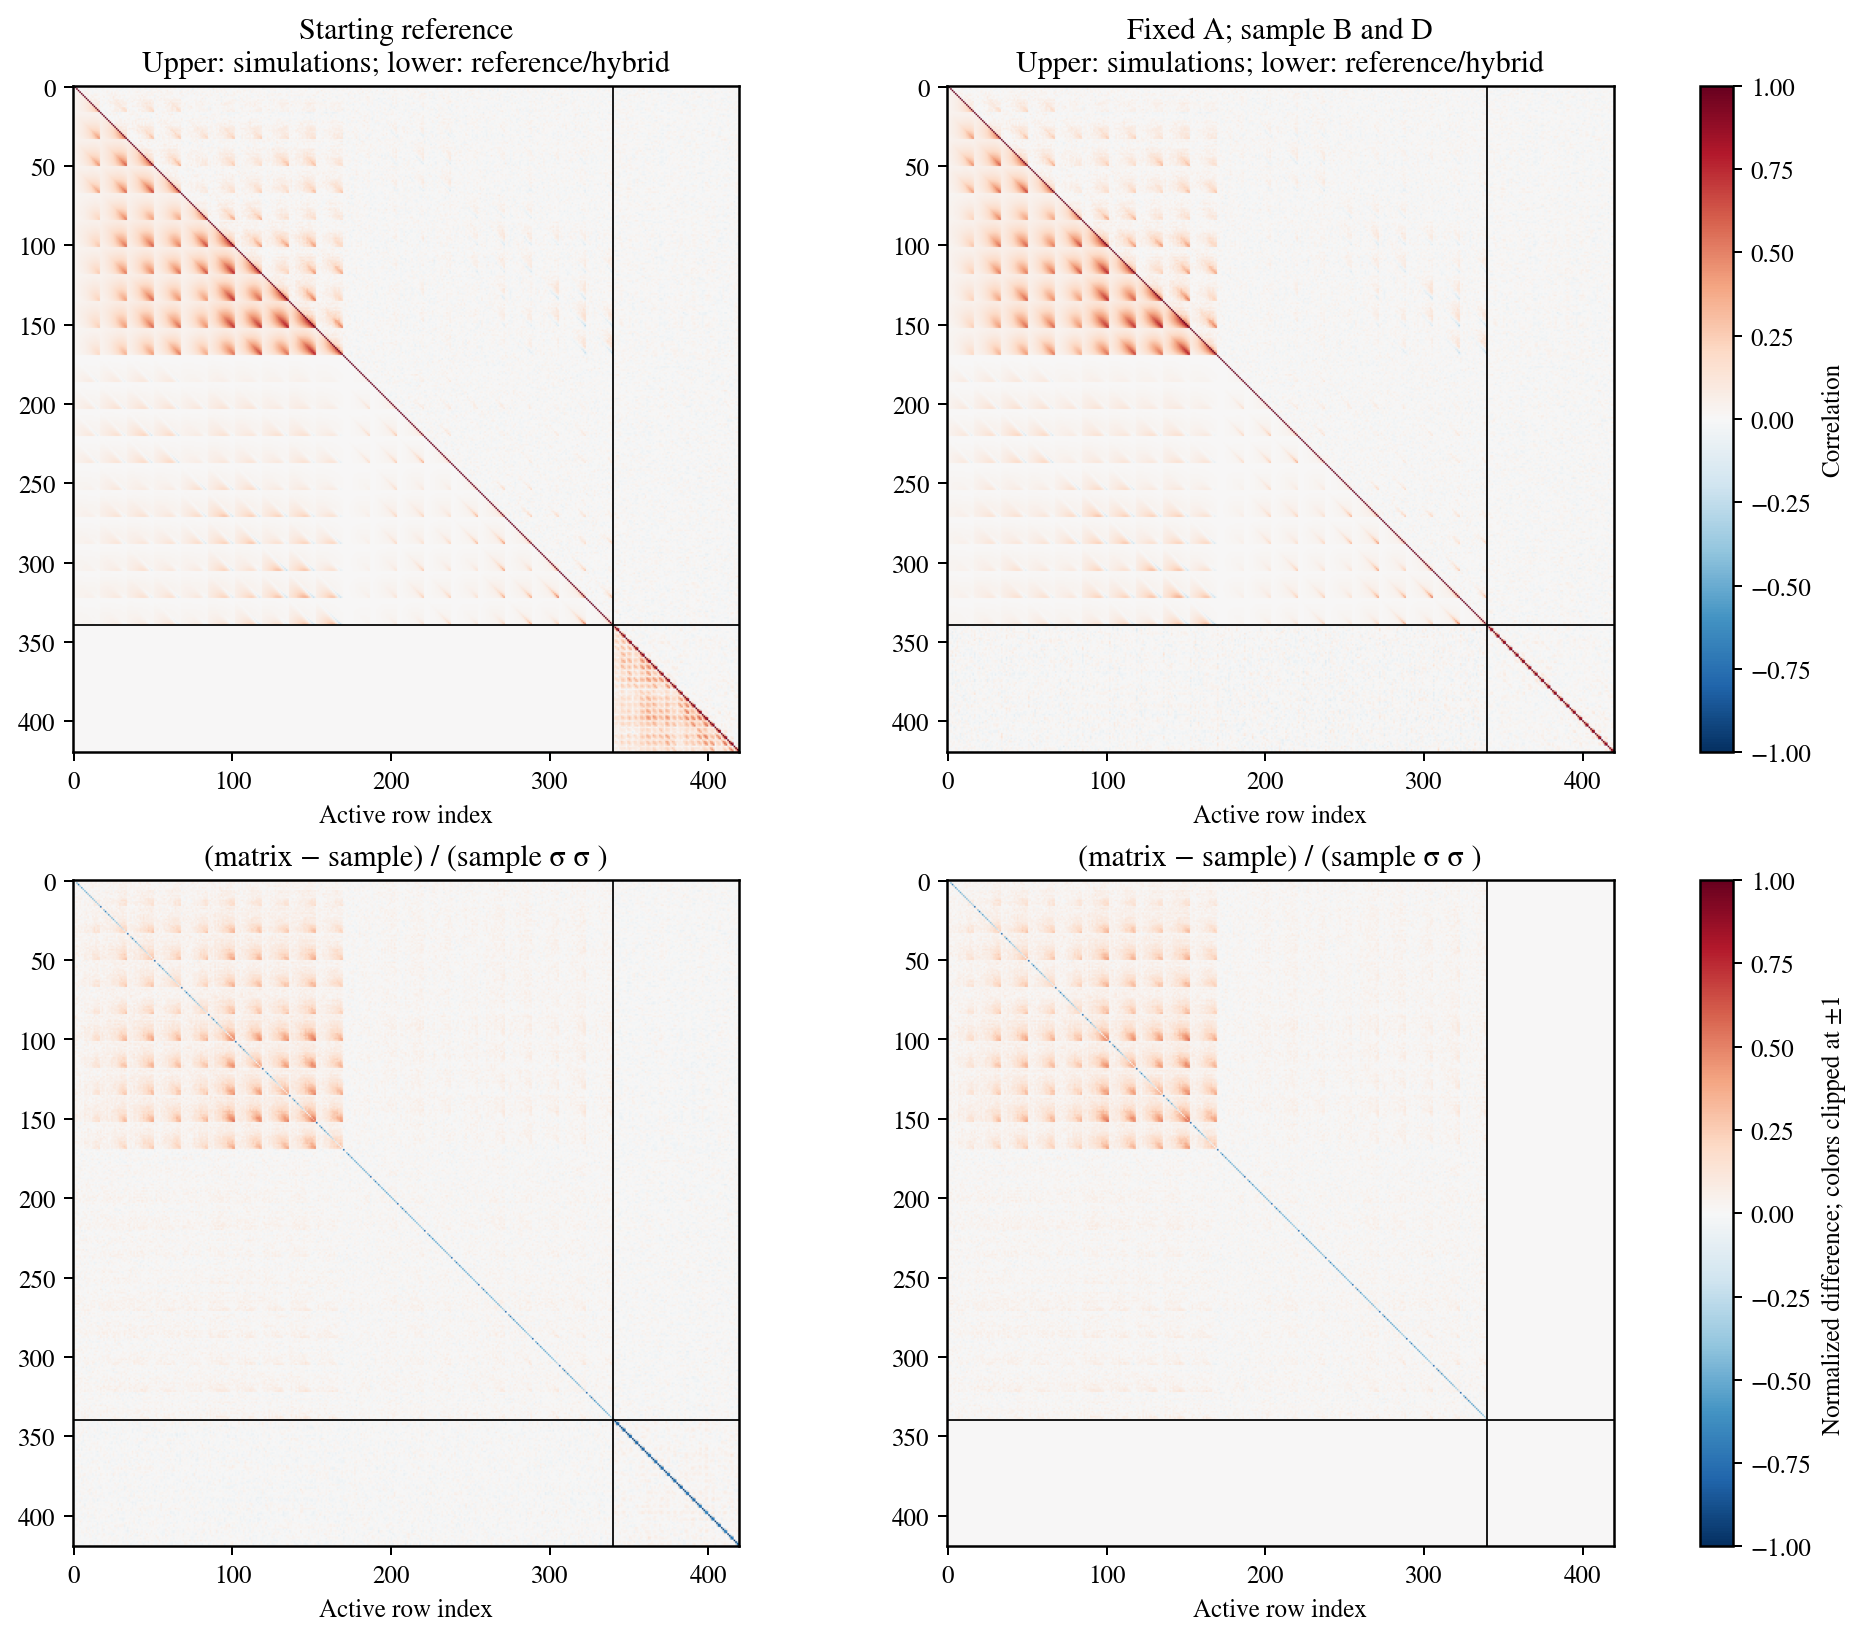

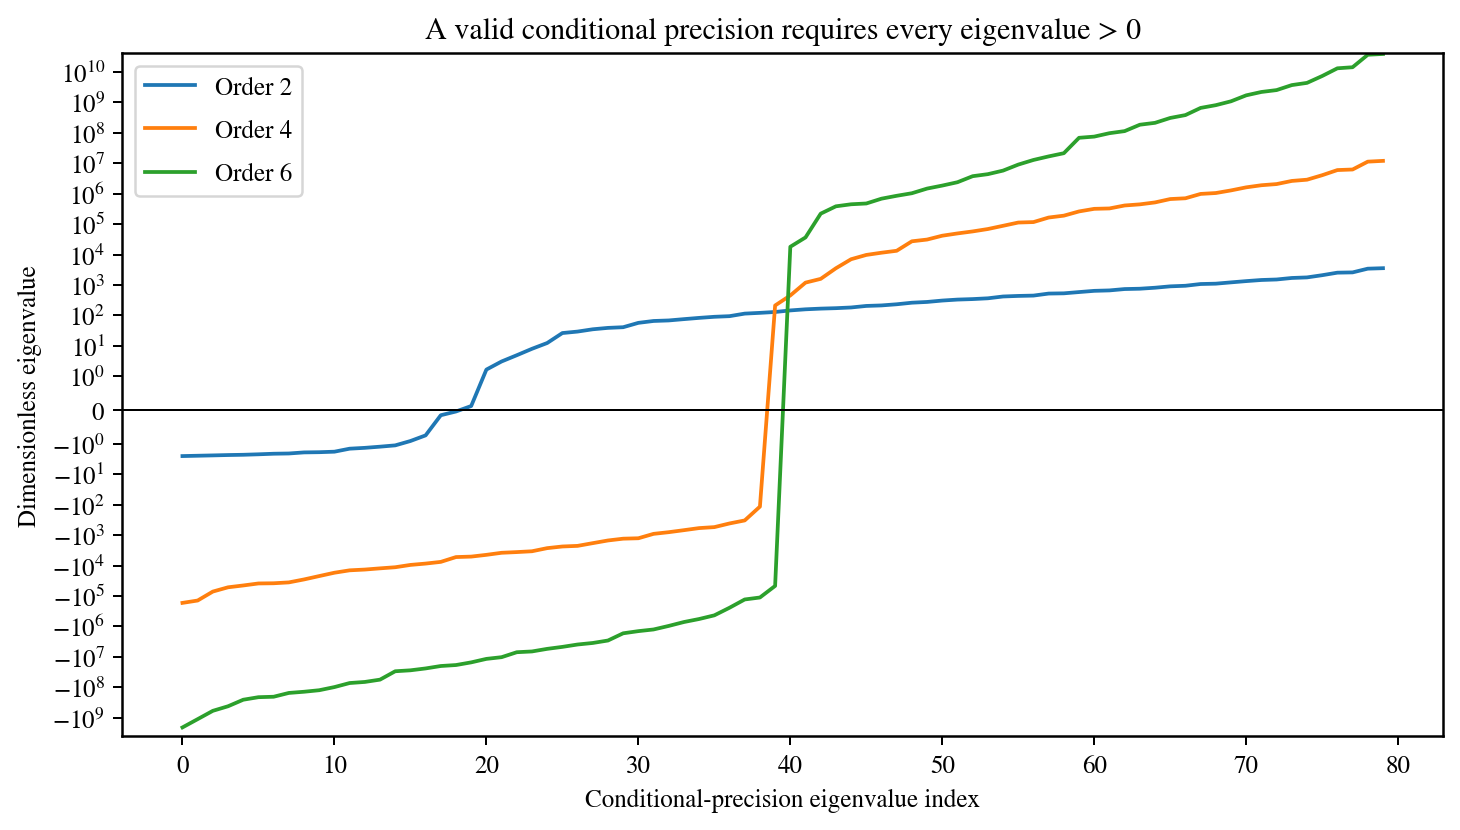

In [21]:
# Correlation removes the diagonal units. Differences instead use the SAME
# sample sigma_i sigma_j denominator, so a small cross entry does not cause
# a division by a nearly zero covariance element.
sigma = np.sqrt(np.diag(sample))
denominator = np.outer(sigma, sigma)
fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
for column, (label, matrix) in enumerate([
        ('Starting reference', reference), ('Fixed A; sample B and D', fixed_sample)]):
    scale = np.sqrt(np.diag(matrix))
    split = np.where(np.triu(np.ones_like(sample, dtype=bool)),
                     sample / denominator, matrix / np.outer(scale, scale))
    corr = axes[0, column].imshow(split, vmin=-1, vmax=1, cmap='RdBu_r')
    axes[0, column].set_title(f'{label}\nUpper: simulations; lower: reference/hybrid')
    delta = axes[1, column].imshow((matrix - sample) / denominator,
                                   vmin=-1, vmax=1, cmap='RdBu_r')
    axes[1, column].set_title('(matrix − sample) / (sample σᵢσⱼ)')
    for ax in axes[:, column]:
        ax.axhline(p-.5, color='black', lw=.7)
        ax.axvline(p-.5, color='black', lw=.7)
        ax.set_xlabel('Active row index')
fig.colorbar(corr, ax=axes[0, :], label='Correlation')
fig.colorbar(delta, ax=axes[1, :], label='Normalized difference; colors clipped at ±1')
fig.savefig(output / 'comparison.png', dpi=160)
fig.savefig(output / 'comparison.pdf')
plt.show()
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for order, curve in zip((2, 4, 6), eigen_curves):
    ax.plot(curve, label=f'Order {order}')
ax.axhline(0, color='black', lw=.8)
ax.set_yscale('symlog', linthresh=1)
ax.set_xlabel('Conditional-precision eigenvalue index')
ax.set_ylabel('Dimensionless eigenvalue')
ax.set_title('A valid conditional precision requires every eigenvalue > 0')
ax.legend()
fig.savefig(output / 'precision_eigenvalues.png', dpi=160)
plt.show()


In [22]:
# Record provenance limitations separately from the numerical results.
# Equal-shaped vectors are not proof of equal estimator settings. Keep the
# measurement.txt files with checkpoints when copying measurement results.
import hashlib

fingerprints = {hashlib.sha256(row.tobytes()).hexdigest() for row in vectors}
print('Unique complete vectors:', len(fingerprints), '/', len(vectors))
print('Calibration SHA256:', hashlib.sha256((folder/'calibration.npz').read_bytes()).hexdigest())
for directory in [folder/'full_joint_480',
                  *sorted((folder/'full_joint_480_shards').glob('*'))]:
    if not any(directory.glob('map_*.txt')):
        continue
    metadata = directory/'measurement.txt'
    print(directory.name, ':', metadata.read_text() if metadata.exists()
          else 'measurement.txt absent; checkpoint files alone do not verify all settings.')


Unique complete vectors: 1878 / 1878
Calibration SHA256: 4f5d7119eadbd537d984e47db3c93845b76b510e4af919372b67870e04117019
0_5000 : measurement.txt absent; checkpoint files alone do not verify all settings.
5000_10000 : 480 rows: 200 xi-plus, 200 xi-minus, 80 Map3.
TreeCorr 5.1.2; NSIDE512 RING; equal pixel weights.
Side bank .5..80, 20 log bins, keep lower edge >=8: index 11, minimum 8.1514711308706111 arcmin.
Multipole max_n=100; 63 SAS bins, edges 0.016..3.126 radians.
bin_slop=0; angle_slop=0; symmetrized tomographic legs.
939 MPI compute ranks; one coordinator; BLAS=1; native threads=1.
smoke_pixels=0; smoke outputs are not science vectors.



### What the paper comparison can and cannot tell us

[Gomes et al., Section III](https://arxiv.org/html/2503.03964v2#S3)
uses NSIDE 1024 and galaxy-position noise before pixel averaging. Our maps
use NSIDE 512, equal pixel weights and constant independent pixel noise.
The paper's roughly 8-arcminute triangle cut was checked at its resolution;
that does not validate the same cut at ours. The FITS source labels and all
three filter radii agree, but that is only an ordering check. Its covariance
header records `NSIM=500`; the paper describes 796 footprints. The lineage
of this particular supplied matrix needs confirmation before using that
number in a finite-simulation likelihood.

Our initial fit uses masked E-minus-B spectra divided by sky fraction and
quantiles of a masked, 10-arcminute-smoothed convergence reconstruction.
It is an approximate fit, not a demonstrated DES generator. Noise-level
and area differences alone do not explain the whole Map3 excess. The
relative contributions from the fit, finite resolution, bin weights and
multipole/SAS reconstruction remain to be measured. Existing checkpoints
lack pair/triangle weights, so they cannot settle those tests by themselves.
For the immediate estimator benchmark, we do not need to turn these maps
into the supplied simulations. We need measurable rows and a reference close
enough to the generator's stipulated covariance for low-order expansion.
For later DES interpretation, compare a small set of supplied and GPTG maps
with the identical estimator, saving geometric weights and testing angular
cuts before committing to a large measurement campaign.

### A second correction using the supplied maps

A positive, sufficiently close covariance built from GPTG can serve as the
starting matrix for a subsequent precision expansion; it need not be purely
analytical. Keep the same exact $A$ and match all other measurement choices.
The present invalid PME outputs cannot serve as that starting covariance.

Independence also needs care: the generator was fitted to supplied parent runs
0–31. Drawing new GPTG seeds does not remove that dependence. For a fixed-
reference unbiasedness argument, use supplied parent runs that did not enter
the fit, or explicitly account for dependence (for example by fitting without
each correction group). Different footprints/noise rotations of one parent
do not count as new independent parents. This is about reused calibration
information, not a requirement to divide the generated ensemble into three
groups. All selected GPTG maps can still enter their sample comparison.

### Compare maps

Forward-test the initial GPTG generator with the same masked measurements.

The 32 supplied maps were also used for fitting. This is a diagnostic of
model mismatch, not an independent validation or a cosmological likelihood.
Generated maps are new random draws conditional on that fit. No map is
dropped according to its measured moments or covariance.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [23]:
def compare_maps():
    import os

    os.environ["OPENBLAS_NUM_THREADS"] = "1"

    os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

    os.environ["OMP_NUM_THREADS"] = "4"

    from pathlib import Path

    import numpy as np

    import ducc0

    import yaml

    from generate_maps import PROJECT, OUTPUT, setup, pseudo_modes, spectra

    """Compare pseudo-spectra, reconstructed PDF and sixteen raw moments."""
    record = yaml.safe_load((OUTPUT/'calibration.yaml').read_text())
    reference = np.load(file=OUTPUT/'fit_measurements.npz')
    generated = np.load(file=OUTPUT/'generated_measurements.npz')
    lmax = record['lmax']
    indices, geometry, ell, factor, nodes, weights = setup(lmax=lmax)
    centers = reference['centers'][:, 0].astype(int)
    spectrum = np.zeros((2, 4, 4, lmax+1))
    reconstructed = []
    paths = sorted((OUTPUT/'maps').glob('GPTG_DES_*.npy'))
    inverse = np.zeros_like(factor)
    inverse[ell >= 2] = 1./factor[ell >= 2]
    smooth = np.exp(-ell*(ell+1)*np.deg2rad(10./60.)**2/2.)
    for number, path in enumerate(paths):
        shear = np.load(
            file=path,
            mmap_mode='r',
        )
        modes = []
        proxy = []
        for source in range(4):
            result = pseudo_modes(
                shear=shear[source],
                indices=indices,
                geometry=geometry,
                lmax=lmax,
                workers=4,
                second_sign=record['second_component_sign_for_ducc'],
            )
            modes.append(result)
            convergence = ducc0.sht.synthesis(
                alm=result[:1]*inverse*smooth,
                spin=0,
                lmax=lmax,
                nthreads=4,
                **geometry,
            )
            proxy.append(convergence[0, centers])
        modes = np.asarray(modes)
        reconstructed.append(proxy)
        for i in range(4):
            for j in range(i, 4):
                for parity in range(2):
                    value = spectra(modes[i, parity], modes[j, parity], ell, lmax)
                    spectrum[parity, i, j] += value
                    if i != j:
                        spectrum[parity, j, i] += value
        print('compared', number+1, '/', len(paths), flush=True)
    spectrum /= len(paths)
    np.savez_compressed(
        OUTPUT/'forward_measurements.npz',
        pseudo_cl=spectrum,
        reconstruction=reconstructed,
    )
    target_vectors = np.concatenate([
        np.mean(reference['aperture']**2, axis=-1).reshape(-1, 8),
        np.mean(reference['aperture']**3, axis=-1).reshape(-1, 8),
    ], axis=1)
    new_vectors = np.concatenate([
        np.mean(generated['aperture']**2, axis=-1).reshape(-1, 8),
        np.mean(generated['aperture']**3, axis=-1).reshape(-1, 8),
    ], axis=1)
    covariance_real = np.cov(
        m=target_vectors,
        rowvar=False,
        ddof=1,
    )
    covariance_new = np.cov(
        m=new_vectors,
        rowvar=False,
        ddof=1,
    )
    mean_real = target_vectors.mean(axis=0)
    mean_new = new_vectors.mean(axis=0)
    # This normalization only describes the observed difference. The fit
    # couples model parameters to the reference sample, so these are not
    # independent significance tests or calibrated p-values.
    difference_error = np.sqrt(np.diag(covariance_real)/len(target_vectors)
                               + np.diag(covariance_new)/len(new_vectors))
    ratio = np.diag(covariance_new)/np.diag(covariance_real)
    scales_real = np.sqrt(np.diag(covariance_real))
    scales_new = np.sqrt(np.diag(covariance_new))
    correlation_real = covariance_real/scales_real[:, None]/scales_real[None, :]
    correlation_new = covariance_new/scales_new[:, None]/scales_new[None, :]
    np.savetxt(OUTPUT/'reference_vectors.txt', target_vectors)
    np.savetxt(OUTPUT/'reference_covariance.txt', covariance_real)
    np.savetxt(OUTPUT/'generated_covariance.txt', covariance_new)
    np.savetxt(OUTPUT/'mean_comparison.txt', np.column_stack([
        np.arange(16), mean_real, mean_new, difference_error,
        (mean_new-mean_real)/difference_error, ratio,
    ]), header='row reference_mean GPTG_mean descriptive_difference_SE difference_over_SE variance_ratio')
    band_edges = np.unique(np.geomspace(10, lmax+1, 18).astype(int))
    power_rows = []
    multipoles = np.arange(lmax+1)
    for lower, upper in zip(band_edges[:-1], band_edges[1:]):
        take = (multipoles >= lower) & (multipoles < upper)
        weight = 2*multipoles[take]+1
        for i in range(4):
            for j in range(i, 4):
                for parity in range(2):
                    old = np.average(
                        reference['pseudo_cl'][parity, i, j, take],
                        weights=weight,
                    )
                    new = np.average(spectrum[parity, i, j, take], weights=weight)
                    power_rows.append([lower, upper, i, j, parity, old, new])
    np.savetxt(OUTPUT/'power_comparison.txt', power_rows,
               header='ell_low ell_high bin_i bin_j parity_E0_B1 reference GPTG')
    probabilities = np.array([.01, .02, .05, .1, .25, .5, .75, .9, .95, .98, .99])
    quantile_rows = []
    for source in range(4):
        old = reference['reconstruction'][:, source].ravel()
        new = np.asarray(reconstructed)[:, source].ravel()
        for probability, old_q, new_q in zip(
                probabilities, np.quantile(
                    old,
                    probabilities,
                ), np.quantile(
                    new,
                    probabilities,
                )):
            quantile_rows.append([source, probability, old_q, new_q])
    np.savetxt(OUTPUT/'quantile_comparison.txt', quantile_rows,
               header='source probability reference_kappa_proxy GPTG_kappa_proxy')
    print('variance ratios', ratio, flush=True)
    print('maximum correlation difference',
          np.max(np.abs(correlation_new-correlation_real)), flush=True)
    print('mean difference / descriptive error',
          (mean_new-mean_real)/difference_error, flush=True)


# Run explicitly after checking the required inputs:
# compare_maps()


### Measure apertures

Measure raw and noise-corrected tomographic aperture moments for the pilot.

This calculation reuses saved aperture values; it never rereads all maps.
The noise correction follows the *assumed* independent Gaussian pixel model.
That model is known for our generated maps, but is only an approximation
for the supplied archive. These are fixed-center, same-radius aperture moments,
not the published finite-triangle catalogue estimator.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [24]:
def measure_apertures():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    os.environ['OMP_NUM_THREADS'] = '4'

    from itertools import combinations_with_replacement

    import numpy as np

    import yaml

    from generate_maps import OUTPUT, PROJECT, aperture_weights

    """Write explicit source-bin labels, moments and the filter noise variance.

    For each filter, independent pixel noise adds in quadrature: its
    variance is sigma_n**2 times the sum of squared component weights.
    Repeated source indices in a cubic product require one subtraction
    for each possible noise pair. Distinct source indices have zero noise
    cross-covariance in this initial model.
    """
    record = yaml.safe_load((OUTPUT / 'calibration.yaml').read_text())
    sigma = np.asarray(record['noise_sigma_per_component'])
    indices = np.load(file=PROJECT / 'chains/rafael/maps_cov_512_v2/indices_512.npy')
    first, second, centers = aperture_weights(indices=indices)
    # Sparse multiplication squares each stored weight without making
    # a dense 128-by-369190 matrix. Sum over pixels, retaining centers.
    weight_square = first.multiply(first) + second.multiply(second)
    weight_square = np.asarray(weight_square.sum(axis=1)).ravel()
    weight_square = weight_square.reshape(2, 64)
    variance = sigma[:, None, None]**2 * weight_square[None, :, :]
    np.savetxt(
        fname=OUTPUT / 'aperture_noise_variance.txt',
        X=variance.reshape(8, 64),
        header='Rows source-major, radii 30/60 arcmin; columns 64 centers.',
    )
    labels = []
    triples = list(combinations_with_replacement(range(4), 3))
    pairs = list(combinations_with_replacement(range(4), 2))
    for radius in (30, 60):
        for i, j in pairs:
            labels.append(f'2 {radius} {i+1} {j+1} 0')
        for i, j, k in triples:
            labels.append(f'3 {radius} {i+1} {j+1} {k+1}')
    (OUTPUT / 'tomographic_rows.txt').write_text(
        '# order radius_arcmin source_i source_j source_k (0 unused)\n'
        + '\n'.join(labels) + '\n',
    )
    for name, filename in (
        ('reference', 'fit_measurements.npz'),
        ('generated', 'generated_measurements.npz'),
    ):
        data = np.load(file=OUTPUT / filename)
        aperture = data['aperture']  # [map, source, radius, center]
        raw = []
        corrected = []
        for radius in range(2):
            for i, j in pairs:
                value = aperture[:, i, radius] * aperture[:, j, radius]
                noise_pair = np.zeros(64)
                if i == j:
                    noise_pair = variance[i, radius]
                raw.append(value.mean(axis=-1))
                corrected.append((value-noise_pair).mean(axis=-1))
            for i, j, k in triples:
                ai = aperture[:, i, radius]
                aj = aperture[:, j, radius]
                ak = aperture[:, k, radius]
                value = ai * aj * ak
                # E[A_i A_j A_k | signal] contains three possible
                # noise pairings. Each remaining factor is estimated
                # by its observed aperture, which has the correct mean.
                subtraction = np.zeros_like(value)
                if i == j:
                    subtraction += variance[i, radius] * ak
                if i == k:
                    subtraction += variance[i, radius] * aj
                if j == k:
                    subtraction += variance[j, radius] * ai
                raw.append(value.mean(axis=-1))
                corrected.append((value-subtraction).mean(axis=-1))
        raw = np.asarray(raw).T
        corrected = np.asarray(corrected).T
        np.savetxt(
            fname=OUTPUT / f'{name}_tomographic_raw.txt',
            X=raw,
        )
        np.savetxt(
            fname=OUTPUT / f'{name}_tomographic_corrected.txt',
            X=corrected,
        )
        print(name, raw.shape, 'raw/corrected second and third moments')
    print('Correction uses the stated pixel-noise model, not fitted moments.')


# Run explicitly after checking the required inputs:
# measure_apertures()


### Map precision tests

Test precision algebra on a fixed empirical population of GPTG measurements.

These are independent resampling experiments CONDITIONAL on a frozen list
of 64 measured map vectors. Their true discrete-population covariance is
known exactly. Resampling is not additional physical skies, and this test
does not establish that GPTG has the same covariance as the supplied simulations.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [25]:
def map_precision_tests():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    os.environ['OMP_NUM_THREADS'] = '1'

    from pathlib import Path

    import sys

    import numpy as np

    sys.path.insert(0, str(PROJECT/'notes/covariance_from_simulations'))

    from precision_order_tests import coefficients, gaussian_orders, distinct_orders, targets, summarize

    """Use all 64 population members, with replacement, in each experiment."""
    population = np.loadtxt(
        fname=PROJECT/'tests/gptg_pilot/measurement_population.txt',
    )[:, [0, 6, 8, 14]]
    # Two squared and two cubed aperture moments retain a joint cross block.
    # Fixed unit conversion keeps tiny lensing units from obscuring the algebra.
    population = (population-population.mean(axis=0))/population.std(axis=0)
    truth = population.T @ population / len(population)
    # Denominator 64 is deliberate: the list IS the stipulated population,
    # not an unbiased estimate of an unknown continuous population covariance.
    model = 2.*truth + .1*np.eye(4)
    inverse = np.linalg.solve(
        a=np.linalg.cholesky(model),
        b=np.eye(4),
    )
    white_population = population @ inverse.T
    order_targets, exact = targets(covariance=inverse@truth@inverse.T)
    all_targets = np.concatenate([order_targets, order_targets])
    output = PROJECT/'chains/covariance_sixth_order'
    output.mkdir(
        exist_ok=True,
        parents=True,
    )
    rows = []
    for sample_count in (128, 512):
        weights = coefficients(degrees_of_freedom=sample_count-1)
        rng = np.random.default_rng(seed=618274)
        batches = []
        for start in range(0, 8192, 256):
            indices = rng.integers(
                low=0,
                high=len(population),
                size=(256, sample_count),
            )
            white = white_population[indices]
            centered = white-white.mean(
                axis=1,
                keepdims=True,
            )
            sample = centered.swapaxes(-1, -2)@centered/(sample_count-1)
            batches.append(np.concatenate([
                gaussian_orders(
                    sample=sample,
                    weights=weights,
                ),
                distinct_orders(vectors=white),
            ]))
        estimates = np.concatenate(batches, axis=1)
        summary = summarize(
            estimates=estimates,
            truth=all_targets,
            exact=exact,
        )
        print('sample_count', sample_count, 'Wishart2,4,6; distinct2,4,6\n',
              summary, flush=True)
        for method, row in enumerate(summary):
            rows.append([sample_count, method, *row])
    np.savetxt(
        fname=output/'gptg_empirical_summary.txt',
        X=rows,
        header=('sample_count method max_bias_over_MCSE relative_RMS_truncated '
                'relative_RMS_exact nonpositive_fraction bias00 MCSE00; '
                '8192 independent resamplings of a fixed 64-member population; '
                'NOT new independent N-body or full-sky maps'),
    )


# Run explicitly after checking the required inputs:
# map_precision_tests()


### Check numerics

Check the map transform and sixth-order algebra without a large simulation run.

The checks isolate deterministic numerical operations from the uncertain
physical calibration: Hermite correlation integrals, harmonic conventions,
noise subtraction, and products of distinct random factors. They do not
establish agreement with a DES catalogue estimator or N-body covariance.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [26]:
def check_numerics():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    os.environ['OMP_NUM_THREADS'] = '4'

    from itertools import combinations

    import sys

    import ducc0

    import numpy as np

    from scipy.special import roots_hermitenorm

    import yaml

    from generate_maps import PROJECT, OUTPUT, normalized_transform, harmonic_indices

    sys.path.insert(0, str(PROJECT / 'notes/covariance_from_simulations'))

    from precision_order_tests import distinct_orders

    """Print measured residuals and stop if a numerical identity fails."""
    record = yaml.safe_load((OUTPUT / 'calibration.yaml').read_text())
    parameters = np.asarray(record['point_parameters_a1_a2_b_x0_t'])
    nodes, weights = roots_hermitenorm(n=160)
    weights /= np.sqrt(2*np.pi)
    fine_nodes, fine_weights = roots_hermitenorm(n=240)
    fine_weights /= np.sqrt(2*np.pi)
    basis = np.ones((97, len(nodes)))
    basis[1] = nodes
    for degree in range(1, 96):
        basis[degree+1] = (
            nodes*basis[degree] - np.sqrt(degree)*basis[degree-1]
        ) / np.sqrt(degree+1)
    coefficients = []
    normalization_change = 0.
    for values in parameters:
        coarse = normalized_transform(
            gaussian=nodes,
            parameters=values,
            nodes=nodes,
            weights=weights,
        )
        fine = normalized_transform(
            gaussian=nodes,
            parameters=values,
            nodes=fine_nodes,
            weights=fine_weights,
        )
        # Weighted RMS measures the difference over Gaussian probability,
        # rather than making a negligible far-tail value set the scale.
        change = np.sqrt(weights @ (coarse-fine)**2)
        normalization_change = max(normalization_change, change)
        coefficients.append(basis @ (weights*coarse))
    coefficients = np.asarray(coefficients)
    integration_error = 0.
    truncation_error = 0.
    for i in range(4):
        first = normalized_transform(
            gaussian=nodes,
            parameters=parameters[i],
            nodes=nodes,
            weights=weights,
        )
        for j in range(i, 4):
            for rho in (-0.8, 0., 0.5, 0.95):
                # Conditional construction converts the correlated 2D
                # Gaussian integral to a product quadrature in two IID axes.
                second_input = rho*nodes[:, None]
                second_input = second_input + np.sqrt(1-rho*rho)*nodes[None, :]
                second = normalized_transform(
                    gaussian=second_input,
                    parameters=parameters[j],
                    nodes=nodes,
                    weights=weights,
                )
                direct = (weights*first) @ second @ weights
                series = coefficients[i]*coefficients[j]
                series[0] = 0.
                coarse = np.polynomial.polynomial.polyval(rho, series[:65])
                fine = np.polynomial.polynomial.polyval(rho, series)
                integration_error = max(integration_error, abs(coarse-direct))
                truncation_error = max(truncation_error, abs(coarse-fine))
    assert normalization_change < 1.e-5
    assert integration_error < 1.e-5
    assert truncation_error < 1.e-5
    print('Normalization 160 -> 240 nodes, weighted RMS:', normalization_change)
    print('Hermite 64 versus direct 2D quadrature:', integration_error)
    print('Hermite 64 -> 96, maximum correlation change:', truncation_error)

    # A low-resolution band-limited sky isolates transform conventions.
    # Here there is no nonlinear high-ell signal for a finite projection
    # to discard, so the harmonic coefficients should round-trip.
    lmax = 24
    ell = harmonic_indices(lmax=lmax)
    rng = np.random.default_rng(seed=114759)
    alm = rng.normal(size=(1, len(ell))).astype(complex)
    alm += 1j*rng.normal(size=alm.shape)
    alm[:, :lmax+1] = alm[:, :lmax+1].real
    alm[:, ell < 2] = 0.
    geometry = ducc0.healpix.Healpix_Base(32, 'RING').sht_info()
    sky = ducc0.sht.synthesis(
        alm=alm,
        spin=0,
        lmax=lmax,
        nthreads=4,
        **geometry,
    )
    recovered = ducc0.sht.pseudo_analysis(
        map=sky,
        spin=0,
        lmax=lmax,
        maxiter=30,
        epsilon=1.e-10,
        nthreads=4,
        **geometry,
    )[0]
    roundtrip = np.linalg.norm(recovered-alm) / np.linalg.norm(alm)
    assert roundtrip < 1.e-8
    print('Band-limited scalar harmonic round trip:', roundtrip)

    # Enumerating all subsets is cheap for seven pairs. Factors deliberately
    # do not commute, so a scalar-only check would not test their order.
    vectors = rng.normal(size=(1, 14, 3))
    pair = (vectors[0, 0::2]-vectors[0, 1::2]) / np.sqrt(2.)
    factors = np.eye(3)-pair[:, :, None]*pair[:, None, :]
    terms = [np.eye(3)]
    for degree in range(1, 7):
        products = []
        for subset in combinations(range(7), degree):
            product = np.eye(3)
            for index in subset:
                product = product @ factors[index]
            products.append(product)
        terms.append(np.mean(
            a=products,
            axis=0,
        ))
    expected = []
    for order in (2, 4, 6):
        value = sum(terms[:order+1])
        expected.append((value+value.T)/2.)
    actual = distinct_orders(vectors=vectors)[:, 0]
    np.testing.assert_allclose(
        actual,
        expected,
        rtol=1.e-12,
        atol=1.e-12,
    )
    print('Distinct-pair recurrence agrees with every subset through degree 6.')

    # Gaussian quadrature integrates these low-degree polynomials exactly.
    # No Monte Carlo fluctuation can hide an incorrect coefficient of 3.
    signal = .2
    noise_variance = .07
    observed = signal + np.sqrt(noise_variance)*nodes
    second = weights @ (observed**2-noise_variance)
    third = weights @ (observed**3-3*noise_variance*observed)
    np.testing.assert_allclose(second, signal**2, atol=1.e-14)
    np.testing.assert_allclose(third, signal**3, atol=1.e-14)
    print('Noise-subtracted square and cube recover', second, third)


# Run explicitly after checking the required inputs:
# check_numerics()


### Check map storage

Measure float32 storage error using all 64 saved float64 pilot maps.

Generation and aperture accumulation stay in float64. Only the saved shear
values are rounded to float32 and then decoded to float64, isolating storage
precision from arithmetic precision. Original maps are never modified.

The cell defines this calculation without running it. The commented call below
is the explicit entry point. Its output is a diagnostic under the assumptions
stated above, not a replacement for the full measurement covariance.

In [27]:
def check_map_storage():
    import os

    os.environ['OPENBLAS_NUM_THREADS'] = '1'

    os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

    os.environ['OMP_NUM_THREADS'] = '4'

    import numpy as np

    from generate_maps import OUTPUT, PROJECT, aperture_weights

    """Compare raw moments, covariance and precision on the same realizations."""
    indices = np.load(file=PROJECT / 'chains/rafael/maps_cov_512_v2/indices_512.npy')
    first, second, centers = aperture_weights(indices=indices)
    paths = sorted((OUTPUT / 'maps').glob('GPTG_DES_*.npy'))
    if len(paths) != 64:
        raise ValueError(f'Expected the 64-map pilot, found {len(paths)} maps.')
    original_vectors = []
    rounded_vectors = []
    maximum_shear_error = 0.
    for path in paths:
        original = np.load(
            file=path,
            mmap_mode='r',
        )
        if original.dtype != np.float64:
            raise ValueError(f'The storage reference must remain float64: {path}')
        # This is the full write/read rounding operation. Casting back to
        # float64 cannot recover lost digits, but lets subsequent arithmetic
        # use the same precision and summation path as the reference.
        rounded = original.astype(np.float32).astype(np.float64)
        maximum_shear_error = max(
            maximum_shear_error,
            np.max(np.abs(rounded-original)),
        )
        for shear, collection in (
            (original, original_vectors),
            (rounded, rounded_vectors),
        ):
            values = first @ shear[:, 0].T + second @ shear[:, 1].T
            values = values.T.reshape(4, 2, 64)
            collection.append(np.concatenate([
                (values**2).mean(axis=2).ravel(),
                (values**3).mean(axis=2).ravel(),
            ]))
    original_vectors = np.asarray(original_vectors)
    rounded_vectors = np.asarray(rounded_vectors)
    covariance = np.cov(
        m=original_vectors,
        rowvar=False,
        ddof=1,
    )
    rounded_covariance = np.cov(
        m=rounded_vectors,
        rowvar=False,
        ddof=1,
    )
    scale = np.sqrt(np.diag(covariance))
    difference = rounded_vectors-original_vectors
    inverse = np.linalg.solve(
        a=np.linalg.cholesky(covariance),
        b=np.eye(16),
    )
    white_difference = difference @ inverse.T
    matrix_change = inverse @ (rounded_covariance-covariance) @ inverse.T
    matrix_eigenvalues = np.linalg.eigvalsh(matrix_change)
    # Relative precision eigenvalues are 1/(1+lambda) in the covariance's
    # own coordinates. This checks all directions, including weak ones.
    inverse_change = 1./(1.+matrix_eigenvalues)-1.
    results = np.array([
        maximum_shear_error,
        np.max(np.abs(difference/scale)),
        np.max(np.linalg.norm(white_difference, axis=1)),
        np.max(np.abs(np.diag(rounded_covariance)/np.diag(covariance)-1.)),
        np.max(np.abs(matrix_eigenvalues)),
        np.max(np.abs(inverse_change)),
    ])
    labels = [
        'max_absolute_shear_rounding',
        'max_moment_change_in_its_single_map_standard_deviation',
        'max_joint_covariance_weighted_vector_change',
        'max_fractional_variance_change',
        'max_relative_covariance_eigendirection_change',
        'max_relative_precision_eigendirection_change',
    ]
    output = OUTPUT / 'float32_storage_check.txt'
    output.write_text('\n'.join(f'{label} {value:.17e}'
                                for label, value in zip(labels, results))+'\n')
    np.savetxt(
        fname=OUTPUT / 'float32_moment_differences.txt',
        X=difference,
        header='64 maps x 16 raw aperture moments; float32 decoded to float64 minus float64',
    )
    print(output.read_text(), end='')
    print('No per-row relative cubic errors: cubes near zero make that ratio misleading.')


# Run explicitly after checking the required inputs:
# check_map_storage()


## Further reviews: repair, controlled covariance tests and resolution

**The earlier 420-row audit used legacy mixed-source measurements.** The mixed-catalogue multipole route retained coincident-pixel products. Their finite Fourier reconstruction leaks into nonzero opening angles. The repaired runner uses auto correlations of sums and differences of shear fields. The note derives every coefficient; `tests/gptg_pilot/test_map3_polarization.py` checks all twenty triples against direct spherical triangle enumeration.

The tiny exact-input test reaches roundoff. Ordinary floating-point shear values agree at about $6\times10^{-8}$ because TreeCorr stores weighted shears internally in single precision. Neither test establishes convergence of the angular Fourier cutoff. The repaired runner refuses old checkpoint revisions and mismatched smoke selections. Input map IDs must remain immutable; a different ensemble requires a fresh output folder.

The following cells read **saved vectors and calibration only**. They do not generate maps or launch TreeCorr. They preserve the old measurements as evidence. Full production measurement and replacement map generation remain paused pending resolution and estimator convergence checks.

### A faster evaluation of the same distinct-pair polynomial

This is ordinary block multiplication, not a different estimator. In reference units, the exact two-point block is the identity. One independent pair difference has components $u$ and $v$. Its residual factor is

$$E_i=\begin{pmatrix}0&-uv^T\\-vu^T&I-vv^T\end{pmatrix}.$$

Split a previous product into column blocks $Z=(Z_x,Z_y)$. Multiplying those blocks explicitly gives

$$ (ZE_i)_x=-(Z_yv)u^T, $$

$$ (ZE_i)_y=Z_y-(Z_xu+Z_yv)v^T. $$

Each expression requires matrix–vector products and outer products. The descending degree loop prevents the current pair from appearing twice. The final conditional reconstruction fixes $A$ but is nonlinear: unbiasedness of the raw polynomial does not imply unbiasedness of that final precision.

In [28]:
import numpy as np
from scipy.linalg import solve_triangular


def block_orders(vectors, reference, p):
    """Evaluate the same distinct-pair polynomial for a block-diagonal model.

    A equals the reference's leading block. In reference units each pair
    difference has parts u and v. Its residual is
        [[0, -u v.T], [-v u.T, I-v v.T]].
    Multiplication by this matrix needs matrix-vector products only. The
    identities below are ordinary block multiplication, not an approximation.
    This research calculation returns physical raw precisions; conditional
    reconstruction and positivity checks are performed by the calling cell.
    """
    if np.any(reference[:p, p:] != 0):
        raise ValueError('This formula requires a block-diagonal reference.')
    dimension = reference.shape[0]
    factor = np.linalg.cholesky(reference)
    inverse = solve_triangular(factor, np.eye(dimension), lower=True)
    n = len(vectors)//2*2
    differences = (vectors[:n:2]-vectors[1:n:2]) @ inverse.T / np.sqrt(2.)
    means = [np.eye(dimension)] + [np.zeros_like(reference) for _ in range(6)]
    for count, row in enumerate(differences, 1):
        u, v = row[:p], row[p:]
        for degree in range(min(count, 6), 0, -1):
            previous = means[degree-1]
            left = previous[:, :p] @ u
            right = previous[:, p:] @ v
            product = np.empty_like(reference)
            product[:, :p] = -np.outer(right, u)
            product[:, p:] = previous[:, p:] - np.outer(left+right, v)
            means[degree] *= (count-degree)/count
            means[degree] += degree/count * product
    answer = []
    for order in (2, 4, 6):
        polynomial = sum(means[:order+1])
        raw = inverse.T @ ((polynomial+polynomial.T)/2) @ inverse
        answer.append(raw)
    return answer


def conditional_precision(raw, a, p):
    """Keep the stipulated A and return None for an invalid residual precision."""
    k = raw[p:, p:]
    if np.linalg.eigvalsh(k)[0] <= 0:
        return None
    h = -np.linalg.solve(k, raw[p:, :p])
    return np.block([[np.linalg.solve(a, np.eye(p))+h.T @ k @ h, -h.T @ k],
                     [-k @ h, k]])


### Known finite population: retain only auto-source three-point entries

We use the 340 supported xi rows and sixteen auto Map3 rows. This avoids the confirmed mixed-source bug, but does not certify their remaining measurement approximations. The empirical population has 1,878 members. Its covariance uses denominator $N$, because it is the exact covariance of this discrete distribution, not an estimate from a second population.

We whiten each block separately. The reference then uses the **exact within-block correlation shapes**, with the three-point amplitude raised by 10% and cross block set to zero. This is an oracle control, not an analytical covariance validation. Drawing with replacement lets us know the statistical truth exactly; even the largest draw count (40,000 in production, 4,000 on a laptop) does not give that many new cosmological skies.

The code compares positive-definiteness counts, RMS precision error, worst eigenmode error and Gaussian loss. Four repeats illustrate behavior; they cannot determine precise failure probabilities. `order=0` denotes the simple direct sample construction with its upper-left block replaced by the fixed identity.

In [29]:
# Run the earlier algebra cells defining estimates() first.
import os
for name in ('OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','VECLIB_MAXIMUM_THREADS','OMP_NUM_THREADS'):
    os.environ[name]='1'
from pathlib import Path
import json,time,numpy as np
from scipy.linalg import solve_triangular
P=PROJECT
folder=ENSEMBLE
output=CHAINS / 'gptg_ensemble_15000/full_joint_comparison_current'
# First compare against the original dense matrix algorithm, through sixth
# order, using a small non-diagonal covariance within each of two blocks.
rng=np.random.default_rng(20261122)
m=np.zeros((7,7));a=rng.normal(size=(3,3));d=rng.normal(size=(4,4))
m[:3,:3]=a@a.T+np.eye(3);m[3:,3:]=d@d.T+np.eye(4)
x=rng.normal(size=(32,7))
reference,_=estimates(x,m,3)
for order,actual,want in zip((2,4,6),block_orders(x,m,3),reference):
    np.testing.assert_allclose(actual,want[1],atol=2e-12,rtol=2e-12)
print('Block-product identity matches dense orders2/4/6.',flush=True)
ids=np.loadtxt(output/'map_ids.txt',dtype=int)
x=np.array([np.loadtxt(folder/'full_joint_480_shards'/('0_5000' if i<5000 else '5000_10000')/f'map_{i:06d}.txt') for i in ids])
active=np.loadtxt(output/'active_rows.txt',dtype=int)
from itertools import combinations_with_replacement
triples=list(combinations_with_replacement(range(4),3))
keep3=[400+4*i+r for i,t in enumerate(triples) if t[0]==t[2] for r in range(4)]
active=active[np.isin(active,np.r_[np.arange(400),keep3])]
x=x[:,active];p=340;dimension=len(active)
# This finite population is conditioned on, so its covariance (ddof=0) is
# exactly known. Transform units separately within the two blocks. This
# supplies an exact A=I for this CONTROL, not a revised production A.
x-=x.mean(axis=0)
c=x.T@x/len(x)
for block in (slice(None,p),slice(p,None)):
    l=np.linalg.cholesky(c[block,block]);x[:,block]=solve_triangular(l,x[:,block].T,lower=True).T
truth=x.T@x/len(x);target_l=np.linalg.cholesky(truth)
print('Known population dimension/count',dimension,len(x),'eigen range',np.linalg.eigvalsh(truth)[[0,-1]],flush=True)
records=[];started=time.monotonic()
for delta in (.1,):
    model=np.eye(dimension);model[p:,p:] *= 1+delta
    model_l=np.linalg.cholesky(model);w=solve_triangular(model_l,np.eye(dimension),lower=True)
    e=np.eye(dimension)-w@truth@w.T
    print('D fractional error',delta,'residual spectral radius',np.max(np.abs(np.linalg.eigvalsh(e))),flush=True)
    # The ideal polynomial separates deterministic truncation from noisy
    # estimation of that polynomial. Apply the same final fixed-A operation.
    for order in (2,4,6):
        poly=sum(np.linalg.matrix_power(e,j) for j in range(order+1))
        precision=conditional_precision(w.T@poly@w,np.eye(p),p)
        relative=target_l.T@precision@target_l-np.eye(dimension)
        print('deterministic',delta,order,'RMS',np.linalg.norm(relative)/np.sqrt(dimension),'worst',np.max(np.abs(np.linalg.eigvalsh(relative))),flush=True)
    for n in DRAW_COUNTS:
        for repeat in range(4):
            draw=x[rng.integers(0,len(x),size=n)]
            direct=np.cov(draw,rowvar=False,ddof=1);direct[:p,:p]=np.eye(p)
            candidates=[None]
            try:
                np.linalg.cholesky(direct)
                candidates[0]=np.linalg.solve(direct,np.eye(dimension))
            except np.linalg.LinAlgError:pass
            candidates.extend(conditional_precision(raw,np.eye(p),p) for raw in block_orders(draw,model,p))
            for order,precision in zip((0,2,4,6),candidates):
                if precision is None:records.append([delta,n,repeat,order,0,np.nan,np.nan,np.nan]);continue
                q=target_l.T@precision@target_l
                eigen=np.linalg.eigvalsh(q)
                rms=np.linalg.norm(q-np.eye(dimension))/np.sqrt(dimension)
                worst=np.max(np.abs(eigen-1))
                loss=np.sum(eigen-np.log(eigen)-1)/dimension
                records.append([delta,n,repeat,order,1,rms,worst,loss])
        print('finished',delta,n,'elapsed',time.monotonic()-started,flush=True)
        np.savetxt(output/'empirical_auto_benchmark_trials.txt',records,header='D_error count repeat order valid RMS_precision_error worst_precision_error loss_per_dimension')
np.savetxt(output/'empirical_auto_benchmark_truth.txt',truth)
for delta in (.1,):
    for n in DRAW_COUNTS:
        for order in (0,2,4,6):
            r=np.array(records);r=r[(r[:,0]==delta)&(r[:,1]==n)&(r[:,3]==order)]
            print('RESULT',delta,n,order,'valid',r[:,4].sum(),'RMS median',np.nanmedian(r[:,5]) if np.any(r[:,4]) else np.nan,'loss median',np.nanmedian(r[:,7]) if np.any(r[:,4]) else np.nan,flush=True)


Block-product identity matches dense orders2/4/6.


Known population dimension/count 356 1878 eigen range [0.48702632 1.51297368]


D fractional error 0.1 residual spectral radius 0.5366633718623285


deterministic 0.1 2 RMS 0.023290698220004253 worst 0.16064712716465163


deterministic 0.1 4 RMS 0.005134925503285821 worst 0.04537252121681085


deterministic 0.1 6 RMS 0.0012238900046130396 worst 0.012825326053864373


... (11 outputs left out)

RESULT 0.1 4000 0 valid 4.0 RMS median 0.11739102516366831 loss median 0.005777213728729024


RESULT 0.1 4000 2 valid 4.0 RMS median 0.11880319369464455 loss median 0.006908511719368125


RESULT 0.1 4000 4 valid 4.0 RMS median 0.14099960739179485 loss median 0.009025122433540613


RESULT 0.1 4000 6 valid 4.0 RMS median 0.14667876392724985 loss median 0.009585208192384984


### A second direct estimator that preserves positivity

Replacing just $S_{xx}$ by $A$ can invalidate the Schur complement. This is a failure of that particular hybrid, not of the ordinary sample covariance. We therefore also estimate the regression $H=S_{yx}S_{xx}^{-1}$ and residual $V=S_{yy}-H S_{xy}$ from the sample, then use

$$ C_\mathrm{reg}=\begin{pmatrix} A&AH^T\\HA&V+HAH^T\end{pmatrix}. $$

Its conditional covariance is $V$. The following cell reproduces the original random stream, including the initial small algebra test and the 500-draw experiments. Assertions compare the old hybrid errors on the same draws before evaluating this additional method. Positive definiteness alone is not accuracy: the 500-draw regression result is positive but very inaccurate.

In [30]:
import os
for name in ('OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','VECLIB_MAXIMUM_THREADS','OMP_NUM_THREADS'):
    os.environ[name]='1'
from pathlib import Path
import json,time,numpy as np
from scipy.linalg import solve_triangular
P=PROJECT
folder=ENSEMBLE
output=CHAINS / 'gptg_ensemble_15000/full_joint_comparison_current'
# First compare against the original dense matrix algorithm, through sixth
# order, using a small non-diagonal covariance within each of two blocks.
rng=np.random.default_rng(20261122)
m=np.zeros((7,7));a=rng.normal(size=(3,3));d=rng.normal(size=(4,4))
m[:3,:3]=a@a.T+np.eye(3);m[3:,3:]=d@d.T+np.eye(4)
x=rng.normal(size=(32,7))
reference,_=estimates(x,m,3)
for order,actual,want in zip((2,4,6),block_orders(x,m,3),reference):
    np.testing.assert_allclose(actual,want[1],atol=2e-12,rtol=2e-12)
print('Block-product identity matches dense orders2/4/6.',flush=True)
ids=np.loadtxt(output/'map_ids.txt',dtype=int)
x=np.array([np.loadtxt(folder/'full_joint_480_shards'/('0_5000' if i<5000 else '5000_10000')/f'map_{i:06d}.txt') for i in ids])
active=np.loadtxt(output/'active_rows.txt',dtype=int)
from itertools import combinations_with_replacement
triples=list(combinations_with_replacement(range(4),3))
keep3=[400+4*i+r for i,t in enumerate(triples) if t[0]==t[2] for r in range(4)]
active=active[np.isin(active,np.r_[np.arange(400),keep3])]
x=x[:,active];p=340;dimension=len(active)
# This finite population is conditioned on, so its covariance (ddof=0) is
# exactly known. Transform units separately within the two blocks. This
# supplies an exact A=I for this CONTROL, not a revised production A.
x-=x.mean(axis=0)
c=x.T@x/len(x)
for block in (slice(None,p),slice(p,None)):
    l=np.linalg.cholesky(c[block,block]);x[:,block]=solve_triangular(l,x[:,block].T,lower=True).T
truth=x.T@x/len(x);target_l=np.linalg.cholesky(truth)
print('Known population dimension/count',dimension,len(x),'eigen range',np.linalg.eigvalsh(truth)[[0,-1]],flush=True)
old=np.loadtxt(output/'empirical_auto_benchmark_trials.txt')
records=[];started=time.monotonic()
for n in DRAW_COUNTS:
    for repeat in range(4):
        draw=x[rng.integers(0,len(x),size=n)]
        sample=np.cov(draw,rowvar=False,ddof=1)
        # Reconstruct the original comparator on the same draw. Equality of
        # its saved RMS verifies the random stream, including all warm-up draws.
        if n >= 1878:
            hybrid=sample.copy(); hybrid[:p,:p]=np.eye(p)
            check=target_l.T@np.linalg.solve(hybrid,np.eye(dimension))@target_l
            check_rms=np.linalg.norm(check-np.eye(dimension))/np.sqrt(dimension)
            old_rms=old[(old[:,1]==n)&(old[:,2]==repeat)&(old[:,3]==0),5][0]
            np.testing.assert_allclose(check_rms,old_rms,atol=1e-12,rtol=1e-12)
        h=np.linalg.solve(sample[:p,:p],sample[:p,p:]).T
        v=sample[p:,p:]-h@sample[:p,p:]
        v=(v+v.T)/2
        k=np.linalg.solve(v,np.eye(dimension-p))
        precision=np.block([[np.eye(p)+h.T@k@h,-h.T@k],[-k@h,k]])
        q=target_l.T@precision@target_l
        eigen=np.linalg.eigvalsh(q)
        rms=np.linalg.norm(q-np.eye(dimension))/np.sqrt(dimension)
        worst=np.max(np.abs(eigen-1))
        loss=np.sum(eigen-np.log(eigen)-1)/dimension
        records.append([n,repeat,np.linalg.eigvalsh(v)[0],rms,worst,loss])
    r=np.array(records); r=r[r[:,0]==n]
    print('REGRESSION',n,'PD',sum(r[:,2]>0),'RMS median',np.median(r[:,3]),'loss median',np.median(r[:,5]),'elapsed',time.monotonic()-started,flush=True)
np.savetxt(output/'empirical_auto_regression_trials.txt',records,header='count repeat conditional_min_eigen RMS_precision_error worst_precision_error loss_per_dimension')
old=np.loadtxt(output/'empirical_auto_benchmark_trials.txt')
for n in DRAW_COUNTS:
    for order in (0,2,4,6):
        r=old[(old[:,1]==n)&(old[:,3]==order)]
        print('PREVIOUS',n,order,'PD',r[:,4].sum(),'RMS median',np.nanmedian(r[:,5]) if np.any(r[:,4]) else float('nan'))


Block-product identity matches dense orders2/4/6.


Known population dimension/count 356 1878 eigen range [0.48702632 1.51297368]


REGRESSION 500 PD 4 RMS median 5.800759149788391 loss median 0.9164484623030515 elapsed 0.05786733282729983


REGRESSION 1878 PD 4 RMS median 0.20535725220577844 loss median 0.014980174924069292 elapsed 0.1774677080102265


REGRESSION 4000 PD 4 RMS median 0.10962929948303904 loss median 0.00516472042481144 elapsed 0.31782958284020424


PREVIOUS 500 0 PD 0.0 RMS median nan
PREVIOUS 500 2 PD 4.0 RMS median 0.4247895563487588
PREVIOUS 500 4 PD 4.0 RMS median 0.6798723773094397
PREVIOUS 500 6 PD 1.0 RMS median 3.8697739046987816
PREVIOUS 1878 0 PD 4.0 RMS median 0.21417176294257995
PREVIOUS 1878 2 PD 4.0 RMS median 0.17985850955002697
PREVIOUS 1878 4 PD 4.0 RMS median 0.22098136480850827
PREVIOUS 1878 6 PD 4.0 RMS median 0.23288119240745347
PREVIOUS 4000 0 PD 4.0 RMS median 0.11739102516366831
PREVIOUS 4000 2 PD 4.0 RMS median 0.11880319369464455
PREVIOUS 4000 4 PD 4.0 RMS median 0.14099960739179485
PREVIOUS 4000 6 PD 4.0 RMS median 0.14667876392724985


### Pair-order variance is distinct from truncation error

The ordered recurrence and its transpose average are unbiased for each raw finite power under independent pairs. From third degree onward they do not average every factor ordering. Here the measured 420-row population is used **only as a mathematical distribution**, including its legacy mixed-source entries. We hold the resampled pairs fixed and permute their order. All raw matrices enter the average before the positivity check; rejecting unfavorable raw estimates first would change the estimator. These permutations are not independent physical experiments.

In [31]:
"""Condition on one resampling draw; vary only the order of independent pairs.

This is a finite-population numerical diagnostic, not new shear simulations.
No map files or TreeCorr calls occur here. All raw precisions, even those
with indefinite conditional blocks, enter the order average before the
single final positivity check and conditional reconstruction.
"""
import os
for name in ('OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','VECLIB_MAXIMUM_THREADS','OMP_NUM_THREADS'):
    os.environ[name]='1'
from pathlib import Path
import time,numpy as np
from scipy.linalg import solve_triangular
P=PROJECT
f=ENSEMBLE;saved=CHAINS / 'gptg_ensemble_15000/full_joint_comparison_current'
ids=np.loadtxt(saved/'map_ids.txt',dtype=int)
x=np.array([np.loadtxt(f/'full_joint_480_shards'/('0_5000' if i<5000 else '5000_10000')/f'map_{i:06d}.txt') for i in ids])
x=x[:,np.loadtxt(saved/'active_rows.txt',dtype=int)]
p=340;dimension=x.shape[1]
x-=x.mean(axis=0)
c=x.T@x/len(x)
for block in (slice(None,p),slice(p,None)):
    lower=np.linalg.cholesky(c[block,block])
    x[:,block]=solve_triangular(lower,x[:,block].T,lower=True).T
truth=x.T@x/len(x);target_l=np.linalg.cholesky(truth)
model=np.eye(dimension);model[p:,p:]*=1.1
rng=np.random.default_rng(2026112201)
draw=x[rng.integers(0,len(x),size=1878)]
pairs=draw.reshape(-1,2,dimension)
allraw=[];records=[];averages=[]
start=time.monotonic()
for permutation in range(16):
    order=rng.permutation(len(pairs))
    ordered=pairs[order].reshape(-1,dimension)
    raw=block_orders(ordered,model,p)
    allraw.append(raw)
    for q,matrix in zip((2,4,6),raw):
        relative=target_l.T@matrix@target_l-np.eye(dimension)
        rawrms=np.linalg.norm(relative)/np.sqrt(dimension)
        kmin=np.linalg.eigvalsh(matrix[p:,p:])[0]
        constrained=conditional_precision(matrix,np.eye(p),p)
        rms=np.nan
        if constrained is not None:
            r=target_l.T@constrained@target_l-np.eye(dimension)
            rms=np.linalg.norm(r)/np.sqrt(dimension)
        records.append([permutation,q,rawrms,kmin,float(constrained is not None),rms])
    print('permutation',permutation,'elapsed',time.monotonic()-start,flush=True)
    if permutation+1 in (1,2,4,8,16):
        mean=np.mean(allraw,axis=0)
        for q,matrix in zip((2,4,6),mean):
            relative=target_l.T@matrix@target_l-np.eye(dimension)
            rawrms=np.linalg.norm(relative)/np.sqrt(dimension)
            kmin=np.linalg.eigvalsh(matrix[p:,p:])[0]
            constrained=conditional_precision(matrix,np.eye(p),p)
            rms=np.nan
            if constrained is not None:
                r=target_l.T@constrained@target_l-np.eye(dimension)
                rms=np.linalg.norm(r)/np.sqrt(dimension)
            averages.append([permutation+1,q,rawrms,kmin,float(constrained is not None),rms])
allraw=np.asarray(allraw)
print('Maximum raw matrix difference across permutations, orders2/4/6:',[np.max(np.abs(allraw[:,j]-allraw[0,j])) for j in range(3)])
np.testing.assert_allclose(allraw[:,0],np.broadcast_to(allraw[0,0],allraw[:,0].shape),rtol=2e-12,atol=2e-12)
print('Second order permutation invariance passed.')
print('PERMUTATION raw precision RMS, conditional minimum, valid, conditional RMS:')
print(np.asarray(records))
print('AVERAGES nperm order rawRMS Kmin valid conditionalRMS:')
print(np.asarray(averages))
direct=np.cov(draw,rowvar=False,ddof=1);direct[:p,:p]=np.eye(p)
try:
    np.linalg.cholesky(direct)
    precision=np.linalg.solve(direct,np.eye(dimension))
    r=target_l.T@precision@target_l-np.eye(dimension)
    print('Direct fixedA RMS:',np.linalg.norm(r)/np.sqrt(dimension))
except np.linalg.LinAlgError:print('Direct fixedA not PD')
out=saved/'pair_order_review';out.mkdir(exist_ok=True)
np.savetxt(out/'permutations.txt',records,header='permutation order raw_RMS min_K valid conditional_RMS')
np.savetxt(out/'averages.txt',averages,header='number_permutations order raw_RMS min_K valid conditional_RMS')
for q,matrix in zip((2,4,6),allraw.mean(axis=0)):
    np.savetxt(out/f'raw_average_order{q}.txt',matrix)
print('elapsed seconds',time.monotonic()-start)


permutation 0 elapsed 2.7568957079201937


permutation 1 elapsed 6.0021000830456614


permutation 2 elapsed 9.347774541005492


permutation 3 elapsed 12.659456375055015


permutation 4 elapsed 15.653843082953244


permutation 5 elapsed 18.88933508307673


... (9 outputs left out)

permutation 15 elapsed 48.927477249875665


Maximum raw matrix difference across permutations, orders2/4/6: [8.881784197001252e-16, 0.11712898523961113, 0.22253054272170636]
Second order permutation invariance passed.
PERMUTATION raw precision RMS, conditional minimum, valid, conditional RMS:
[[ 0.          2.          0.39511543  0.61084015  1.          0.39011257]
 [ 0.          4.          0.51148523  0.51749848  1.          0.51297328]
 [ 0.          6.          0.60363975  0.37927394  1.          0.61245576]
 [ 1.          2.          0.39511543  0.61084015  1.          0.39011257]
 [ 1.          4.          0.51188957  0.48060082  1.          0.51221422]
 [ 1.          6.          0.60917227  0.26686377  1.          0.62154351]
 [ 2.          2.          0.39511543  0.61084015  1.          0.39011257]
 [ 2.          4.          0.51293693  0.50267917  1.          0.51329652]
 [ 2.          6.          0.61206572  0.31973736  1.          0.62023561]
 [ 3.          2.          0.39511543  0.61084015  1.          0.39011257]


Direct fixedA RMS: 0.6117582449470519


elapsed seconds 49.48919129092246


### An analytical Gaussian reference: integration check, not a matched estimator

The next cell computes all fifteen Gaussian Wick pairings of three full aperture-filtered fields at each of two centres. Six pairings connect all three legs across centres; nine contain an internal pair at each centre and one cross link. The saved spectra determine the signal; independent pixel noise contributes a white angular spectrum. A disk has the footprint's area but not its irregular shape.

This is a diagnostic approximation. It omits connected non-Gaussian terms and differs from the distinct-pixel, finite-triangle estimator. Refining its quadrature verifies numerical integration of that approximation, not agreement with TreeCorr or the physical covariance.

In [32]:
"""Bounded analytical full-filter Gaussian reference; no maps or TreeCorr.

This is NOT a covariance of the finite-triangle measurement. It is an
independently fixed Gaussian approximation from the saved generator inputs.
"""
from pathlib import Path
from itertools import combinations_with_replacement, permutations
import json,time
import numpy as np
from scipy.special import j0,roots_legendre
from scipy.linalg import solve_triangular
P=PROJECT
folder=ENSEMBLE
cal=np.load(folder/'calibration.npz')
cl=cal['cl_target']
noise=cal['noise_sigma']**2*4*np.pi/(12*512**2)
area=len(np.load(folder/'indices_512.npy'))*4*np.pi/(12*512**2)
radii=np.array([7.,14.,25.,40.])*np.pi/(180*60)
field_source=np.repeat(np.arange(4),4)
field_radius=np.tile(radii,4)
triplets=np.array([[4*i+r,4*j+r,4*k+r] for i,j,k in combinations_with_replacement(range(4),3) for r in range(4)])
output=CHAINS / 'gptg_ensemble_15000/full_joint_comparison_current'/'gaussian_reference';output.mkdir(parents=True,exist_ok=True)

def reference(refinement):
    begin=time.monotonic()
    # Flat-sky C_ell interpolation is held fixed; refinement changes only
    # integration nodes. Signal is zero above the supplied model cutoff.
    ell=np.linspace(0.,len(cl)-1,(len(cl)-1)*refinement+1)
    dell=np.full(len(ell),1/refinement);dell[[0,-1]]*=.5
    cl_grid=np.empty((4,4,len(ell)))
    for i in range(4):
        for j in range(4):cl_grid[i,j]=np.interp(ell,np.arange(len(cl)),cl[:,i,j])
    # The circle has the footprint's exact area but not its irregular shape.
    disk=np.sqrt(area/np.pi)
    edges=[0.,.02,.1,.5,2*disk]; counts=[128,128,256,256]
    radial=[];dr=[]
    for lower,upper,count in zip(edges[:-1],edges[1:],counts):
        x,w=roots_legendre(count*refinement)
        radial.extend((lower+upper)/2+(upper-lower)/2*x)
        dr.extend((upper-lower)/2*w)
    radial=np.asarray(radial);dr=np.asarray(dr)
    # K(0) is evaluated separately and never interpreted as a radial bin.
    all_r=np.r_[0.,radial]
    filt=.5*(field_radius[:,None]*ell)**2*np.exp(-.5*(field_radius[:,None]*ell)**2)
    signal=cl_grid[field_source[:,None],field_source[None,:]]
    integrand=signal*filt[:,None,:]*filt[None,:,:]*ell*dell/(2*np.pi)
    pair_signal=(integrand.reshape(256,-1)@j0(ell[:,None]*all_r)).reshape(16,16,-1)
    # The white-noise Hankel integral has a closed form. This avoids an
    # arbitrary cutoff on the independent per-pixel noise approximation.
    width=(field_radius[:,None]**2+field_radius[None,:]**2)/2
    x=all_r[None,None,:]**2/(4*width[:,:,None])
    nmat=np.diag(noise)[field_source[:,None],field_source[None,:]]
    pref=nmat*field_radius[:,None]**2*field_radius[None,:]**2/(8*np.pi*width**3)
    pair_noise=pref[:,:,None]*np.exp(-x)*(1-2*x+x*x/2)
    pair=pair_signal+pair_noise
    zero=pair[:,:,0];cross=pair[:,:,1:]
    u=radial/(2*disk)
    overlap=2*disk**2*(np.arccos(u)-u*np.sqrt(1-u*u))
    weights=2*np.pi*radial*dr*overlap/area**2
    # Six pairings link all three legs across estimator centres. Nine
    # pairings have one link and one internal pair in each aperture.
    # The latter are raw-map terms, unlike distinct-galaxy exclusions.
    cov6=np.zeros((80,80));cov9=np.zeros_like(cov6)
    for row,left in enumerate(triplets):
        for column in range(row,80):
            right=triplets[column]
            integrand6=np.zeros(len(radial))
            for order in permutations(range(3)):
                integrand6+=cross[left[0],right[order[0]]]*cross[left[1],right[order[1]]]*cross[left[2],right[order[2]]]
            integrand9=np.zeros(len(radial))
            for i in range(3):
                li=[j for j in range(3) if j!=i]
                for j in range(3):
                    rj=[k for k in range(3) if k!=j]
                    integrand9+=zero[left[li[0]],left[li[1]]]*zero[right[rj[0]],right[rj[1]]]*cross[left[i],right[j]]
            cov6[row,column]=cov6[column,row]=weights@integrand6
            cov9[row,column]=cov9[column,row]=weights@integrand9
    print('refinement',refinement,'seconds',time.monotonic()-begin,flush=True)
    return cov6,cov9

for refinement in (1,2):
    c6,c9=reference(refinement)
    np.savetxt(output/f'gaussian6_refine{refinement}.txt',c6)
    np.savetxt(output/f'gaussian9_refine{refinement}.txt',c9)
    np.savetxt(output/f'gaussian15_refine{refinement}.txt',c6+c9)

sample=np.loadtxt(output.parent/'covariance_active_sample.txt')
old=np.loadtxt(output.parent/'reference_active.txt')
hybrid=sample.copy();hybrid[:340,:340]=old[:340,:340]
for kind in ('gaussian6','gaussian15'):
    coarse=np.loadtxt(output/f'{kind}_refine1.txt')
    fine=np.loadtxt(output/f'{kind}_refine2.txt')
    norm=np.sqrt(np.outer(np.diag(fine),np.diag(fine)))
    print(kind,'max entry refinement / sigma_i sigma_j',np.max(np.abs((coarse-fine)/norm)))
    print(kind,'D_sample / D_gauss diagonal min median max',np.percentile(np.diag(sample)[340:]/np.diag(fine),[0,50,100]))
    m=old.copy();m[340:,340:]=fine
    try:
        l=np.linalg.cholesky(m);w=solve_triangular(l,np.eye(420),lower=True)
        eig=np.linalg.eigvalsh(np.eye(420)-w@hybrid@w.T)
        print(kind,'residual eig range',eig[[0,-1]],'spectral radius',max(abs(eig)))
    except np.linalg.LinAlgError:print(kind,'NOT SPD')
settings=dict(area_sr=area,noise_power=noise.tolist(),radii_arcmin=[7,14,25,40],signal_lmax=len(cl)-1,shape='equal-area circle',filters='full Gaussian-compensated aperture',connected='omitted',cross='Gaussian odd moment zero',reference_dependence='frozen calibration only; no TreeCorr sample fitted')
(output/'settings.txt').write_text('\n'.join(f'{key}: {value}' for key,value in settings.items()))


refinement 1 seconds 0.2106772919651121


refinement 2 seconds 0.4349155828822404


gaussian6 max entry refinement / sigma_i sigma_j 1.744112157932618e-05
gaussian6 D_sample / D_gauss diagonal min median max [ 0.24588016  4.2279898  12.82615804]
gaussian6 residual eig range [-15.0321152    0.97911079] spectral radius 15.03211519638848
gaussian15 max entry refinement / sigma_i sigma_j 1.784880864573196e-05
gaussian15 D_sample / D_gauss diagonal min median max [ 0.24043223  4.20790441 12.76460709]
gaussian15 residual eig range [-14.91975202   0.98003513] spectral radius 14.91975202326441


373

In [33]:
import os
for name in ('OPENBLAS_NUM_THREADS','VECLIB_MAXIMUM_THREADS','OMP_NUM_THREADS'):os.environ[name]='1'
from pathlib import Path
import numpy as np
p=PROJECT;f=ENSEMBLE;o=CHAINS / 'gptg_ensemble_15000/full_joint_comparison_current'
ids=np.loadtxt(o/'map_ids.txt',dtype=int)
x=np.array([np.loadtxt(f/'full_joint_480_shards'/('0_5000' if i<5000 else '5000_10000')/f'map_{i:06d}.txt') for i in ids])
active=np.loadtxt(o/'active_rows.txt',dtype=int);x=x[:,active];m=np.loadtxt(o/'reference_active.txt')
# Verify the fast algebra reproduces the previous dense full-dimensional run.
l=np.linalg.cholesky(m)
for order,raw in zip((2,4,6),block_orders(x,m,340)):
 old=np.loadtxt(o/f'raw_precision_active_order{order}.txt')
 error=np.linalg.norm(l.T@(raw-old)@l)/np.linalg.norm(l.T@old@l)
 print('Dense/fast parity',order,error,flush=True);assert error<1e-10
m[340:,340:]=np.loadtxt(o/'gaussian_reference/gaussian15_refine2.txt')
l=np.linalg.cholesky(m)
records=[]
for order,raw in zip((2,4,6),block_orders(x,m,340)):
 eigen=np.linalg.eigvalsh(l[340:,340:].T@raw[340:,340:]@l[340:,340:])
 print('Analytical Gaussian candidate',order,eigen[[0,-1]],'valid',eigen[0]>0,flush=True)
 records.append([order,eigen[0],eigen[-1],eigen[0]>0])
np.savetxt(o/'analytical_gaussian_orders.txt',records,header='order min_conditional_precision max_conditional_precision valid')


Dense/fast parity 2 2.1111840983775735e-14


Dense/fast parity 4 2.50977123002088e-14


Dense/fast parity 6 2.757538288956367e-14


Analytical Gaussian candidate 2 [ -0.36709887 235.07768853] valid False


Analytical Gaussian candidate 4 [ -903.76325122 54191.5710467 ] valid False


Analytical Gaussian candidate 6 [ -767088.88016933 12170483.64400788] valid False


### Reading the result and planning the replacement

A closer, positive reference is needed before a precision expansion can work on the full physical observable. Higher order reduces noiseless truncation but can amplify sampling and pair-order variance. The auto-only resampling control shows second order can help at one sample count while the regression estimator wins at larger counts. No one-percent claim follows from these tests.

NSIDE2048 is a candidate, not yet a validated production setting. Its high-multipole input must be specified; the existing calibration ends at ell=1024. Independent pixel-noise standard deviation must grow by four when pixel area falls by sixteen if angular white-noise power is to stay fixed. The current GPU partial-sum allocation exceeds 32 GB at NSIDE2048/ell=6143; smaller map batches do not solve that per-transform limitation. The note gives the derivation, storage estimates and required pilot checks.

Two-stage PME is meaningful if the first accepted covariance is positive and fixed independently of the second correction ensemble. Recompute the residual around that new reference; do not add the original correction twice. Supplied parents used to fit the Kunhao generator cannot simultaneously be treated as independent second-stage information. A direct large Kunhao sample covariance is another candidate first baseline.

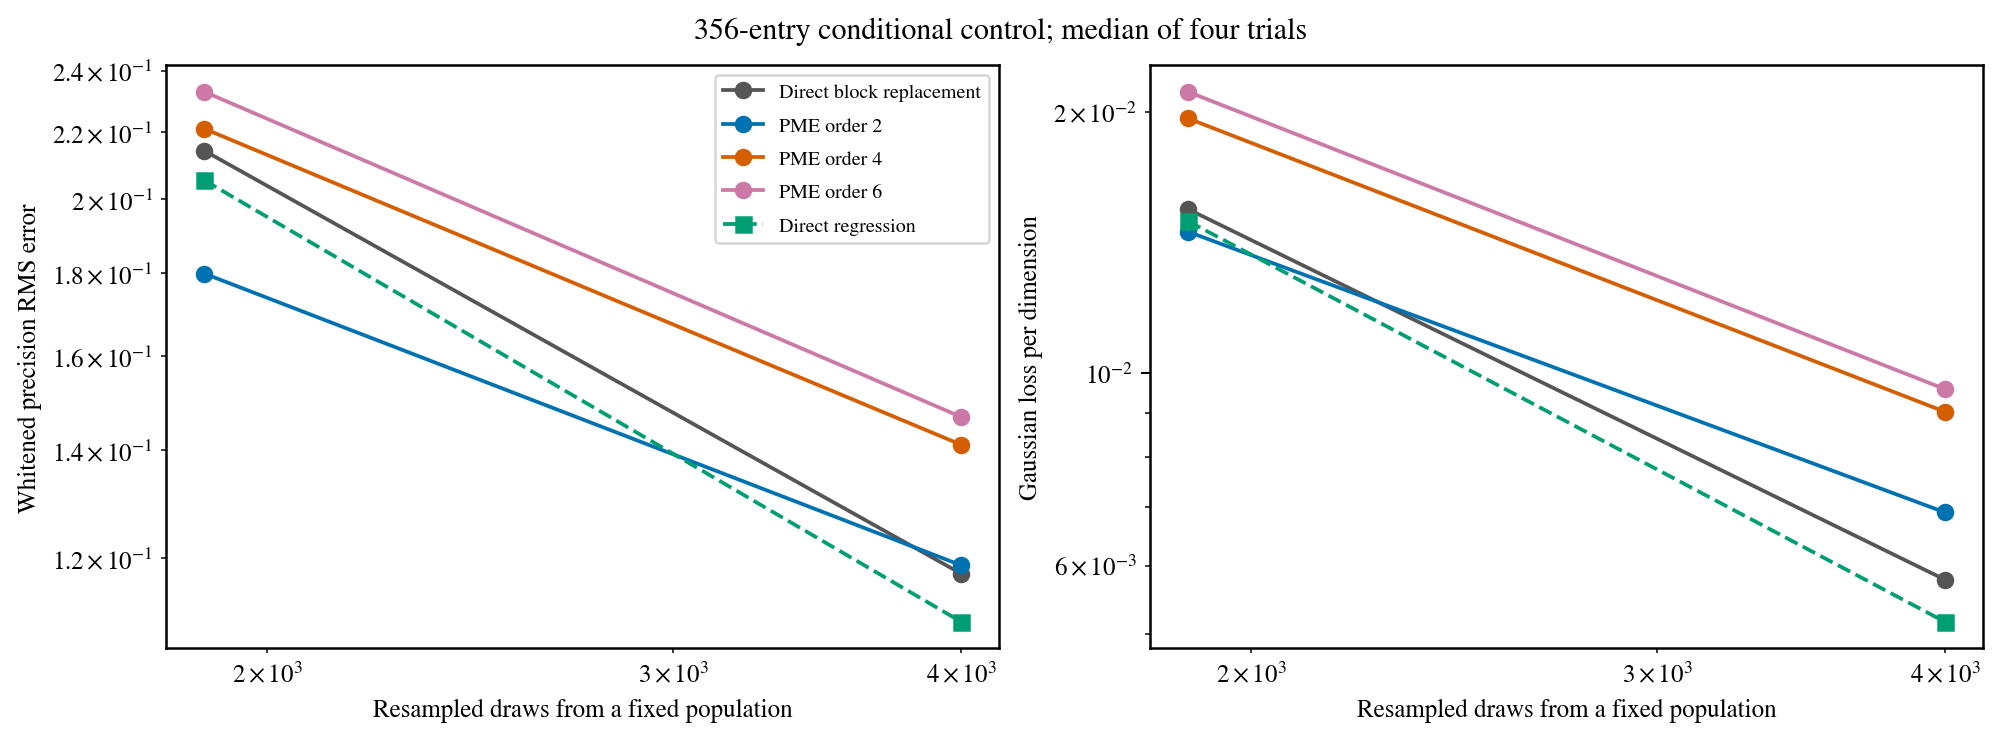

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# These are small trial tables, not the map files. Every estimator used the
# same draws at a given sample count and repetition. Only the auto-source
# subset is included, so the confirmed mixed-source defect is excluded.
results = CHAINS / 'gptg_ensemble_15000/full_joint_comparison_current'
trials = np.loadtxt(results / 'empirical_auto_benchmark_trials.txt')
regression = np.loadtxt(results / 'empirical_auto_regression_trials.txt')
counts = np.array(DRAW_COUNTS[1:])
figure, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
colors = ['#555555', '#0072B2', '#D55E00', '#CC79A7']
labels = ['Direct block replacement', 'PME order 2', 'PME order 4', 'PME order 6']
# RMS precision error and Gaussian loss measure different consequences.
# Show both; selecting only the favorable metric could reverse the ranking.
for order, color, label in zip((0, 2, 4, 6), colors, labels):
    for axis, column in zip(axes, (5, 7)):
        medians = []
        for count in counts:
            selected = trials[(trials[:, 1] == count) & (trials[:, 3] == order)]
            assert np.all(selected[:, 4] == 1), 'Invalid result: do not silently drop it.'
            medians.append(np.median(selected[:, column]))
        axis.plot(counts, medians, 'o-', color=color, label=label)
for axis, column in zip(axes, (3, 5)):
    medians = [np.median(regression[regression[:, 0] == n, column]) for n in counts]
    axis.plot(counts, medians, 's--', color='#009E73', label='Direct regression')
    axis.set_xscale('log')
    axis.set_yscale('log')
    axis.set_xlabel('Resampled draws from a fixed population')
    axis.grid(alpha=.2)
axes[0].set_ylabel('Whitened precision RMS error')
axes[1].set_ylabel('Gaussian loss per dimension')
axes[0].legend(fontsize=8)
figure.suptitle('356-entry conditional control; median of four trials')
# The note's figure comes from the production counts; a laptop run
# saves its own copy under CHAINS instead of replacing it.
plot = (CHAINS if LAPTOP else NOTE) / 'plots/full_joint_audit/empirical_controls.png'
plot.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(plot, dpi=160)
plt.show()


## Exclude small scales before testing the inverse expansion

This uses the complete saved vectors from the audit above and the Gaussian
reference computed above. It runs **no TreeCorr**. Keep the stipulated analytical
two-point block $A$ exactly fixed. Retain only auto-source Map3 rows, which avoid
the confirmed mixed-source measurement defect. Choose xi bins by their lower
angular edge, not their center, and select the aperture radius separately.

For each selection form the **same-data hybrid**

$$C_* = \begin{pmatrix} A & S_{23} \\ S_{32} & S_{33}\end{pmatrix}.$$

Here $S$ is measured from all complete maps. This is our comparison matrix,
not a known truth: using it both to build and judge the correction cannot
establish which estimator has smaller population error.

Write the reference as $M=LL^T$. The dimensionless residual is

$$X=I-L^{-1}C_*L^{-T}.$$

The inverse series converges only when every eigenvalue of $X$ has magnitude
less than one. Check that condition before interpreting higher orders. A positive
conditional precision is necessary to use a result, but does not prove convergence.
The RMS below is $\|L_*^T\widehat\Psi L_*-I\|_F/\sqrt d$, with
$C_*=L_*L_*^T$. It measures a matrix discrepancy, not a parameter-error percentage.

The released simulation $D$ and the approximate Gaussian $D$ are separate
references. Neither changes $A$. The latter has the frozen generator spectra,
full aperture filters and an equal-area circular window; it still does not
match the finite-triangle estimator or include connected GPTG moments.

In [35]:
# Use the complete-map audit above: every selected row uses the same maps.
# No maps or TreeCorr measurements are generated in this comparison.
from itertools import combinations_with_replacement
from astropy.io import fits
from scipy.linalg import solve_triangular
from threadpoolctl import threadpool_limits

large_vectors = np.array([complete[number] for number in sorted(complete)])
large_output = CHAINS / 'gptg_ensemble_15000/full_joint_comparison_current'
gaussian = np.loadtxt(large_output / 'gaussian_reference/gaussian15_refine2.txt')
xi_table = fits.getdata(
    PROJECT / 'data/upstream_y3/data/dv/sim_2pt-NLA-cosmoCosmogrid-04Nov24.fits',
    extname='xip',
)
# Xi+ and xi- use the same angular edges and ten source pairs. Selecting by
# the LOWER edge ensures no bin contains separations below the chosen cut.
xi_lower = np.tile(xi_table['ANGLEMIN'], 2)
triples = list(combinations_with_replacement(range(4), 3))
auto = np.repeat([first == last for first, middle, last in triples], 4)
radii = np.tile([7., 14., 25., 40.], len(triples))
large_records = []
large_cases = {}

with threadpool_limits(limits=1):
    for xi_cut, radius_cut in ((0., 7.), (10., 14.), (20., 25.), (40., 40.), (60., 40.)):
        xi_rows = np.flatnonzero(
            (xi_lower >= xi_cut) & (np.ptp(large_vectors[:, :400], axis=0) > 0),
        )
        # Only auto-source Map3 rows are used. Mixed-source legacy vectors
        # have the shared-pixel defect discussed above and cannot enter here.
        third = np.flatnonzero(auto & (radii >= radius_cut))
        selected = np.r_[xi_rows, 400 + third]
        p = len(xi_rows)
        dimension = len(selected)
        sample = np.cov(large_vectors[:, selected], rowvar=False, ddof=1)
        a = full_reference[np.ix_(xi_rows, xi_rows)]
        target = sample.copy()
        target[:p, :p] = a
        # This hybrid uses the same measured B,D as the correction. It is a
        # comparison matrix, NOT a population truth or independent validation.
        target_factor = np.linalg.cholesky(target)
        for label in ('released_D', 'gaussian_D'):
            model = full_reference[np.ix_(selected, selected)].copy()
            if label == 'gaussian_D':
                model[p:, p:] = gaussian[np.ix_(third, third)]
            lower = np.linalg.cholesky(model)
            inverse = solve_triangular(lower, np.eye(dimension), lower=True)
            residual = np.eye(dimension) - inverse @ target @ inverse.T
            radius = np.max(np.abs(np.linalg.eigvalsh(residual)))
            conditional_factor = lower[p:, p:]
            base_precision = np.linalg.solve(model, np.eye(dimension))
            base_rms = np.linalg.norm(
                target_factor.T @ base_precision @ target_factor - np.eye(dimension),
            ) / np.sqrt(dimension)
            raw_orders = block_orders(large_vectors[:, selected], model, p)
            fitted_orders = []
            for order, raw in zip((2, 4, 6), raw_orders):
                # A positive lower-right raw block is required for the fixed-A
                # reconstruction. Positive output alone does not imply that
                # the inverse series converges; check the residual radius too.
                minimum = np.linalg.eigvalsh(
                    conditional_factor.T @ raw[p:, p:] @ conditional_factor,
                )[0]
                fitted = conditional_precision(raw, a, p)
                rms = np.nan
                if fitted is not None:
                    rms = np.linalg.norm(
                        target_factor.T @ fitted @ target_factor - np.eye(dimension),
                    ) / np.sqrt(dimension)
                # Replace noisy powers by exact powers of THIS sample target.
                # This isolates truncation, without pretending the target is
                # the generator's known population covariance.
                polynomial = sum(np.linalg.matrix_power(residual, j) for j in range(order + 1))
                ideal = conditional_precision(inverse.T @ polynomial @ inverse, a, p)
                ideal_rms = np.nan
                if ideal is not None:
                    ideal_rms = np.linalg.norm(
                        target_factor.T @ ideal @ target_factor - np.eye(dimension),
                    ) / np.sqrt(dimension)
                large_records.append([
                    xi_cut, radius_cut, int(label == 'gaussian_D'), dimension,
                    p, len(third), order, radius, minimum, base_rms, ideal_rms, rms,
                ])
                fitted_orders.append(fitted)
            if xi_cut == 40. and label == 'gaussian_D':
                large_cases['selected'] = selected
                large_cases['a'] = a
                large_cases['p'] = p
                large_cases['model'] = model
                large_cases['target'] = target
                large_cases['precisions'] = fitted_orders
            print(f'xi lower edge >= {xi_cut:g}, R >= {radius_cut:g} arcmin; '
                  f'{label}: {dimension} rows, residual radius {radius:.5f}')
large_records = np.asarray(large_records)
np.savetxt(
    large_output / 'large_scale_notebook_review.txt',
    large_records,
    header='xi_cut R_cut Gaussian_reference dimension nxi nMap3 order residual_radius '
           'min_conditional_precision baseline_RMS exact_polynomial_RMS sampled_PME_RMS; '
           'all RMS compared with SAME-DATA fixed-A hybrid, NOT TRUTH',
)
# The rows quoted below: xi lower edge >= 40 arcmin, R = 40 arcmin, Gaussian D.
chosen = (large_records[:, 0] == 40.) & (large_records[:, 2] == 1)
print('Order, uncorrected-reference RMS, exact-polynomial RMS, sampled PME RMS:')
print(large_records[chosen][:, [6, 9, 10, 11]])


xi lower edge >= 0, R >= 7 arcmin; released_D: 356 rows, residual radius 45.01599


xi lower edge >= 0, R >= 7 arcmin; gaussian_D: 356 rows, residual radius 12.87709


xi lower edge >= 10, R >= 14 arcmin; released_D: 272 rows, residual radius 29.16351


xi lower edge >= 10, R >= 14 arcmin; gaussian_D: 272 rows, residual radius 11.69617


xi lower edge >= 20, R >= 25 arcmin; released_D: 208 rows, residual radius 10.11619


xi lower edge >= 20, R >= 25 arcmin; gaussian_D: 208 rows, residual radius 2.27115


xi lower edge >= 40, R >= 40 arcmin; released_D: 144 rows, residual radius 8.18629


xi lower edge >= 40, R >= 40 arcmin; gaussian_D: 144 rows, residual radius 0.80595


xi lower edge >= 60, R >= 40 arcmin; released_D: 124 rows, residual radius 8.15744


xi lower edge >= 60, R >= 40 arcmin; gaussian_D: 124 rows, residual radius 0.79730
Order, uncorrected-reference RMS, exact-polynomial RMS, sampled PME RMS:
[[2.         0.12021299 0.0654812  0.08335013]
 [4.         0.12021299 0.03849902 0.08145511]
 [6.         0.12021299 0.02349338 0.08512307]]


### Read the measured result without calling the direct matrix truth

For the current 1,878 complete maps, xi bins above 40 arcmin and auto-source
apertures at 40 arcmin retain 144 entries. The Gaussian reference has residual
radius **0.806**. Orders 2, 4 and 6 all give positive conditional precisions.
Their same-data RMS discrepancies are **0.0834, 0.0815 and 0.0851**, compared
with **0.1202** for the uncorrected reference. These are not certified errors
against the unknown covariance. Exact powers of the same-data residual instead
give **0.0655, 0.0385 and 0.0235**: truncation decreases while noisy high-order
products prevent the measured estimates from following that improvement.

The released-$D$ reference remains outside convergence on these same rows:
its radius is **8.19**, despite positive conditional precision at each tested
order. Dropping small scales alone is therefore insufficient. The small set
of retained Map3 entries also cannot answer the original small-scale question.

The following figure has the same-data hybrid above each diagonal and PME
below. The bottom row shows covariance differences using a common normalization.
The unchanged $A$ block should be zero there.

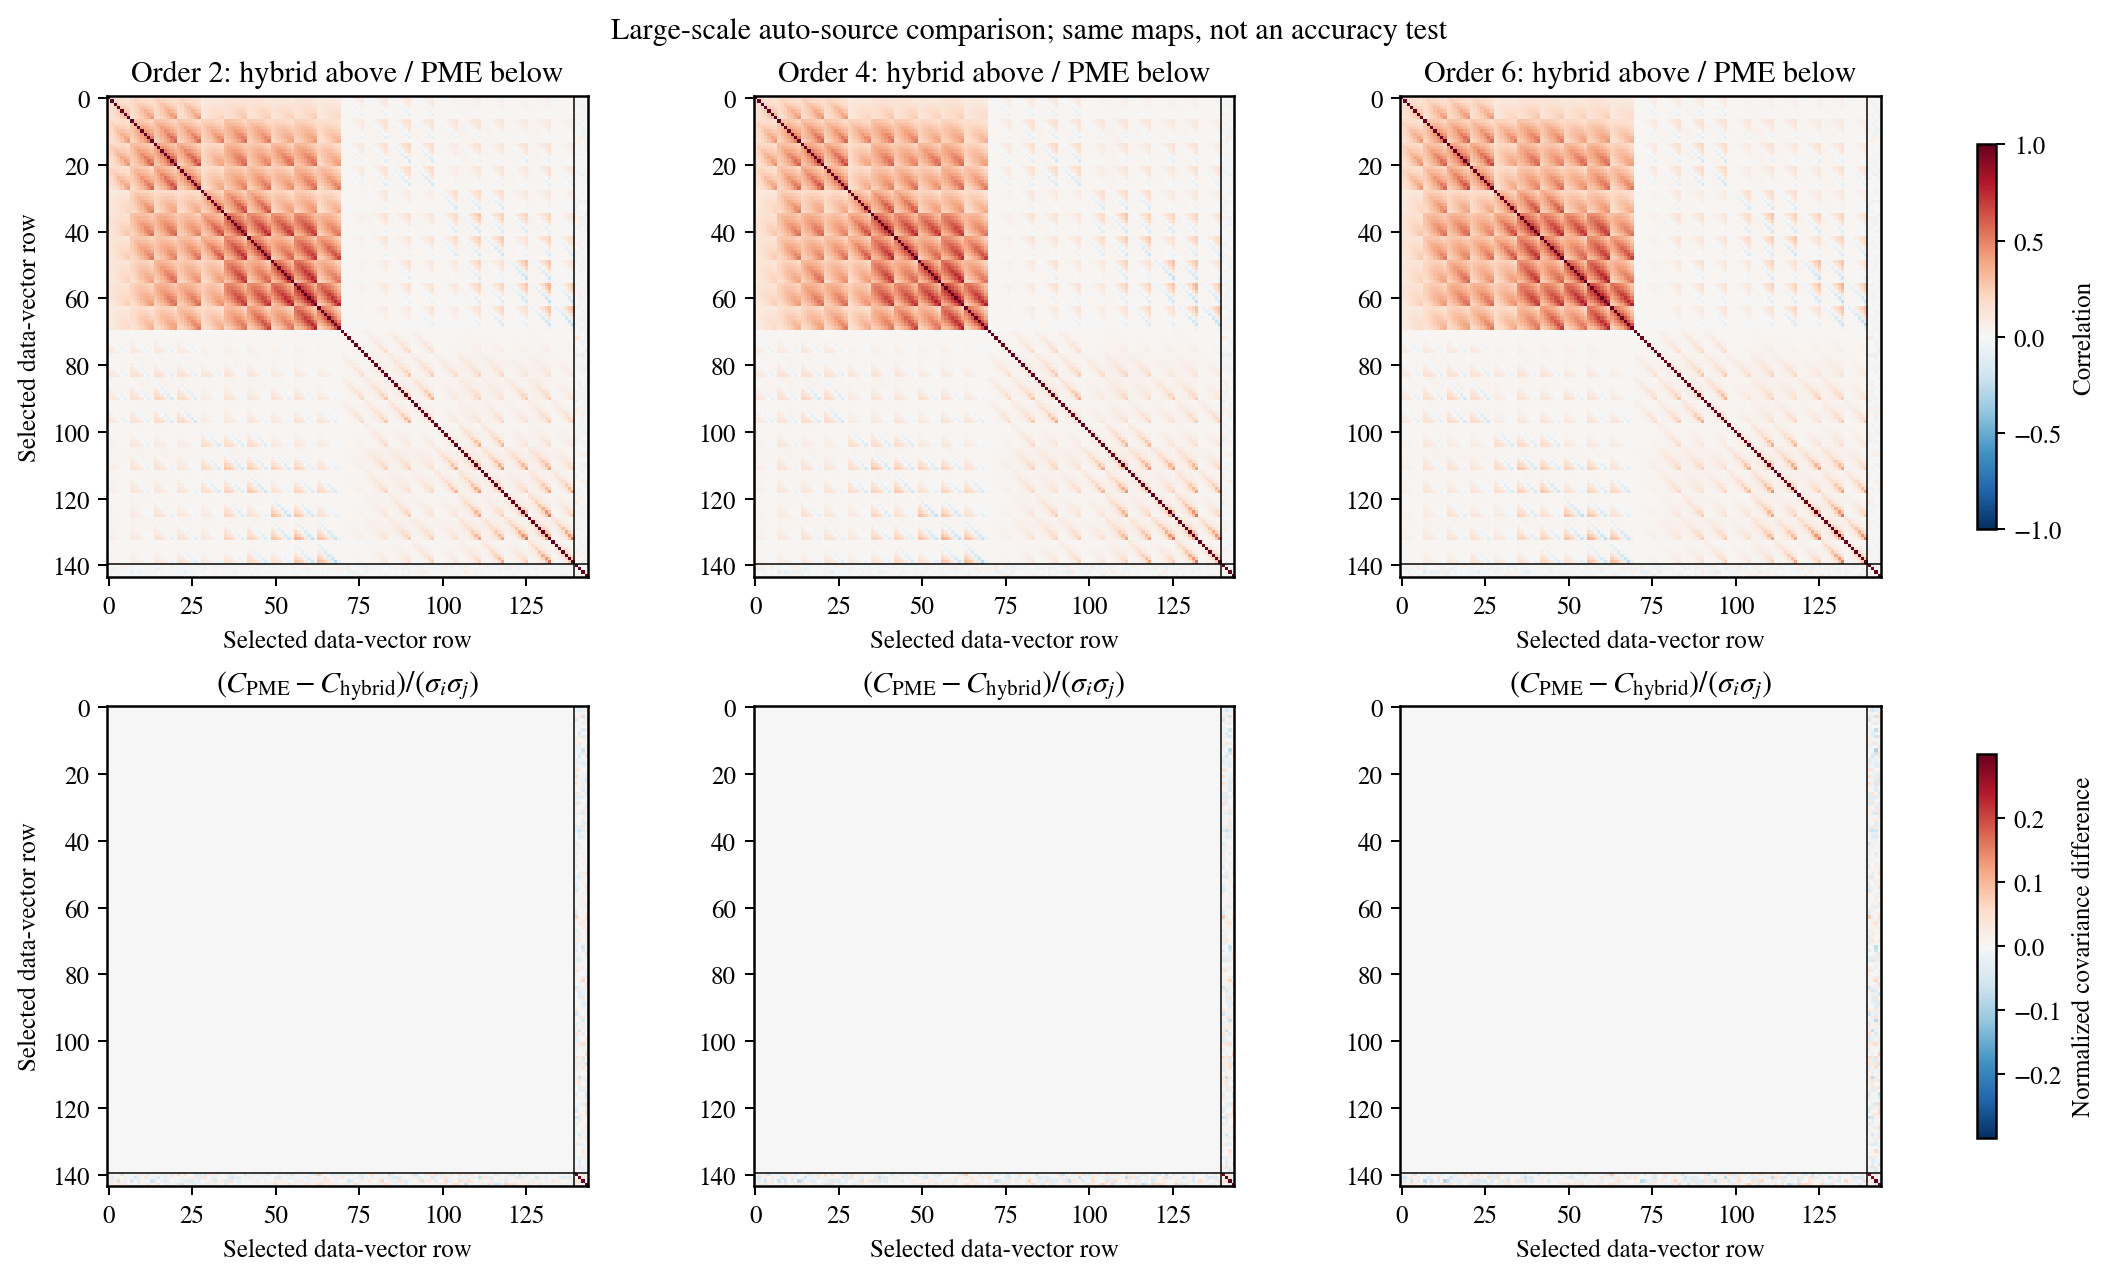

In [36]:
# Compare the same matrix entries, with the same row order and color scale.
# Correlation has unit diagonal; a covariance difference is divided by the
# hybrid's sigma_i sigma_j, so near-zero correlations cannot blow up a ratio.
from matplotlib.colors import TwoSlopeNorm

comparison = large_cases['target']
p = large_cases['p']
dimension = len(comparison)
scale = np.sqrt(np.outer(np.diag(comparison), np.diag(comparison)))
comparison_correlation = comparison / scale
figure, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for column, (order, precision) in enumerate(zip((2, 4, 6), large_cases['precisions'])):
    if precision is None:
        raise ValueError('Cannot plot an invalid precision as a covariance.')
    covariance = np.linalg.solve(precision, np.eye(dimension))
    # The two-point block is stipulated, not re-estimated by this operation.
    np.testing.assert_allclose(covariance[:p, :p], large_cases['a'], rtol=1e-9, atol=1e-30)
    correlation = covariance / np.sqrt(np.outer(np.diag(covariance), np.diag(covariance)))
    split = np.triu(comparison_correlation) + np.tril(correlation, -1)
    top = axes[0, column].imshow(split, vmin=-1., vmax=1., cmap='RdBu_r')
    difference = (covariance - comparison) / scale
    bottom = axes[1, column].imshow(
        difference,
        cmap='RdBu_r',
        norm=TwoSlopeNorm(vmin=-0.3, vcenter=0., vmax=0.3),
    )
    axes[0, column].set_title(f'Order {order}: hybrid above / PME below')
    axes[1, column].set_title(r'$(C_\mathrm{PME}-C_\mathrm{hybrid})/(\sigma_i\sigma_j)$')
    for axis in axes[:, column]:
        axis.axhline(p - .5, color='black', linewidth=.6)
        axis.axvline(p - .5, color='black', linewidth=.6)
        axis.set_xlabel('Selected data-vector row')
axes[0, 0].set_ylabel('Selected data-vector row')
axes[1, 0].set_ylabel('Selected data-vector row')
figure.colorbar(top, ax=axes[0, :].tolist(), label='Correlation', shrink=.8)
figure.colorbar(bottom, ax=axes[1, :].tolist(), label='Normalized covariance difference', shrink=.8)
figure.suptitle('Large-scale auto-source comparison; same maps, not an accuracy test')
figure.savefig(large_output / 'large_scale_covariances.png', dpi=160)
plt.show()


### Does changing pair order explain the higher-order scatter?

Permute the independent map pairs, then average the raw precision polynomials
before imposing the fixed-A conditional form. All permutations reuse the same
maps. The recorded sixteen-ordering average changes the fourth-/sixth-order
same-data RMS to 0.0810/0.0831. Second order stays 0.08335. This modest change
identifies ordering variance but does not establish population accuracy or
supply independent validation.

In [37]:
# Pair ordering changes the higher-degree ordered-products estimator, even
# though every ordering has the same expectation. Preserve each independent
# map pair and permute only the order in which those pairs enter the recurrence.
selected = large_cases['selected']
model = large_cases['model']
a = large_cases['a']
p = large_cases['p']
dimension = len(selected)
values = large_vectors[:, selected]
even_count = len(values) // 2 * 2
pairs = values[:even_count].reshape(-1, 2, dimension)
target_factor = np.linalg.cholesky(large_cases['target'])
rng = np.random.default_rng(20261122)
raw_sum = [np.zeros_like(model) for order in (2, 4, 6)]
order_records = []
with threadpool_limits(limits=1):
    for repeat in range(16):
        reordered = pairs[rng.permutation(len(pairs))].reshape(-1, dimension)
        for index, raw in enumerate(block_orders(reordered, model, p)):
            raw_sum[index] += raw
        if repeat + 1 in (1, 2, 4, 8, 16):
            for order, total in zip((2, 4, 6), raw_sum):
                # Average raw polynomials first. Conditional reconstruction is
                # nonlinear, so averaging final covariances is a different test.
                precision = conditional_precision(total / (repeat + 1), a, p)
                rms = np.nan
                if precision is not None:
                    rms = np.linalg.norm(
                        target_factor.T @ precision @ target_factor - np.eye(dimension),
                    ) / np.sqrt(dimension)
                order_records.append([repeat + 1, order, rms])
np.savetxt(
    large_output / 'large_scale_order_review.txt',
    order_records,
    header='pair_orderings PME_order RMS_vs_same_data_hybrid_NOT_TRUTH',
)
print(np.array(order_records))
# These are repeated algebraic uses of the same maps, not additional skies.
# Pair-order averaging reduces one variance contribution; it cannot remove
# the sampling uncertainty shared by every permutation.


[[ 1.          2.          0.08335013]
 [ 1.          4.          0.08192759]
 [ 1.          6.          0.08625064]
 [ 2.          2.          0.08335013]
 [ 2.          4.          0.08121268]
 [ 2.          6.          0.08414954]
 [ 4.          2.          0.08335013]
 [ 4.          4.          0.08102049]
 [ 4.          6.          0.08327476]
 [ 8.          2.          0.08335013]
 [ 8.          4.          0.08101587]
 [ 8.          6.          0.08313129]
 [16.          2.          0.08335013]
 [16.          4.          0.08100379]
 [16.          6.          0.08312939]]


## A bounded NSIDE2048 generation test

The CPU generator can refine the original RING footprint through exact NESTED
parent/child indices. The ten-map engineering test is recorded in
[the generation checks](../../tests/gptg_pilot/nside2048_generation.txt).
The [README](../../README.md#cpu-map-generation) explains the single CPU-only
Slurm script and its environment keys. No production run is started here.

The pilot **retains lmax=1024 and the existing calibration**. More pixels alone
do not supply missing high-multipole signal. Independent pixel-noise standard
deviation increases by four from NSIDE512 to NSIDE2048, preserving noise power
per solid angle. New maps retain the coarse footprint boundary. Before a new
small-scale scientific ensemble, extend and validate the harmonic model,
measure memory at that cutoff, and validate TreeCorr's matching geometry.

## What maximum multipole did the published pipeline use?

Several distinct indices appear in the papers. Do not interchange them.

| Quantity | Verified setting |
|---|---|
| Final covariance-map pixels | NSIDE1024 in [the methods paper](https://arxiv.org/html/2503.03964v2#S3) |
| TreeCorr opening-angle Fourier order | 100 in that paper |
| Bispectrum triangle-angle Legendre order | $L_{\max}=50$ in [the TATT paper](https://arxiv.org/html/2601.09133v1#S2.SS6) |
| Natural-component triangle-angle order | $M_{\max}=100$ in that paper |
| Sky-map spherical-harmonic cutoff | Not established by the inspected papers/pipeline |

The inspected `3pcf_integrator/python/fastnc_interface.py` multiplies theory
by a HEALPix pixel window for NSIDE1024 and zero-fills beyond $\ell=3071$.
This is a choice in the **theory window**, not evidence of the map generator's
harmonic cutoff. The local supplied maps are NSIDE512; our current target
spectrum stops at 1024 and its fitted PDF uses a Gaussian-smoothed
masked reconstruction with width $\sigma=10$ arcmin (FWHM $\simeq23.55$ arcmin). Finer pixels do not supply the absent high-$\ell$
power or calibrate an unsmoothed convergence PDF.

The following cells test arithmetic and sampling with known inputs. They
cannot certify missing high-frequency DES physics. Keep production paused
until the target spectrum/PDF and matching measurement have been specified.

### Check a filter weight with an exact integral

For a compensated Gaussian aperture the Fourier filter is

$$\widehat U(x)=\frac{x^2}{2}e^{-x^2/2},\qquad x=\ell R.$$

With constant angular power, aperture variance weights $x^5e^{-x^2}dx$.
Substitute $t=x^2$ to evaluate the fraction above a cutoff:

$$f_{>L}=e^{-(LR)^2}\left[1+(LR)^2+\frac{(LR)^4}{2}\right].$$

At $R=7'$ this is 0.19146 for $L=1024$, and $4.75\times10^{-6}$ for
$L=2048$. These are **filter-norm fractions for a flat spectrum**, not a
DES covariance error or a correction to our already-added pixel noise.
Finite-triangle Map3 and the small-angle $\xi_\pm$ rows require their own checks.

In [38]:
from scipy.integrate import quad
from scipy.special import gammaincc

# This is an exactly known filter-weight example, not a fitted sky spectrum.
# For constant C_ell and U_hat(x)=x^2 exp(-x^2/2)/2, aperture variance weights
# x^5 exp(-x^2) dx. Its total integral is Gamma(3)/2 = 1.
project = PROJECT
records=[]
for radius_arcmin in (7.,14.,25.,40.):
    radius = np.deg2rad(radius_arcmin / 60.)
    for cutoff in (1024,2048,3071,4096,6143):
        lower = cutoff * radius
        square = lower**2
        tail = np.exp(-square) * (1. + square + square**2 / 2.)
        integral = quad(lambda x: x**5*np.exp(-x*x), lower, np.inf,
                        epsabs=1e-13, epsrel=1e-11)[0]
        np.testing.assert_allclose(tail, gammaincc(3., square), rtol=2e-13, atol=1e-300)
        np.testing.assert_allclose(tail, integral, rtol=1e-7, atol=1e-13)
        records.append([radius_arcmin,cutoff,tail])
        print(radius_arcmin,cutoff,tail)
output=CHAINS/'gptg_harmonic_validation'
output.mkdir(parents=True,exist_ok=True)
np.savetxt(output/'aperture_filter_tail.txt',records,
           header='radius_arcmin harmonic_cutoff flat_C_ell_filter_variance_tail_fraction_NOT_actual_sky_error')


7.0 1024 0.19146094821800091
7.0 2048 4.752266416595364e-06
7.0 3071 8.384085943074542e-15
7.0 4096 1.534851757176733e-27
7.0 6143 1.388940274687946e-64
14.0 1024 4.752266416595364e-06
14.0 2048 1.534851757176733e-27
14.0 3071 1.4605745213506831e-64
14.0 4096 5.629219764417776e-117
14.0 6143 3.095073120195543e-267
25.0 1024 1.3157325849142888e-21
25.0 2048 1.1522943857938393e-92
25.0 3071 3.073587733474389e-212
25.0 4096 0.0
25.0 6143 0.0
40.0 1024 2.2704726781866908e-58
40.0 2048 3.941838967409841e-242
40.0 3071 0.0
40.0 4096 0.0
40.0 6143 0.0


### Recover a known band-limited sky before testing nonlinear maps

Synthesis maps known harmonic coefficients onto pixels. Analysis tries to
recover those coefficients. The relative error is the square root of the summed squared coefficient
errors divided by the summed squared input coefficients, counting both signs
of $m$. The exact input is known, so this check does not need simulated-covariance
truth. Use the generator's tolerance and iteration limit, and report failure
rather than loosening them after inspecting an answer.

These cells allocate full skies and can take minutes at high cutoff. Test
one case at a time with four native threads and BLAS=1. The recorded cutoff
6143 case failed, despite being an exactly band-limited scalar field.

In [39]:
import gc
import resource
import sys
import time
import ducc0


def harmonic_roundtrip(lmax, spin, nside=2048):
    """Recover known harmonics at a specified cutoff and pixel resolution.

    This is a numerical test, not a fitted DES realization. Spin zero uses
    a scalar sky; spin two uses known E and B coefficients. The production
    solver settings are held fixed so a failure applies to those settings.
    Run from a fresh kernel when comparing peak process memory: ru_maxrss
    also includes earlier cells and is not the allocation of this call alone.
    """
    geometry = ducc0.healpix.Healpix_Base(nside, 'RING').sht_info()
    size = (lmax + 1) * (lmax + 2) // 2
    coefficients = np.zeros((1 if spin == 0 else 2, size), dtype=np.complex128)
    # The final modes probe the band edge at both small and large m. A test
    # containing only low multipoles would miss the difficult polar modes.
    entries = [
        (2, 0, .3), (13, 3, .2 + .15j), (101, 72, .1 - .1j),
        (lmax - 1, 0, .5), (lmax, lmax // 2, .4 + .3j), (lmax, lmax, .3 - .2j),
    ]
    for ell, m, amplitude in entries:
        # ducc0 stores nonnegative m in successive blocks, with ell >= m.
        index = m * (2 * lmax + 1 - m) // 2 + ell
        coefficients[0, index] = amplitude
        if spin:
            coefficients[1, index] = amplitude / 4.
    start = time.monotonic()
    field = ducc0.sht.synthesis(
        alm=coefficients,
        spin=spin,
        lmax=lmax,
        nthreads=THREADS,
        **geometry,
    )
    synthesis_seconds = time.monotonic() - start
    start = time.monotonic()
    recovered = ducc0.sht.pseudo_analysis(
        map=field,
        spin=spin,
        lmax=lmax,
        nthreads=THREADS,
        maxiter=30,
        epsilon=1.e-6,
        **geometry,
    )
    analysis_seconds = time.monotonic() - start
    error_square = 0.
    reference_square = 0.
    # Negative-m coefficients are fixed by the reality of the sky. Their
    # equal contribution doubles every m>0 term; m=0 is counted once.
    # Accumulate short chunks instead of another full harmonic-size array.
    for begin in range(0, size, 100000):
        end = min(size, begin + 100000)
        weight = np.full(end - begin, 2.)
        weight[:max(0, min(end, lmax + 1) - begin)] = 1.
        difference = recovered[0][:, begin:end] - coefficients[:, begin:end]
        error_square += np.sum(weight * np.abs(difference)**2)
        reference_square += np.sum(weight * np.abs(coefficients[:, begin:end])**2)
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    if sys.platform != 'darwin':
        peak *= 1024  # Linux reports KiB; macOS reports bytes.
    return dict(
        nside=nside,
        lmax=lmax,
        spin=spin,
        status=recovered[1],
        iterations=recovered[2],
        relative_map_residual=recovered[3],
        relative_harmonic_error=np.sqrt(error_square / reference_square),
        synthesis_seconds=synthesis_seconds,
        analysis_seconds=analysis_seconds,
        process_peak_bytes=peak,
    )


# Change one setting at a time. L=6143 reached the iteration limit in the
# recorded scalar test; there is no need to run that failing case routinely.
roundtrip_result = harmonic_roundtrip(lmax=ROUNDTRIP_LMAX, spin=0, nside=NSIDE)
print(roundtrip_result)
gc.collect()


{'nside': 1024, 'lmax': 1024, 'spin': 0, 'status': 1, 'iterations': 2, 'relative_map_residual': 4.0970018828439656e-08, 'relative_harmonic_error': 4.096997888361599e-08, 'synthesis_seconds': 0.18491433304734528, 'analysis_seconds': 1.400534125044942, 'process_peak_bytes': 1190936576}


399

### A converged solve is not necessarily a correct nonlinear projection

Take a known axisymmetric field

$$g(\theta)=\sqrt{2q+1}\,P_q(\cos\theta).$$

Its sky mean is zero and its mean square is one. Form

$$\kappa=g+0.1(g^2-1).$$

This has modes through $2q$, even if the input stops at $q$. We retain only
modes through $L<2q$. Exact spherical projection gives

$$a_{\ell0}=\sqrt{\pi(2\ell+1)}\int_{-1}^{1}\kappa(\mu)P_\ell(\mu)\,d\mu.$$

The integrand is a polynomial; an adequately high Gauss-Legendre rule
therefore supplies a reference independent of HEALPix sampling. Compare
that reference with the pixel-based least-squares solution. A small solver
gradient only says that the **discrete** fit has converged; it does not
prove agreement with this continuous spherical integral.

In [40]:
from scipy.special import roots_legendre, eval_legendre


def nonlinear_projection(nside, lmax):
    """Compare a sampled nonlinear field with its exact harmonic projection.

    The axisymmetric input g has unit sky-averaged square. Squaring it
    creates harmonics above the retained cutoff. Gauss-Legendre quadrature
    integrates this polynomial example without a pixel-grid approximation.
    The polar concentration deliberately makes this a demanding test; its
    error is not a prediction of the error in a random DES-like sky.
    """
    input_ell = 3 * lmax // 4
    geometry = ducc0.healpix.Healpix_Base(nside, 'RING').sht_info()
    coefficients = np.zeros((1, lmax + 1), dtype=np.complex128)
    # sqrt(4pi) Y_{ell,0} = sqrt(2ell+1) P_ell(cos theta).
    coefficients[0, input_ell] = np.sqrt(4 * np.pi)
    field = ducc0.sht.synthesis(
        alm=coefficients,
        spin=0,
        lmax=lmax,
        mmax=0,
        nthreads=THREADS,
        **geometry,
    )
    field += .1 * (field * field - 1.)
    recovered = ducc0.sht.pseudo_analysis(
        map=field,
        spin=0,
        lmax=lmax,
        mmax=0,
        nthreads=THREADS,
        maxiter=30,
        epsilon=1.e-6,
        **geometry,
    )
    del field
    references = []
    for extra_nodes in (0, 32):
        # The projection integrand has degree at most 2*input_ell+lmax.
        # An n-node Gaussian rule integrates through degree 2n-1. Increasing
        # its count independently checks floating-point reference accuracy.
        count = (2 * input_ell + lmax + 2) // 2 + extra_nodes
        mu, weight = roots_legendre(count)
        gaussian = np.sqrt(2 * input_ell + 1) * eval_legendre(input_ell, mu)
        transformed = gaussian + .1 * (gaussian * gaussian - 1.)
        weighted_field = weight * transformed
        exact = np.empty(lmax + 1)
        previous = np.ones_like(mu)
        current = mu.copy()
        exact[0] = np.sqrt(np.pi) * (weighted_field @ previous)
        exact[1] = np.sqrt(3 * np.pi) * (weighted_field @ current)
        # Build Legendre polynomials successively, retaining only two rows.
        for ell in range(2, lmax + 1):
            following = ((2 * ell - 1) * mu * current - (ell - 1) * previous) / ell
            exact[ell] = np.sqrt(np.pi * (2 * ell + 1)) * (weighted_field @ following)
            previous, current = current, following
        references.append(exact)
    error = recovered[0][0].real - references[0]
    normalization = np.linalg.norm(references[0])
    return dict(
        nside=nside,
        lmax=lmax,
        input_ell=input_ell,
        nonlinear_maxell=2 * input_ell,
        status=recovered[1],
        iterations=recovered[2],
        relative_harmonic_error=np.linalg.norm(error) / normalization,
        low_ell_error_over_full_norm=np.linalg.norm(error[:101]) / normalization,
        reference_refinement=np.linalg.norm(references[1] - references[0]) / normalization,
    )


# Both cases use the same continuous field and retained cutoff. Only the
# pixel sampling changes. This distinguishes projection error from changing
# the sky model or adding new physical high-ell power.
for pixel_nside in (NSIDE, FINE_NSIDE):
    print(nonlinear_projection(nside=pixel_nside, lmax=LMAX))
    gc.collect()


{'nside': 1024, 'lmax': 2048, 'input_ell': 1536, 'nonlinear_maxell': 3072, 'status': 2, 'iterations': 4, 'relative_harmonic_error': 0.017043077203513595, 'low_ell_error_over_full_norm': 0.0007982299168798298, 'reference_refinement': 3.494274454334952e-08}


{'nside': 2048, 'lmax': 2048, 'input_ell': 1536, 'nonlinear_maxell': 3072, 'status': 2, 'iterations': 3, 'relative_harmonic_error': 0.0033233866902745686, 'low_ell_error_over_full_norm': 0.00016304268290545413, 'reference_refinement': 3.494274454334952e-08}


### Repeat with a smoother random field

The axisymmetric polynomial concentrates power near the poles. Here all
harmonic m modes are populated using a synthetic smooth spectrum and one
of the fitted point functions. The coefficients and random seed are identical
on both working grids. This tests a more representative numerical input,
without claiming that its invented spectrum calibrates high-ell DES power.
These are full-sky transforms; the finer grid uses several GB of memory.
With the production settings (NSIDE 2048 and 4096, multipole 4096) the overall
coefficient difference was 0.002912%, with 0.02475% in the highest band; the
laptop run prints its own relative differences. Agreement on one sky is not a covariance-accuracy bound.

In [41]:
from generate_maps import harmonic_indices, normalized_transform
from scipy.special import roots_hermitenorm

# This spectrum is chosen only for a controlled numerical test. It is NOT
# a continuation fitted to Rafael's maps or a replacement calibration.
lmax = LMAX
ell = harmonic_indices(lmax=lmax)
multipoles = np.arange(lmax + 1)
cl = (multipoles + 10.)**-2.5
cl[:2] = 0.
cl /= np.sum((2 * multipoles + 1) * cl) / (4 * np.pi)
rng = np.random.default_rng(76418)
coefficients = (rng.normal(size=len(ell)) + 1j * rng.normal(size=len(ell))) / np.sqrt(2.)
coefficients[:lmax + 1] = np.sqrt(2.) * coefficients[:lmax + 1].real
coefficients *= np.sqrt(cl[ell])
coefficients = coefficients[None, :]
nodes, weights = roots_hermitenorm(160)
weights /= np.sqrt(2 * np.pi)
with np.load(PROJECT / 'chains/gptg_ensemble_15000/calibration.npz') as calibration:
    parameters = calibration['parameters'][0].copy()
recovered_fields = []
for pixel_nside in (NSIDE, FINE_NSIDE):
    geometry = ducc0.healpix.Healpix_Base(pixel_nside, 'RING').sht_info()
    gaussian = ducc0.sht.synthesis(
        alm=coefficients,
        spin=0,
        lmax=lmax,
        nthreads=THREADS,
        **geometry,
    )
    convergence = normalized_transform(
        gaussian=gaussian,
        parameters=parameters,
        nodes=nodes,
        weights=weights,
    )
    # Keep only the transformed pixels during analysis. This one-bin test
    # does not measure the memory peak of the full four-bin generator.
    del gaussian
    recovered = ducc0.sht.pseudo_analysis(
        map=convergence,
        spin=0,
        lmax=lmax,
        nthreads=THREADS,
        maxiter=30,
        epsilon=1.e-6,
        **geometry,
    )
    del convergence
    if recovered[1] not in (1, 2):
        raise RuntimeError(f'Projection did not converge: {recovered[1:]}')
    print('NSIDE/status/iterations:', pixel_nside, recovered[1], recovered[2])
    recovered_fields.append(recovered[0])
    gc.collect()

# Both arrays have the SAME retained modes and SAME Gaussian input. The
# finer-grid result is a comparison, not exact truth. Show coefficient and
# power changes: a small total power difference can conceal mode errors.
weight = np.full(len(ell), 2.)
weight[:lmax + 1] = 1.
# All modes, the largest scales, then four equal multipole bands.
quarter = lmax // 4
bands = ((0, lmax + 1), (2, 101), (101, quarter + 1), (quarter + 1, 2 * quarter + 1),
         (2 * quarter + 1, 3 * quarter + 1), (3 * quarter + 1, lmax + 1))
for low, high in bands:
    keep = (ell >= low) & (ell < high)
    coarse = recovered_fields[0][0, keep]
    fine = recovered_fields[1][0, keep]
    norm_square = np.sum(weight[keep] * np.abs(fine)**2)
    relative_error = np.sqrt(np.sum(weight[keep] * np.abs(coarse - fine)**2) / norm_square)
    power_change = np.sum(weight[keep] * (np.abs(coarse)**2 - np.abs(fine)**2)) / norm_square
    print(low, high - 1, relative_error, power_change)
del recovered_fields, recovered, coefficients, ell, weight
gc.collect()


NSIDE/status/iterations: 1024 2 7


NSIDE/status/iterations: 2048 2 4
0 2048 4.4599133056589494e-05 2.5743538061853135e-08
2 100 6.346904818649328e-07 1.096258479134056e-08
101 512 5.426576842138686e-06 -2.2875027856861428e-08
513 1024 2.5182180632336854e-05 4.540753579018969e-09
1025 1536 8.823257864045253e-05 2.089667281139743e-07
1537 2048 0.00031566451021941577 1.0553180494501326e-06


0

### Measure the complete worker, not only one transform

The full four-source-bin kernel retains more arrays than the scalar test.
With the production settings (NSIDE 2048, cutoff 4096) the measured peak was
6.737 GiB and the calculation took 132.5 s with four CPU threads; the laptop
run prints its own, smaller values. Ninety workers would project to 606 GiB/node, exceeding
the current allocation. A smaller worker count must be measured on HPC
before launching a higher-cutoff ensemble. The existing Slurm allocation
was tested only at the lower cutoff; this test does not change it silently.

The following cell reproduces the full-kernel memory experiment. Start from
a fresh kernel and run the imports/path setup and the transform-test imports
first; do not run every preceding calculation before measuring process peak.
No scientific map is retained or replaced. The full record is
[high_multipole_validation.txt](../../tests/gptg_pilot/high_multipole_validation.txt).

In [42]:
# Run in a FRESH kernel for an interpretable process-memory measurement.
# This calls the actual production kernel once on explicitly synthetic
# spectra. It writes one temporary map, reads its small diagnostics, then
# removes it. It does not add a map to either scientific ensemble.
import tempfile
from generate_ensemble_mpi import generate_one
from generate_maps import setup, aperture_weights

lmax = LMAX
with np.load(PROJECT / 'chains/gptg_ensemble_15000/calibration.npz') as calibration:
    data = {name: calibration[name] for name in calibration.files}
record = yaml.safe_load((PROJECT / 'chains/gptg_ensemble_15000/calibration.yaml').read_text())
record['lmax'] = lmax
indices, geometry, ell, factor, nodes, weights = setup(
    lmax=lmax,
    nside=NSIDE,
    indices=np.load(PROJECT / 'chains/gptg_ensemble_15000/indices_512.npy'),
    index_nside=512,
)
first, second, centers = aperture_weights(indices=indices, nside=NSIDE)
multipoles = np.arange(lmax + 1)
cl = (multipoles + 10.)**-2.5
cl[:2] = 0.
cl /= np.sum((2 * multipoles + 1) * cl) / (4 * np.pi)
# Independent source fields fill all four coefficient arrays. Independence
# here is a memory-test choice, not a model of tomographic source correlations.
roots = np.sqrt(cl)[:, None, None] * np.eye(4)[None, :, :]
variance = np.full(4, 1.e-4)
# Pixel noise grows as NSIDE/512 to keep the angular white-noise power.
data['noise_sigma'] = NSIDE // 512 * data['noise_sigma']
with tempfile.TemporaryDirectory(dir=CHAINS, prefix='harmonic-memory-') as directory:
    diagnostics = []
    start = time.monotonic()
    generate_one(
        path=Path(directory) / 'toy.npy',
        seed=427,
        record=record,
        data=data,
        indices=indices,
        geometry=geometry,
        ell=ell,
        factor=factor,
        nodes=nodes,
        weights=weights,
        roots=roots,
        variance=variance,
        first=first,
        second=second,
        workers=THREADS,
        precision='float64',
        point_device='cpu',
        diagnostics=diagnostics,
    )
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    if sys.platform != 'darwin':
        peak *= 1024
    print('Elapsed seconds:', time.monotonic() - start)
    print('Process peak GiB:', peak / 1024**3)
    print('Per-source stage diagnostics:', diagnostics)
# ru_maxrss cannot be reset. Previous notebook computations can increase the
# reported peak, hence the fresh-kernel instruction. The recorded benchmark
# used a fresh process and is not an estimate for every cutoff or model.


Elapsed seconds: 65.65789416711777
Process peak GiB: 3.189971923828125
Per-source stage diagnostics: [[0, 0.5490563749335706, 0.35658645792864263, 9.040112040936947, 2.8986658749636263, 2, 7, 0.0015516288848286576, 4.345071758025758e-12], [1, 0.7316359169781208, 0.3790255000349134, 11.240613291040063, 2.4850694169290364, 2, 7, 0.002743784187764719, 5.019609516844589e-12], [2, 0.5992056247778237, 0.436064625158906, 10.809347125003114, 4.374407832976431, 2, 7, 0.000534896048539108, 1.589799833668268e-11], [3, 0.707853666972369, 0.5129700000397861, 14.810553125105798, 5.015728666912764, 2, 7, 0.00041268176842412693, 2.4692590311830673e-11]]


### From numerical probes to a specified model

The next section supplies the physical power and prescribed point functions,
tests them numerically, and records the remaining observable-cutoff limitation.


## Prepare the physical-power model through multipole 4096 (2048 on a laptop)

This section defines a **controlled, band-limited GPTG model**, not a new fit
of high-resolution DES simulations. The maps retain total Omega_m=0.26 and
mnu=0.06 eV. The analytical two-point block uses the same total Omega_m with
mnu=0, as the chosen approximation. Only cross and Map3 blocks receive PME.

Run these cells deliberately, in order, in an activated Cocoa kernel. They
prepare theory and bounded numerical checks; they do not launch an ensemble
or TreeCorr. Large intermediate arrays need several GiB. The common-sky
NSIDE4096 comparison is more demanding than a production NSIDE2048 worker.
The README describes the separate HPC launch after the package is written.

The point-function parameters are prescribed from the committed pilot fit.
Increasing the target harmonic range requires a new Gaussian-spectrum
inversion. Merely editing `lmax` in the old calibration would not do that.

In [43]:
# Functions of this notebook
def point_at_sigma8(model, point, sigma8):
    """Return a copy of a parameter point whose As_1e9 gives CAMB's sigma8.

    The maps are defined by sigma8 = 0.84, but the YAML samples As_1e9 and
    derives sigma8. With every other parameter fixed, CAMB's linear sigma8
    is proportional to A_s^(1/2), so one evaluation at the current As_1e9
    gives the exact rescaling. A second evaluation checks the result.

    Arguments:
      model = open Cobaya model of a numbered example.
      point = dictionary of its input parameters, with As_1e9.
      sigma8 = target value of CAMB's derived sigma8.
    Returns:
      a new dictionary, equal to point except for As_1e9.
    Raises:
      AssertionError if the rescaled sigma8 differs from the target by
      more than 1e-12 relative.
    """
    _, derived = model.loglikes(params_values=point, return_derived=True, as_dict=True)
    result = dict(point)
    result["As_1e9"] = point["As_1e9"] * (sigma8 / derived["sigma8"]) ** 2
    _, derived = model.loglikes(params_values=result, return_derived=True, as_dict=True)
    assert abs(derived["sigma8"] / sigma8 - 1.0) < 1.0e-12, derived["sigma8"]
    return result


In [44]:
# Use the same numbered Cobaya model as ordinary evaluation. The YAML theory
# owns CAMB; this notebook only selects the cosmological point and accuracy.
from cobaya.model import get_model
from cobaya.yaml import yaml_load_file, yaml_dump_file
ROOT = PROJECT.parents[1]
os.chdir(ROOT)  # Numbered Cocoa YAML paths are relative to Cocoa/.
sys.path.insert(0, str(PROJECT / 'interface'))
import cosmolike_des_3pcf_interface as ci
folder = CHAINS / f'gptg_physical_l{LMAX}'
folder.mkdir(parents=True, exist_ok=True)
point = yaml_load_file(str(PROJECT / 'EXAMPLE_EVALUATE3.yaml'))['sampler']['evaluate']['override']
# The map cosmology. Its sigma8 = 0.84 is set inside each model below,
# through As_1e9 (point_at_sigma8), because sigma8 is derived.
point.update(
    omegam=0.26,
    omegab=0.0493,
    H0=67.3,
    ns=0.9649,
    DES_A1_1=0.,
    DES_A1_2=0.,
    DES_M1=0.,
    DES_M2=0.,
    DES_M3=0.,
    DES_M4=0.,
)
ells = np.arange(2., LMAX + 1.)
pairs = np.array([(i, j) for i in range(4) for j in range(i, 4)], dtype=np.int32)
# Compare the matter-power range at fixed refined numerical settings.
# The second spectrum becomes the model input, not an extrapolation of
# the old NSIDE512 calibration. No IA or baryonic response is present.
for name, kmax in [('k20', 20.), ('k40', 40.)]:
    info = yaml_load_file(str(PROJECT / 'EXAMPLE_EVALUATE3.yaml'))
    info.pop('sampler')
    info.pop('output', None)
    info['timing'] = False
    settings = info['likelihood']['des_3pcf.joint_shear']
    settings.update(
        omp_threads=THREADS,
        accuracyboost=4.,
        integration_accuracy=2,
        power_nz=125,
        power_nk=512,
        kmax_boltzmann=kmax,
    )
    info['theory']['camb']['extra_args'].update(kmax=kmax, AccuracyBoost=2.)
    yaml_dump_file(
        str(folder / (name + '_theory.yaml')),
        info,
        error_if_exists=False,
    )
    with get_model(info_or_yaml_or_file=info) as model:
        model_point = point_at_sigma8(model=model, point=point, sigma8=0.84)
        score = model.loglikes(params_values=model_point, return_derived=False)
        assert np.isfinite(score).all()
        even, odd = ci.shear_power_rows(ell=ells, bins=pairs)
        likelihood = model.likelihood['des_3pcf.joint_shear']
        source_z = likelihood.source_z.copy()
        sources = likelihood.sources.copy()  # [source, redshift]
        mean = likelihood.get_datavector(**model_point)
    assert np.isfinite(even).all() and np.max(np.abs(odd)) == 0.
    cl = np.zeros((LMAX + 1, 4, 4))
    # C_EE = q_ell^2 C_kappa. Divide before generating convergence, so the
    # later spin-two synthesis restores this same shear spectrum.
    factor2 = (ells + 2.)*(ells - 1.)/(ells*(ells + 1.))
    for row, (i, j) in enumerate(pairs):
        cl[2:, i, j] = even[row]/factor2
        cl[2:, j, i] = cl[2:, i, j]
    assert np.linalg.eigvalsh(cl[2:]).min() > 0.
    np.savez(
        folder / (name + '_power.npz'),
        ell=ells,
        pairs=pairs,
        cl_target=cl,
        shear_e=even,
        source_z=source_z,
        sources=sources,
        joint_mean=mean,
    )
a = np.load(folder / 'k20_power.npz')['cl_target']
b = np.load(folder / 'k40_power.npz')['cl_target']
quarter = LMAX // 4
print(f'Largest spectrum change above ell={quarter}:',
      np.max(np.abs(a[quarter + 1:]/b[quarter + 1:] - 1.)))

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


Largest spectrum change above ell=512: 2.3527371552312104e-05


### Test the repaired Gaussian input by predicting its output

The inverse construction solves for latent Gaussian correlations. Its
positive-semidefinite repair and variance normalization can change those
correlations slightly. The following forward calculation includes those
changes. It uses orthonormal Hermite coefficients, then Legendre transforms
back to angular power, as derived in the note.

`cl[ell,i,j]` and `forward[ell,i,j]` are convergence spectra. `latent` is the
unit-variance Gaussian input spectrum; it is not the final shear spectrum.
All source pairs must pass, including cross spectra.

In [45]:
import time
from scipy.special import roots_hermitenorm, roots_legendre
from generate_maps import gaussian_spectra, normalized_transform

cl = np.load(folder / 'k40_power.npz')['cl_target']
record = yaml.safe_load((PROJECT / 'tests/gptg_pilot/calibration.yaml').read_text())
parameters = np.array(record['point_parameters_a1_a2_b_x0_t'])
nodes, weights = roots_hermitenorm(160)
weights /= np.sqrt(2*np.pi)  # Convert the rule to expectation under N(0,1).
latent, variance, repair, diagonal = gaussian_spectra(
    cl=cl,
    parameters=parameters,
    nodes=nodes,
    weights=weights,
)
print('PSD repair norm:', repair)
print('Gaussian variances before normalization:', diagonal)
lmax = len(cl)-1
ells = np.arange(lmax+1)

# h_n are orthonormal, so the squared coefficient sum is the variance.
# The recurrence avoids huge factorials in unnormalized Hermite polynomials.
hermite = np.empty((65, len(nodes)))
hermite[0] = 1.
hermite[1] = nodes
for degree in range(1, 64):
    hermite[degree+1] = (nodes*hermite[degree] -
                       np.sqrt(degree)*hermite[degree-1])/np.sqrt(degree+1)
coef = np.array([
    hermite @ (weights*normalized_transform(nodes, value, nodes, weights))
    for value in parameters
])
coef[:, 0] = 0.  # The normalized point function has zero Gaussian mean.
print('Variance omitted by Hermite truncation:', 1-np.sum(coef[:, 1:]**2, axis=1))

# Refine angular projection independently of the Gaussian expectation.
# Integrate over shorter mu intervals, with a fixed Gauss-Legendre rule
# inside each. This avoids constructing one huge high-degree global rule.
# Both panel counts keep the SAME latent spectrum and point coefficients.
previous = None
node, weight = roots_legendre(2048)
for panels in (32, 64):
    edges = np.linspace(-1., 1., panels+1)
    forward = np.zeros_like(cl)
    for low, high in zip(edges[:-1], edges[1:]):
        mu = (high-low)*node/2 + (high+low)/2
        angular_weight = (high-low)*weight/2
        legendre = np.polynomial.legendre.legvander(mu, lmax)
        for i in range(4):
            for j in range(i, 4):
                # Gaussian angular correlation from its repaired spectrum.
                rho = legendre @ ((2*ells+1)*latent[:, i, j]/(4*np.pi))
                # Change correlations and restore convergence units.
                xi = np.polynomial.polynomial.polyval(rho, coef[i]*coef[j])
                xi *= np.sqrt(variance[i]*variance[j])
                # Add this interval's contribution to the output spectrum.
                forward[:, i, j] += 2*np.pi*(legendre.T @ (angular_weight*xi))
    for i in range(4):
        for j in range(i, 4):
            forward[:, j, i] = forward[:, i, j]
    print('Angular panels:', panels, 'maximum closure error:',
          np.max(np.abs(forward[2:]/cl[2:] - 1.)))
    if previous is not None:
        print('Angular refinement change:',
              np.max(np.abs((forward[2:] - previous[2:])/cl[2:])))
    previous = forward.copy()
    np.savez(
        folder / 'closure.npz',
        latent=latent,
        variance=variance,
        forward=forward,
        repair=repair,
        diagonal=diagonal,
        hermite=coef,
    )
    del legendre

# Refine the Gaussian expectation separately. Scaling each entry by the
# geometric mean of its auto-spectra also handles a small cross spectrum.
nodes_fine, weights_fine = roots_hermitenorm(256)
weights_fine /= np.sqrt(2*np.pi)
latent_fine, _, _, _ = gaussian_spectra(
    cl=cl,
    parameters=parameters,
    nodes=nodes_fine,
    weights=weights_fine,
)
scale = np.sqrt(np.diagonal(latent, axis1=1, axis2=2)[:, :, None] *
                np.diagonal(latent, axis1=1, axis2=2)[:, None, :])
use = scale > 0
print('Gaussian quadrature change:', np.max(np.abs(latent_fine[use] - latent[use])/scale[use]))


PSD repair norm: 7.542032660476497e-06
Gaussian variances before normalization: [1.00007018 1.00026888 1.0000067  1.00000634]
Variance omitted by Hermite truncation: [1.83174587e-11 3.66373598e-15 1.02846620e-11 3.99680289e-15]


Angular panels: 32 maximum closure error: 0.00026946945946859646


Angular panels: 64 maximum closure error: 0.00026947185029024823
Angular refinement change: 6.913488590837253e-09


Gaussian quadrature change: 1.4828077265914502e-13


### Change the pixel grid, keeping the random sky fixed

The same four-bin harmonic draw is transformed at both resolutions. This
isolates sampling and projection errors; different random seeds would
instead mix numerical differences with cosmic variance. We retain the same
multipole cutoff on both grids. Count each stored positive-m coefficient
twice because its negative-m partner is implicit in the real sky.

This bounded test takes minutes and uses more memory than production. One
sky cannot establish a covariance-error bound. Do not read its small power
error as a guarantee about every connected correlation.

In [46]:
import gc
import ducc0
from generate_maps import harmonic_indices, spectra
# The symmetric square root is a convenient common-sky convention here.
# Production uses eigenvectors times sqrt(eigenvalues); either has R R^T=C,
# but they assign different harmonic skies to the same random seed.
saved=np.load(folder/'closure.npz');latent=saved['latent'];variance=saved['variance']
parameters=np.array(yaml.safe_load((PROJECT/'tests/gptg_pilot/calibration.yaml').read_text())['point_parameters_a1_a2_b_x0_t'])
nodes,weights=roots_hermitenorm(160);weights/=np.sqrt(2*np.pi)
lmax=len(latent)-1;ell=harmonic_indices(lmax=lmax)
eigenvalues,eigenvectors=np.linalg.eigh(latent)
roots=(eigenvectors*np.sqrt(np.maximum(eigenvalues,0.))[:,None,:])@eigenvectors.swapaxes(-1,-2)
rng=np.random.default_rng(427)
white=(rng.normal(size=(len(ell),4))+1j*rng.normal(size=(len(ell),4)))/np.sqrt(2.)
white[:lmax+1]=np.sqrt(2.)*white[:lmax+1].real
alms=np.einsum('nij,nj->ni',roots[ell],white).T.copy();del white
norm_weight=np.full(len(ell),2.);norm_weight[:lmax+1]=1.
rows=[];power=[];moments=[]
for source in range(4):
    recovered=[]
    for nside in (NSIDE,FINE_NSIDE):
        start=time.monotonic()
        geometry=ducc0.healpix.Healpix_Base(nside,'RING').sht_info()
        g=ducc0.sht.synthesis(alm=alms[source:source+1],spin=0,lmax=lmax,nthreads=THREADS,**geometry)
        kappa=np.sqrt(variance[source])*normalized_transform(g,parameters[source],nodes,weights)
        del g
        result=ducc0.sht.pseudo_analysis(map=kappa,spin=0,lmax=lmax,nthreads=THREADS,maxiter=30,epsilon=1.e-6,**geometry)
        del kappa
        assert result[1] in (1,2),result[1:]
        recovered.append(result[0][0])
        power.append([source,nside,*spectra(result[0][0],result[0][0],ell,lmax)])
        print('source nside seconds status iter',source,nside,time.monotonic()-start,result[1:3],flush=True)
        gc.collect()
    q=lmax//4  # four equal multipole bands, then all modes
    for low,high in ((2,q),(q+1,2*q),(2*q+1,3*q),(3*q+1,lmax),(2,lmax)):
        take=(ell>=low)&(ell<=high);a=recovered[0][take];b=recovered[1][take]
        norm=np.sum(norm_weight[take]*np.abs(b)**2)
        error=np.sqrt(np.sum(norm_weight[take]*np.abs(a-b)**2)/norm)
        delta=np.sum(norm_weight[take]*(np.abs(a)**2-np.abs(b)**2))/norm
        rows.append([source,low,high,error,delta]);print('grid',rows[-1],flush=True)
    del recovered,result;gc.collect()
np.savetxt(folder/'grid_check.txt',rows,header='source ell_low ell_high relative_alm_norm fractional_band_power_change')
np.savetxt(folder/'grid_power.txt',power,header='source nside C_ell from ell=0 to lmax')

source nside seconds status iter 0 1024 16.569690000033006 (2, 7)


source nside seconds status iter 0 2048 24.207748374901712 (2, 4)


grid [0, 2, 512, 0.00010038514614204364, 7.272296213067375e-07]


grid [0, 513, 1024, 0.00023463014688411592, 4.046970784082207e-08]


grid [0, 1025, 1536, 0.00046006333079323046, -6.122420766855323e-07]


grid [0, 1537, 2048, 0.0010392285280796704, 2.5185440719053097e-06]


... (18 outputs left out)

grid [3, 513, 1024, 3.622744159321825e-05, 1.855644456595508e-07]


grid [3, 1025, 1536, 9.912427484826617e-05, 2.3801673958511243e-07]


grid [3, 1537, 2048, 0.00027472166358746115, 5.319640942457659e-08]


grid [3, 2, 2048, 0.00013070215415504803, 1.0503569057370468e-07]


### Measure the consequence of the signal cutoff

The upper limit of a harmonic integral affects small angular separations.
We use the ordinary core's area-averaged Bessel projection, changing only
the signal cutoff. Pixel noise is not part of this mean calculation.
The comparison integral ends at the numbered example's usual ell=40000.
The result is a **mean difference**, not a covariance error or an Eifler test.

In [47]:
info=yaml_load_file(str(folder/'k40_theory.yaml'))
point=yaml_load_file(str(PROJECT/'EXAMPLE_EVALUATE3.yaml'))['sampler']['evaluate']['override']
# sigma8 = 0.84 is set through As_1e9 inside the model (point_at_sigma8).
point.update(omegam=.26,omegab=.0493,H0=67.3,ns=.9649,DES_A1_1=0.,DES_A1_2=0.,DES_M1=0.,DES_M2=0.,DES_M3=0.,DES_M4=0.)
with get_model(info_or_yaml_or_file=info) as model:
    point=point_at_sigma8(model=model,point=point,sigma8=.84)
    assert np.isfinite(model.loglikes(params_values=point,return_derived=False)).all()
    like=model.likelihood['des_3pcf.joint_shear']
    even,odd=ci.shear_power_rows(ell=like.xi_ell,bins=like.xi_rows.bins[:,:2])
    rows=[];means=[]
    # The map cutoff, the largest NSIDE multipole, two and four times the cutoff.
    cutoffs=(float(LMAX),3.*NSIDE-1.,2.*LMAX,4.*LMAX,float('inf'))
    for cutoff in cutoffs:
        ee=even.copy();ee[:,like.xi_ell>cutoff]=0.
        mean=ci.production.xi_from_power(
            ell=like.xi_ell,
            dell=like.xi_dell,
            theta=like.xi_theta,
            theta_weight=like.xi_weight,
            sign=like.xi_sign,
            bins=np.ascontiguousarray(like.xi_rows.bins[:,:2],dtype=np.int32),
            spectra_e=ee,
            spectra_b=odd,
            calibration=like.calibration,
        )
        means.append(mean)
    labels=like.xi_rows.labels.copy();angles=like.xi_rows.angles.copy();kind=like.xi_rows.kind.copy();bins=like.xi_rows.bins.copy()
    np.savez(folder/'cutoff_xi.npz',cutoffs=cutoffs,mean=means,labels=labels,angles=angles,kind=kind,bins=bins)
    for k in np.unique(kind):
        for cut,mean in zip(cutoffs[:-1],means):
            use=kind==k;ratio=np.abs((mean-means[-1])/means[-1]); worst=np.argmax(np.where(use,ratio,-1.))
            print(k,cut,'max relative',ratio[worst],labels[worst],angles[worst],flush=True)
    for i in np.argsort(np.abs((means[0]-means[-1])/means[-1]))[-10:]:
        print('worst',labels[i],angles[i],means[0][i],means[-1][i],flush=True)

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


xim 2048.0 max relative 0.9871302183106245 xim:3:3:0x1.7d45e2dc37c4cp-11:0x1.dffe87cb2668bp-11 [0.00072722 0.00091552 0.00081595]


xim 3071.0 max relative 0.9295634748459268 xim:3:3:0x1.7d45e2dc37c4cp-11:0x1.dffe87cb2668bp-11 [0.00072722 0.00091552 0.00081595]


xim 4096.0 max relative 0.7900382979051594 xim:3:3:0x1.7d45e2dc37c4cp-11:0x1.dffe87cb2668bp-11 [0.00072722 0.00091552 0.00081595]


xim 8192.0 max relative 0.12276483641001773 xim:3:3:0x1.dffe87cb2668bp-11:0x1.2e2373c7f1ed3p-10 [0.00091552 0.00115257 0.00102723]


xip 2048.0 max relative 0.2357002323951382 xip:3:3:0x1.2e2373c7f1ed3p-10:0x1.7c5eac56d2d63p-10 [0.00115257 0.001451   0.0012932 ]


... (9 outputs left out)

worst xim:1:3:0x1.7d45e2dc37c4cp-11:0x1.dffe87cb2668bp-11 [0.00072722 0.00091552 0.00081595] 1.503065924003956e-07 1.0250855484247578e-05


worst xim:2:2:0x1.7d45e2dc37c4cp-11:0x1.dffe87cb2668bp-11 [0.00072722 0.00091552 0.00081595] 2.142274420727582e-07 1.5231520708645171e-05


worst xim:2:3:0x1.7d45e2dc37c4cp-11:0x1.dffe87cb2668bp-11 [0.00072722 0.00091552 0.00081595] 2.555220828023485e-07 1.8854954380181634e-05


worst xim:3:3:0x1.7d45e2dc37c4cp-11:0x1.dffe87cb2668bp-11 [0.00072722 0.00091552 0.00081595] 3.1910031268053847e-07 2.4794539673036308e-05


The public DES Y3 pair-dependent scale cuts leave 227 of these rows. This
matches the published count, but the exact historical external scale-cut
file revision is not pinned by the supplied pipeline configuration. Keep
that provenance distinction when comparing with the paper. The following
cell also draws the cutoff effect without hiding the discarded small bins.

Rows kept by the public Y3 cuts: 227
xip retained maximum fractional change: 0.1565009852745307
xim retained maximum fractional change: 0.029395050866744543


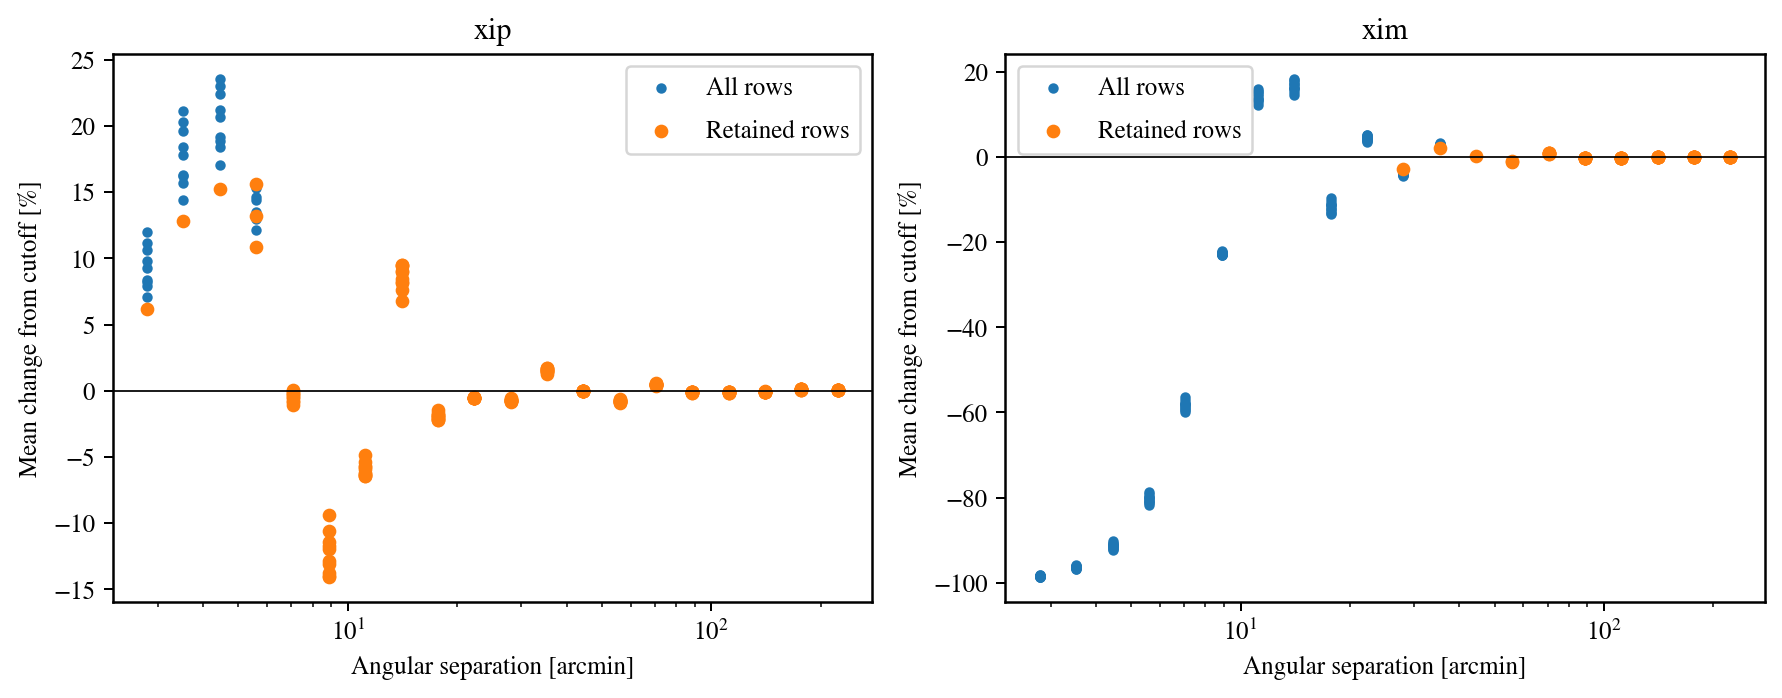

In [48]:
# Pair order is (00,01,02,03,11,12,13,22,23,33). The numbers below are
# scientific input cuts, not an allocation or an ensemble-size setting.
# Source: cosmosis-standard-library/examples/des-y3-scale-cuts.ini,
# inspected 22 November 2026. No download is needed to rerun this cell.
minimum_plus = [2.475, 6.21691892, 6.21691892, 4.93827423, 6.21691892,
                6.21691892, 6.21691892, 6.21691892, 6.21691892, 4.93827423]
minimum_minus = [24.75, 62.16918918, 62.16918918, 49.3827423, 62.16918918,
                 78.26637209, 78.26637209, 78.26637209, 78.26637209, 62.16918918]
saved = np.load(folder / 'cutoff_xi.npz')
angle = saved['angles'][:, 2]*180*60/np.pi
keep = np.zeros(len(angle), dtype=bool)
pairs = [(i, j) for i in range(4) for j in range(i, 4)]
for index, pair in enumerate(pairs):
    same_pair = np.all(saved['bins'][:, :2] == pair, axis=1)
    keep |= same_pair & (saved['kind'] == 'xip') & (angle >= minimum_plus[index])
    keep |= same_pair & (saved['kind'] == 'xim') & (angle >= minimum_minus[index])
assert np.count_nonzero(keep) == 227
print('Rows kept by the public Y3 cuts:', np.count_nonzero(keep))
np.savetxt(folder / 'public_y3_scale_mask.txt', keep.astype(int), fmt='%d')
relative = saved['mean'][0]/saved['mean'][-1] - 1.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, kind in zip(axes, ('xip', 'xim')):
    use = saved['kind'] == kind
    axis.scatter(angle[use], 100*relative[use], s=10, label='All rows')
    axis.scatter(angle[use & keep], 100*relative[use & keep], s=20, label='Retained rows')
    axis.axhline(0., color='black', linewidth=.7)
    axis.set_xscale('log')
    axis.set_xlabel('Angular separation [arcmin]')
    axis.set_ylabel('Mean change from cutoff [%]')
    axis.set_title(kind)
    axis.legend()
    print(kind, 'retained maximum fractional change:', np.max(np.abs(relative[use & keep])))
fig.tight_layout()
fig.savefig(folder / 'cutoff_mean.png', dpi=160)

### Check the angular integral independently

A separate SciPy Bessel integral includes the cutoff as an exact endpoint.
Halving the ell step checks numerical integration at fixed physical support.


In [49]:
from scipy.special import jv, roots_legendre
from scipy.integrate import simpson

# Check selected rows independently of the native xi quadrature. Starting
# at ell=2 avoids taking log of the zero spin-two spectrum at ell=1.
info = yaml_load_file(str(folder / 'k40_theory.yaml'))
with get_model(info_or_yaml_or_file=info) as model:
    assert np.isfinite(model.loglikes(params_values=point, return_derived=False)).all()
    sample_ell = np.geomspace(2., 40000., 8192)
    sample_e, _ = ci.shear_power_rows(
        ell=sample_ell,
        bins=np.array([[0, 0], [3, 3]], dtype=np.int32),
    )
u, w = roots_legendre(64)
saved = np.load(folder / 'cutoff_xi.npz')
checks = []
for source, kind, row_number in [(3, 'xip', 0), (3, 'xim', 0), (3, 'xip', 4), (0, 'xim', 10)]:
    same_pair = np.all(saved['bins'][:, :2] == [source, source], axis=1)
    rows = np.flatnonzero((saved['kind'] == kind) & same_pair)
    lo, hi = saved['angles'][rows[row_number], :2]
    theta = (hi-lo)*u/2 + (hi+lo)/2
    # Uniform area means probability proportional to theta dtheta.
    weight = w*theta*(hi-lo)/(hi**2-lo**2)
    for step in (2., 1.):
        values = []
        for upper in (float(LMAX), 40000.):
            ell = np.r_[np.arange(2., upper, step), upper]
            spectrum = np.exp(np.interp(
                np.log(ell),
                np.log(sample_ell),
                np.log(sample_e[0 if source == 0 else 1]),
            ))
            order = 0 if kind == 'xip' else 4
            kernel = sum(wt*jv(order, ell*t) for t, wt in zip(theta, weight))
            values.append(simpson(ell*spectrum*kernel/(2*np.pi), x=ell))
        checks.append([source, order, lo, hi, step, *values, values[0]/values[1]-1])
np.savetxt(
    folder / 'cutoff_independent.txt',
    checks,
    header='source Bessel_order theta_low_rad theta_high_rad ell_step cutoff_mean full_mean fractional_change',
)
print(np.array(checks))


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[[ 3.00000000e+00  0.00000000e+00  7.27220522e-04  9.15516395e-04
   2.00000000e+00  8.41383448e-05  7.51579674e-05  1.19486699e-01]
 [ 3.00000000e+00  0.00000000e+00  7.27220522e-04  9.15516395e-04
   1.00000000e+00  8.41382977e-05  7.51579203e-05  1.19486774e-01]
 [ 3.00000000e+00  4.00000000e+00  7.27220522e-04  9.15516395e-04
   2.00000000e+00  3.17682778e-07  2.47945383e-05 -9.87187389e-01]
 [ 3.00000000e+00  4.00000000e+00  7.27220522e-04  9.15516395e-04
   1.00000000e+00  3.17682778e-07  2.47945383e-05 -9.87187389e-01]
 [ 3.00000000e+00  0.00000000e+00  1.82669536e-03  2.29967321e-03
   2.00000000e+00  3.44734672e-05  3.48115252e-05 -9.71109300e-03]
 [ 3.00000000e+00  0.00000000e+00  1.82669536e-03  2.29967321e-03
   1.00000000e+00  3.44734202e-05  3.48114781e-05 -9.71110594e-03]
 [ 0.00000000e+00  4.00000000e+00  7.27220522e-03  9.15516395e-03
   2.00000000e+00  7.19194371e-07  7.40571445e-07 -2.88656467e-02]
 [ 0.00000000e+00  4.00000000e+00  7.27220522e-03  9.15516395e-03
   

### Write the transfer package

This defines the accepted controlled model. It does not claim that its
prescribed point functions match high-resolution DES non-Gaussianity. The
footprint inherits the supplied coarse boundary. The package stores noise
at the output resolution already: generation must not multiply it by the
resolution ratio again. Copy the three named files, not the old ensemble,
to the HPC calibration directory. Keep the output ensemble separate.

In [50]:
import hashlib
from generate_maps import setup
record=yaml.safe_load((PROJECT/'tests/gptg_pilot/calibration.yaml').read_text())
parameters=np.array(record['point_parameters_a1_a2_b_x0_t'])
noise=NSIDE//512*np.array(record['noise_sigma_per_component'])
cl=np.load(folder/'k40_power.npz')['cl_target']
# Noise and footprint are supplied at the output NSIDE in this new package.
# The generator therefore must not rescale the noise a second time.
indices = setup(
    lmax=LMAX,
    nside=NSIDE,
    indices=np.load(PROJECT / 'chains/rafael/maps_cov_512_v2/indices_512.npy'),
    index_nside=512,
)[0]
np.save(folder/f'indices_{NSIDE}.npy',indices)
np.savez(folder/'calibration.npz',cl_target=cl,parameters=parameters,noise_sigma=noise)
metadata={
 'method':'Controlled GPTG benchmark: Cocoa gravity-only power and prescribed point transformations',
 'purpose':'Test fixed-analytical-xi covariance with corrections to xi-Map3 and Map3-Map3 only',
 'nside':NSIDE,'lmax':LMAX,'workers':4,
 'second_component_sign_for_ducc':1.,
 'cosmology':{'omegam':.26,'omegab':.0493,'H0':67.3,'ns':.9649,'sigma8':.84,'mnu':.06,'w':-1.,'wa':0.},
 'theory':'CAMB Takahashi halofit through Cocoa/Cobaya; no IA or baryonic response',
 'source_distribution':'data/demonstration/y3_demo_sources.fits, existing recorded clipping and normalization',
 'power_definition':'Convergence power obtained from core shear power using the spherical spin factor; zero signal above lmax',
 'point_model':'Prescribed parameters from tests/gptg_pilot/calibration.yaml; NOT a fit of high-resolution noiseless DES maps',
 'point_parameters_a1_a2_b_x0_t':parameters.tolist(),
 'noise_model':'Independent Gaussian per source and component on retained pixels',
 'noise_sigma_per_component':noise.tolist(),
 'noise_origin':f'Original fitted NSIDE512 amplitudes multiplied by {NSIDE//512} to preserve angular white-noise power',
 'footprint':'RING child pixels of the supplied indices_512.npy; boundary inherited from the coarse mask',
 'pixel_definition':'Point-sampled shear; no extra HEALPix pixel window applied to the theory',
 'storage':'float32; transforms and point evaluation float64',
 'covariance_neutrinos':'Use mnu=0 with the same total omega_m=0.26, including the map neutrino contribution; maps retain mnu=0.06',
 'covariance_scope':'A=Gaussian+SSC+cNG fixed and analytical; only B=cross and D=Map3 are corrected',
 'validation_status':'Numerically checked controlled band-limited model; not validated reproduction of DES small-scale covariance',
 'power_file_sha256':hashlib.sha256((folder/'k40_power.npz').read_bytes()).hexdigest(),
 'point_record_sha256':hashlib.sha256((PROJECT/'tests/gptg_pilot/calibration.yaml').read_bytes()).hexdigest(),
}
(folder/'calibration.yaml').write_text(yaml.safe_dump(metadata,sort_keys=False))
print(f'Transfer calibration.yaml, calibration.npz and indices_{NSIDE}.npy from', folder)

Transfer calibration.yaml, calibration.npz and indices_1024.npy from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/chains/gptg_laptop/gptg_physical_l2048


### Compute the fixed analytical two-point block

Use the existing DES Y3 covariance interface. Total Omega_m is unchanged;
only the covariance's neutrino mass is set to zero. Match sigma8 by obtaining
its primordial amplitude from Cobaya. Use the same normalized source shapes,
footprint area and angular white-noise power. The result contains Gaussian,
SSC and connected non-Gaussian terms. It is fixed by assumption in PME.

This ordinary analytical result retains its full signal integral. The maps'
signal cutoff and the prescribed GPTG connected moments are separate model
choices, explicitly recorded. The calculation below does not establish
that the analytical block equals the GPTG population covariance.

In [51]:
# Call the established covariance adapter rather than create another
# covariance implementation in this project notebook.
# Obtain the primordial amplitude for the explicitly approved massless
# approximation at the same total Omega_m and sigma8 as the map model.
info = yaml_load_file(str(folder / 'k40_theory.yaml'))
info['params']['mnu'] = 0.
info['likelihood']['des_3pcf.joint_shear']['omp_threads'] = min(3, THREADS)
point = yaml_load_file(str(PROJECT / 'EXAMPLE_EVALUATE3.yaml'))['sampler']['evaluate']['override']
# The map cosmology. Its sigma8 = 0.84 is set inside each model below,
# through As_1e9 (point_at_sigma8), because sigma8 is derived.
point.update(
    omegam=0.26,
    omegab=0.0493,
    H0=67.3,
    ns=0.9649,
    DES_A1_1=0.,
    DES_A1_2=0.,
    DES_M1=0.,
    DES_M2=0.,
    DES_M3=0.,
    DES_M4=0.,
)
with get_model(info_or_yaml_or_file=info) as model:
    point = point_at_sigma8(model=model, point=point, sigma8=.84)
    loglike = model.loglikes(params_values=point, return_derived=False, as_dict=True)
    assert np.isfinite(list(loglike.values())).all()
    primordial = 1.e-9 * point['As_1e9']
print('Massless approximation As', primordial, flush=True)
np.savetxt(folder/'massless_As.txt', [primordial])
# Use the existing DES Y3 covariance adapter, selecting its shear rows.
# No new covariance prescription or neutrino implementation is introduced.
sys.path.insert(0, str(ROOT / 'projects/des_y3/interface'))
sys.path.insert(0, str(ROOT / 'projects/des_y3/covariance'))
import cosmolike_des_y3_interface as interface
sys.path.insert(0, str(ROOT / 'external_modules/code/cosmolike_core'))
import des_y3_covariance as survey
from cosmolike_notebook_utils.covariance.forecast import save_forecast
from cosmolike_notebook_utils.covariance.survey import observable_rows
settings = survey.configuration()
settings['cosmology'].update(
    omegam=.26,  # TOTAL matter: do not subtract the map neutrino fraction.
    omegab=.0493,
    H0=67.3,
    ns=.9649,
    As_1e9=primordial*1.e9,
    mnu=0.,
    kmax=40.,
    AccuracyBoost=2.,
)
power = np.load(folder / 'k40_power.npz')
source_file = folder / 'source_nz.txt'
np.savetxt(source_file, np.column_stack((power['source_z'], power['sources'].T)))
settings['source_file'] = str(source_file)
settings['photoz_interpolation'] = 1
settings['photoz_zmid'] = 1
record = yaml.safe_load((folder / 'calibration.yaml').read_text())
pixel_area_sr = 4*np.pi/(12*record['nside']**2)
indices = np.load(folder / f'indices_{NSIDE}.npy', mmap_mode='r')
settings['area_deg2'] = len(indices)*pixel_area_sr*(180/np.pi)**2
# Covariance noise is sigma_e^2 / density_per_steradian. With unit density
# per arcmin^2, this sigma_e produces exactly the map's white-noise power.
settings['source_density_arcmin2'] = [1., 1., 1., 1.]
settings['sigma_e_component'] = (
    np.array(record['noise_sigma_per_component'])*np.sqrt(pixel_area_sr)*180*60/np.pi
).tolist()
settings['benchmark_note'] = ('Map mnu=0.06 eV; covariance mnu=0; same total Omega_m=0.26. '
    'Analytical A held fixed, never corrected with simulations. Full covariance '
    'uses ordinary untruncated theory and circular equal-area window; maps retain ell<=4096.')
interface.set_omp_threads(n=min(3, THREADS))
started = time.monotonic()
survey.initialize(interface=interface, settings=settings)
rows = observable_rows(nlens=5, nsource=4)[:20]
result = survey.compute(
    interface=interface,
    settings=settings,
    rows=rows,
    backend=interface.covariance,
    progress=lambda stage, elapsed: print(stage, elapsed, flush=True),
)
save_forecast(result=result, filename=folder/'analytical_A.npz')
assert result['total'].shape == (400,400)
assert np.isfinite(result['total']).all()
np.linalg.cholesky(result['total'])
print('PASS full analytical A', time.monotonic()-started, 'seconds', flush=True)
print('same total Omega_m', settings['cosmology']['omegam'], 'mnu', settings['cosmology']['mnu'],
      'area',settings['area_deg2'], 'sigma_e',settings['sigma_e_component'], flush=True)

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


Massless approximation As 2.952366241097909e-09


all_pairs_gaussian_spectra 9.45088337501511


angular_and_mask_geometry 11.349186833016574


gaussian_blocks 12.820390333188698


observable_signal 12.89091729116626


... (22 outputs left out)

ssc_and_connected_projection 190.35526366601698


total 190.35641975002363


PASS full analytical A 196.15368470805697 seconds


same total Omega_m 0.26 mnu 0.0 area 4841.5440761798545 sigma_e [0.24357304670337931, 0.2642281967232904, 0.26198873596262384, 0.3218966517752535]


### Check storage precision at the new resolution

This bounded calculation regenerates one sky in float64, rounds its retained
pixels to float32, then measures both arrays in float64. The aperture
diagnostics use the existing fixed centers and radii; they are not TreeCorr
or the full 480-entry estimator. Each reported denominator is defined in
the code. If the local entry-point pilot exists, its saved pixels must match.
The calculation keeps no additional map file.


In [52]:
import ducc0
from generate_maps import setup, aperture_weights, normalized_transform
record=yaml.safe_load((folder/'calibration.yaml').read_text())
with np.load(folder/'calibration.npz') as f:data={k:f[k] for k in f.files}
indices, geometry, ell, factor, nodes, weights=setup(
    lmax=record['lmax'],
    nside=record['nside'],
    indices=np.load(folder/f'indices_{NSIDE}.npy'),
    index_nside=record['nside'],
)
first, second, _=aperture_weights(indices=indices,nside=record['nside'])
latent=np.load(folder/'closure.npz')['latent']
variance=np.load(folder/'closure.npz')['variance']
eigenvalues,eigenvectors=np.linalg.eigh(latent)
# This is the production root convention, not a different seeded sky.
roots=eigenvectors*np.sqrt(np.maximum(eigenvalues,0.))[:,None,:]
rng=np.random.default_rng(seed=341104759)
white=(rng.normal(size=(len(ell),4))+1j*rng.normal(size=(len(ell),4)))/np.sqrt(2.)
white[:record['lmax']+1]=np.sqrt(2.)*white[:record['lmax']+1].real
alms=np.einsum('nij,nj->ni',roots[ell],white).T
pilot_file = folder / 'entrypoint_pilot/comparison/GPTG_DES_000000.npy'
original = np.load(pilot_file, mmap_mode='r') if pilot_file.exists() else None
checks=[]
for source in range(4):
    gaussian = ducc0.sht.synthesis(
        alm=alms[source:source+1],
        spin=0,
        lmax=record['lmax'],
        nthreads=THREADS,
        **geometry,
    )
    kappa=np.sqrt(variance[source])*normalized_transform(gaussian,data['parameters'][source],nodes,weights)
    result = ducc0.sht.pseudo_analysis(
        map=kappa,
        spin=0,
        lmax=record['lmax'],
        maxiter=30,
        epsilon=1.e-6,
        nthreads=THREADS,
        **geometry,
    )
    assert result[1] in (1,2)
    shear = ducc0.sht.synthesis(
        alm=result[0]*factor,
        spin=2,
        mode='GRAD_ONLY',
        lmax=record['lmax'],
        nthreads=THREADS,
        **geometry,
    )[:, indices]
    shear[1]*=record['second_component_sign_for_ducc']
    shear+=data['noise_sigma'][source]*rng.normal(size=shear.shape)
    # Round only for storage, then decode before every measurement.
    # Never divide by a cubic moment that might be nearly zero: normalize
    # square/cube changes by the aperture RMS to the appropriate power.
    rounded=shear.astype(np.float32)
    if original is not None:
        np.testing.assert_array_equal(rounded, original[source])
    decoded=rounded.astype(np.float64)
    delta=decoded-shear
    raw_aperture=(first@shear[0]+second@shear[1]).reshape(2,64)
    saved_aperture=(first@decoded[0]+second@decoded[1]).reshape(2,64)
    for radius in range(2):
        raw=raw_aperture[radius];saved=saved_aperture[radius]
        scale=np.sqrt(np.mean(raw**2))
        row=[source,radius,np.sqrt(np.mean(delta**2))/data['noise_sigma'][source],
             np.max(np.abs(delta))/data['noise_sigma'][source],
             np.max(np.abs(saved-raw))/scale,
             abs(np.mean(saved**2)-np.mean(raw**2))/scale**2,
             abs(np.mean(saved**3)-np.mean(raw**3))/scale**3]
        checks.append(row)
    print('Source', source, 'storage checks:', checks[-2:])
np.savetxt(folder/'float32_storage.txt',checks,header='source radius_index rms_pixel_change_over_noise max_pixel_change_over_noise max_aperture_change_over_rms square_change_over_rms2 cube_change_over_rms3')
print('Maximum normalized rounding changes:', np.max(np.array(checks)[:, 2:], axis=0))
print('Saved-pilot equality checked:', original is not None)


Source 0 storage checks: [[0, 0, 2.5365021911659926e-08, 2.099221925404456e-07, 5.183652159423247e-08, 6.305525964498152e-10, 4.755462280096028e-09], [0, 1, 2.5365021911659926e-08, 2.099221925404456e-07, 5.859913261084503e-08, 3.435835671158467e-09, 6.2494731848700424e-09]]


Source 1 storage checks: [[1, 0, 2.5351062469488968e-08, 1.9374389234865533e-07, 5.364135393409459e-08, 2.986286078501544e-09, 1.2452791619726868e-08], [1, 1, 2.5351062469488968e-08, 1.9374389234865533e-07, 5.8797004959086785e-08, 5.720039206152778e-10, 2.1448870227047176e-09]]


Source 2 storage checks: [[2, 0, 2.5398469662823075e-08, 1.9538629068090095e-07, 4.464320851726462e-08, 2.467346204966883e-09, 1.0777212798319695e-08], [2, 1, 2.5398469662823075e-08, 1.9538629068090095e-07, 3.7176040076724735e-08, 6.9346205701847856e-09, 3.5693695380010218e-09]]


Source 3 storage checks: [[3, 0, 2.5334878710160217e-08, 1.5903329152108036e-07, 5.154255260839199e-08, 3.489027889327869e-09, 2.2554649994167627e-09], [3, 1, 2.5334878710160217e-08, 1.5903329152108036e-07, 3.937118137568183e-08, 3.369203507502047e-09, 3.430623238156286e-09]]
Maximum normalized rounding changes: [2.53984697e-08 2.09922193e-07 5.87970050e-08 6.93462057e-09
 1.24527916e-08]
Saved-pilot equality checked: False


### Bounded numerical pilot and production readiness

For an actual generation pilot, use the same MPI entry point as production
with one process and reduced counts (README). Inspect the resulting float32
map, then rerun that command to verify that completed IDs are skipped.
The kernel pilot and one-versus-four-thread check are recorded in the
physical-calibration test record. Generation makes only inexpensive aperture
journals; it does not run TreeCorr or certify the finite-triangle estimator.

The calibration is ready for a controlled band-limited ensemble. The cutoff
check above remains a limitation for reproducing the published smallest-scale
measurements. Keep comparison and validation seeds separate, freeze the starting
reference before validation, and correct only B and D. Do not reuse legacy
mixed-source TreeCorr outputs with the repaired estimator.
The existing full-vector TreeCorr driver still selects NSIDE512 geometry.
Its new-resolution measurement configuration needs a separate validation;
these generation checks do not establish it.
